# Cross-Channel Adversarial Transfer and Adaptive Robustness of ML-Based BB84 QKD Attack Detection

Full experiment notebook: BB84 simulation, Random Forest detector, simulator-consistent adversarial search, cross-channel transfer, channel-diverse adversarial training, and final validation (fresh confirmatory set, ten-seed stability, adaptive attack).

Run the first code cell first. Trained models must be placed in `models/` (see the repository README).

In [ ]:
# Project path setup — works in Google Colab and locally.
# Locally: run this notebook from the notebooks/ folder of the repository.
import os
try:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_PATH = "/content/drive/MyDrive/Adversarial_QKD_Attack"
except ImportError:
    PROJECT_PATH = os.path.abspath("..")  # repository root
print("PROJECT_PATH =", PROJECT_PATH)


In [ ]:
import os

# PROJECT_PATH is set in the first cell
folders = [
    "notebooks",
    "data",
    "models",
    "results",
    "figures",
    "configs"
]

os.makedirs(PROJECT_PATH, exist_ok=True)

for folder in folders:
    os.makedirs(os.path.join(PROJECT_PATH, folder), exist_ok=True)

print("Project folders created successfully.")
print(PROJECT_PATH)

Project folders created successfully.
/content/drive/MyDrive/Adversarial_QKD_Attack


In [ ]:
import numpy as np
import pandas as pd
import os


# BB84 IDEAL BASELINE


SEED = 20261004
N_BITS = 100_000

rng = np.random.default_rng(SEED)

alice_bits = rng.integers(0, 2, size=N_BITS)

alice_bases = rng.integers(0, 2, size=N_BITS)

bob_bases = rng.integers(0, 2, size=N_BITS)

matching_bases = alice_bases == bob_bases

alice_sifted = alice_bits[matching_bases]

bob_sifted = alice_sifted.copy()

errors = np.sum(alice_sifted != bob_sifted)

qber = errors / len(alice_sifted) if len(alice_sifted) > 0 else 0

sifted_ratio = len(alice_sifted) / N_BITS

print("===== IDEAL BB84 VALIDATION =====")
print(f"Transmitted bits : {N_BITS:,}")
print(f"Sifted bits      : {len(alice_sifted):,}")
print(f"Sifted ratio     : {sifted_ratio:.2%}")
print(f"Errors           : {errors}")
print(f"QBER             : {qber:.2%}")


summary = pd.DataFrame([{
    "experiment": "Ideal_BB84",
    "seed": SEED,
    "transmitted_bits": N_BITS,
    "sifted_bits": len(alice_sifted),
    "sifted_ratio": sifted_ratio,
    "errors": errors,
    "qber": qber
}])

output_file = os.path.join(
    PROJECT_PATH,
    "results",
    "ideal_bb84_summary.csv"
)

summary.to_csv(output_file, index=False)

print("\nSaved successfully:")
print(output_file)

===== IDEAL BB84 VALIDATION =====
Transmitted bits : 100,000
Sifted bits      : 49,721
Sifted ratio     : 49.72%
Errors           : 0
QBER             : 0.00%

Saved successfully:
/content/drive/MyDrive/Adversarial_QKD_Attack/results/ideal_bb84_summary.csv


In [ ]:
# BB84 VALIDATION 2 — CHANNEL LOSS ONLY

import numpy as np
import pandas as pd
import os

SEED = 20261004
N_BITS = 100_000
LOSS_RATE = 0.30

rng = np.random.default_rng(SEED)

alice_bits = rng.integers(0, 2, size=N_BITS)
alice_bases = rng.integers(0, 2, size=N_BITS)

bob_bases = rng.integers(0, 2, size=N_BITS)

# CHANNEL LOSS

detected = rng.random(N_BITS) >= LOSS_RATE

detected_bits = np.sum(detected)


sift_mask = detected & (alice_bases == bob_bases)

alice_sifted = alice_bits[sift_mask]

bob_sifted = alice_sifted.copy()


errors = np.sum(alice_sifted != bob_sifted)

qber = (
    errors / len(alice_sifted)
    if len(alice_sifted) > 0
    else 0
)

detection_rate = detected_bits / N_BITS
actual_loss_rate = 1 - detection_rate
sifted_ratio = len(alice_sifted) / N_BITS

print("===== BB84 LOSS-ONLY VALIDATION =====")
print(f"Transmitted bits  : {N_BITS:,}")
print(f"Target loss       : {LOSS_RATE:.2%}")
print(f"Actual loss       : {actual_loss_rate:.2%}")
print(f"Detected bits     : {detected_bits:,}")
print(f"Detection rate    : {detection_rate:.2%}")
print(f"Sifted bits       : {len(alice_sifted):,}")
print(f"Sifted ratio      : {sifted_ratio:.2%}")
print(f"Errors            : {errors}")
print(f"QBER              : {qber:.2%}")

summary = pd.DataFrame([{
    "experiment": "BB84_Loss_Only",
    "seed": SEED,
    "transmitted_bits": N_BITS,
    "target_loss_rate": LOSS_RATE,
    "actual_loss_rate": actual_loss_rate,
    "detected_bits": detected_bits,
    "detection_rate": detection_rate,
    "sifted_bits": len(alice_sifted),
    "sifted_ratio": sifted_ratio,
    "errors": errors,
    "qber": qber
}])

output_file = os.path.join(
    PROJECT_PATH,
    "results",
    "bb84_loss_only_summary.csv"
)

summary.to_csv(output_file, index=False)

print("\nSaved successfully:")
print(output_file)

===== BB84 LOSS-ONLY VALIDATION =====
Transmitted bits  : 100,000
Target loss       : 30.00%
Actual loss       : 30.16%
Detected bits     : 69,842
Detection rate    : 69.84%
Sifted bits       : 34,612
Sifted ratio      : 34.61%
Errors            : 0
QBER              : 0.00%

Saved successfully:
/content/drive/MyDrive/Adversarial_QKD_Attack/results/bb84_loss_only_summary.csv


In [ ]:
# BB84 VALIDATION 3 — NOISE ONLY

import numpy as np
import pandas as pd
import os

SEED = 20261004
N_BITS = 100_000

NOISE_RATE = 0.02

rng = np.random.default_rng(SEED)

alice_bits = rng.integers(0, 2, size=N_BITS)
alice_bases = rng.integers(0, 2, size=N_BITS)


bob_bases = rng.integers(0, 2, size=N_BITS)

detected = np.ones(N_BITS, dtype=bool)


noise_mask = rng.random(N_BITS) < NOISE_RATE

received_bits = alice_bits.copy()

received_bits[noise_mask] = 1 - received_bits[noise_mask]



matching_bases = alice_bases == bob_bases

sift_mask = detected & matching_bases

alice_sifted = alice_bits[sift_mask]
bob_sifted = received_bits[sift_mask]


errors = np.sum(alice_sifted != bob_sifted)

qber = (
    errors / len(alice_sifted)
    if len(alice_sifted) > 0
    else 0
)

detected_bits = np.sum(detected)

detection_rate = detected_bits / N_BITS

sifted_ratio = len(alice_sifted) / N_BITS

actual_noise_all_bits = np.mean(noise_mask)


print("===== BB84 NOISE-ONLY VALIDATION =====")
print(f"Transmitted bits   : {N_BITS:,}")
print(f"Target noise       : {NOISE_RATE:.2%}")
print(f"Actual noise       : {actual_noise_all_bits:.2%}")
print(f"Detected bits      : {detected_bits:,}")
print(f"Detection rate     : {detection_rate:.2%}")
print(f"Sifted bits        : {len(alice_sifted):,}")
print(f"Sifted ratio       : {sifted_ratio:.2%}")
print(f"Errors             : {errors:,}")
print(f"QBER               : {qber:.2%}")

summary = pd.DataFrame([{
    "experiment": "BB84_Noise_Only",
    "seed": SEED,
    "transmitted_bits": N_BITS,
    "target_noise_rate": NOISE_RATE,
    "actual_noise_rate": actual_noise_all_bits,
    "detected_bits": detected_bits,
    "detection_rate": detection_rate,
    "sifted_bits": len(alice_sifted),
    "sifted_ratio": sifted_ratio,
    "errors": errors,
    "qber": qber
}])

output_file = os.path.join(
    PROJECT_PATH,
    "results",
    "bb84_noise_only_summary.csv"
)

summary.to_csv(output_file, index=False)

print("\nSaved successfully:")
print(output_file)

===== BB84 NOISE-ONLY VALIDATION =====
Transmitted bits   : 100,000
Target noise       : 2.00%
Actual noise       : 2.00%
Detected bits      : 100,000
Detection rate     : 100.00%
Sifted bits        : 49,721
Sifted ratio       : 49.72%
Errors             : 994
QBER               : 2.00%

Saved successfully:
/content/drive/MyDrive/Adversarial_QKD_Attack/results/bb84_noise_only_summary.csv


In [ ]:
# BB84 VALIDATION 4 — NOISE + LOSS

import numpy as np
import pandas as pd
import os

SEED = 20261004
N_BITS = 100_000

NOISE_RATE = 0.02
LOSS_RATE = 0.30

rng = np.random.default_rng(SEED)


alice_bits = rng.integers(0, 2, size=N_BITS)
alice_bases = rng.integers(0, 2, size=N_BITS)


bob_bases = rng.integers(0, 2, size=N_BITS)


detected = rng.random(N_BITS) >= LOSS_RATE


noise_mask = rng.random(N_BITS) < NOISE_RATE

received_bits = alice_bits.copy()

received_bits[noise_mask] = 1 - received_bits[noise_mask]

matching_bases = alice_bases == bob_bases

sift_mask = detected & matching_bases

alice_sifted = alice_bits[sift_mask]
bob_sifted = received_bits[sift_mask]


detected_bits = np.sum(detected)

detection_rate = detected_bits / N_BITS
actual_loss_rate = 1 - detection_rate

sifted_bits = len(alice_sifted)
sifted_ratio = sifted_bits / N_BITS

errors = np.sum(alice_sifted != bob_sifted)

qber = (
    errors / sifted_bits
    if sifted_bits > 0
    else 0
)

actual_noise_rate = np.mean(noise_mask)


print("===== BB84 NOISE + LOSS VALIDATION =====")
print(f"Transmitted bits   : {N_BITS:,}")
print(f"Target noise       : {NOISE_RATE:.2%}")
print(f"Actual noise       : {actual_noise_rate:.2%}")
print(f"Target loss        : {LOSS_RATE:.2%}")
print(f"Actual loss        : {actual_loss_rate:.2%}")
print(f"Detected bits      : {detected_bits:,}")
print(f"Detection rate     : {detection_rate:.2%}")
print(f"Sifted bits        : {sifted_bits:,}")
print(f"Sifted ratio       : {sifted_ratio:.2%}")
print(f"Errors             : {errors:,}")
print(f"QBER               : {qber:.2%}")


# SAVE RESULT


summary = pd.DataFrame([{
    "experiment": "BB84_Noise_Loss",
    "seed": SEED,
    "transmitted_bits": N_BITS,
    "target_noise_rate": NOISE_RATE,
    "actual_noise_rate": actual_noise_rate,
    "target_loss_rate": LOSS_RATE,
    "actual_loss_rate": actual_loss_rate,
    "detected_bits": detected_bits,
    "detection_rate": detection_rate,
    "sifted_bits": sifted_bits,
    "sifted_ratio": sifted_ratio,
    "errors": errors,
    "qber": qber
}])

output_file = os.path.join(
    PROJECT_PATH,
    "results",
    "bb84_noise_loss_summary.csv"
)

summary.to_csv(output_file, index=False)

print("\nSaved successfully:")
print(output_file)

===== BB84 NOISE + LOSS VALIDATION =====
Transmitted bits   : 100,000
Target noise       : 2.00%
Actual noise       : 1.96%
Target loss        : 30.00%
Actual loss        : 30.16%
Detected bits      : 69,842
Detection rate     : 69.84%
Sifted bits        : 34,612
Sifted ratio       : 34.61%
Errors             : 708
QBER               : 2.05%

Saved successfully:
/content/drive/MyDrive/Adversarial_QKD_Attack/results/bb84_noise_loss_summary.csv


In [ ]:
# BB84 VALIDATION 5 — EVE INTERCEPT-RESEND

import numpy as np
import pandas as pd
import os

SEED = 20261004
N_BITS = 100_000

EVE_RATES = [0.0, 0.50, 1.0]

results = []

for eve_rate in EVE_RATES:

    rng = np.random.default_rng(
        SEED + int(eve_rate * 100)
    )


    # ALICE


    alice_bits = rng.integers(0, 2, size=N_BITS)
    alice_bases = rng.integers(0, 2, size=N_BITS)


    # EVE

    eve_intercepts = rng.random(N_BITS) < eve_rate

    eve_bases = rng.integers(0, 2, size=N_BITS)

    transmitted_bits_after_eve = alice_bits.copy()

    eve_wrong_basis = (
        eve_intercepts &
        (eve_bases != alice_bases)
    )

    random_measurements = rng.integers(
        0,
        2,
        size=N_BITS
    )

    transmitted_bits_after_eve[eve_wrong_basis] = \
        random_measurements[eve_wrong_basis]


    # BOB

    bob_bases = rng.integers(0, 2, size=N_BITS)

    bob_received_bits = transmitted_bits_after_eve.copy()

    state_bases = alice_bases.copy()
    state_bases[eve_intercepts] = eve_bases[eve_intercepts]

    bob_wrong_basis = bob_bases != state_bases

    random_bob_measurements = rng.integers(
        0,
        2,
        size=N_BITS
    )

    bob_received_bits[bob_wrong_basis] = \
        random_bob_measurements[bob_wrong_basis]

    # SIFTING
    sift_mask = alice_bases == bob_bases

    alice_sifted = alice_bits[sift_mask]
    bob_sifted = bob_received_bits[sift_mask]


    sifted_bits = len(alice_sifted)

    errors = np.sum(
        alice_sifted != bob_sifted
    )

    qber = (
        errors / sifted_bits
        if sifted_bits > 0
        else 0
    )

    sifted_ratio = sifted_bits / N_BITS

    expected_qber = 0.25 * eve_rate

    results.append({
        "eve_rate": eve_rate,
        "expected_qber": expected_qber,
        "actual_qber": qber,
        "transmitted_bits": N_BITS,
        "sifted_bits": sifted_bits,
        "sifted_ratio": sifted_ratio,
        "errors": errors
    })

    print("=" * 50)
    print(f"EVE INTERCEPT RATE : {eve_rate:.0%}")
    print("=" * 50)

    print(f"Transmitted bits   : {N_BITS:,}")
    print(f"Sifted bits        : {sifted_bits:,}")
    print(f"Sifted ratio       : {sifted_ratio:.2%}")
    print(f"Errors             : {errors:,}")
    print(f"Expected QBER      : {expected_qber:.2%}")
    print(f"Actual QBER        : {qber:.2%}")

    print()


eve_results = pd.DataFrame(results)

output_file = os.path.join(
    PROJECT_PATH,
    "results",
    "bb84_eve_validation.csv"
)

eve_results.to_csv(
    output_file,
    index=False
)

print("Saved successfully:")
print(output_file)

EVE INTERCEPT RATE : 0%
Transmitted bits   : 100,000
Sifted bits        : 50,084
Sifted ratio       : 50.08%
Errors             : 0
Expected QBER      : 0.00%
Actual QBER        : 0.00%

EVE INTERCEPT RATE : 50%
Transmitted bits   : 100,000
Sifted bits        : 50,034
Sifted ratio       : 50.03%
Errors             : 6,149
Expected QBER      : 12.50%
Actual QBER        : 12.29%

EVE INTERCEPT RATE : 100%
Transmitted bits   : 100,000
Sifted bits        : 49,940
Sifted ratio       : 49.94%
Errors             : 12,504
Expected QBER      : 25.00%
Actual QBER        : 25.04%

Saved successfully:
/content/drive/MyDrive/Adversarial_QKD_Attack/results/bb84_eve_validation.csv


In [ ]:
# REUSABLE BB84 SIMULATOR
# Supports:
# - Channel noise
# - Channel loss
# - Eve intercept-resend attak

import numpy as np


def simulate_bb84(
    n_bits=100_000,
    noise_rate=0.0,
    loss_rate=0.0,
    eve_rate=0.0,
    seed=20261004
):


    rng = np.random.default_rng(seed)

    # 1. ALICE

    alice_bits = rng.integers(0, 2, size=n_bits)

    alice_bases = rng.integers(0, 2, size=n_bits)

    transmitted_bits = alice_bits.copy()
    state_bases = alice_bases.copy()

    # 2. EVE INTERCEPT-RESEND ATTACK

    eve_intercepts = rng.random(n_bits) < eve_rate

    eve_bases = rng.integers(
        0,
        2,
        size=n_bits
    )

    eve_wrong_basis = (
        eve_intercepts &
        (eve_bases != alice_bases)
    )

    eve_random_results = rng.integers(
        0,
        2,
        size=n_bits
    )

    transmitted_bits[eve_wrong_basis] = \
        eve_random_results[eve_wrong_basis]

    state_bases[eve_intercepts] = \
        eve_bases[eve_intercepts]

    # 3. CHANNEL LOSS

    detected = (
        rng.random(n_bits) >= loss_rate
    )

    # 4. CHANNEL NOISE

    noise_mask = (
        rng.random(n_bits) < noise_rate
    )

    noisy_bits = transmitted_bits.copy()

    noisy_bits[noise_mask] = \
        1 - noisy_bits[noise_mask]

    # 5. BOB


    bob_bases = rng.integers(
        0,
        2,
        size=n_bits
    )

    bob_bits = noisy_bits.copy()

    # Wrong-basis measurement gives random outcome
    bob_wrong_basis = (
        bob_bases != state_bases
    )

    bob_random_results = rng.integers(
        0,
        2,
        size=n_bits
    )

    bob_bits[bob_wrong_basis] = \
        bob_random_results[bob_wrong_basis]

    # 6. SIFTING


    sift_mask = (
        detected &
        (alice_bases == bob_bases)
    )

    alice_sifted = alice_bits[sift_mask]
    bob_sifted = bob_bits[sift_mask]

    transmitted_count = n_bits

    detected_bits = int(
        np.sum(detected)
    )

    sifted_bits = len(
        alice_sifted
    )

    errors = int(
        np.sum(
            alice_sifted != bob_sifted
        )
    )

    detection_rate = (
        detected_bits / n_bits
    )

    actual_loss_rate = (
        1 - detection_rate
    )

    sifted_ratio = (
        sifted_bits / n_bits
    )

    qber = (
        errors / sifted_bits
        if sifted_bits > 0
        else 0.0
    )

    actual_noise_rate = float(
        np.mean(noise_mask)
    )

    actual_eve_rate = float(
        np.mean(eve_intercepts)
    )



    return {
        "transmitted_bits": transmitted_count,

        "target_noise_rate": noise_rate,
        "actual_noise_rate": actual_noise_rate,

        "target_loss_rate": loss_rate,
        "actual_loss_rate": actual_loss_rate,

        "target_eve_rate": eve_rate,
        "actual_eve_rate": actual_eve_rate,

        "detected_bits": detected_bits,
        "detection_rate": detection_rate,

        "sifted_bits": sifted_bits,
        "sifted_ratio": sifted_ratio,

        "errors": errors,
        "qber": qber
    }


print("Reusable BB84 simulator created successfully.")

Reusable BB84 simulator created successfully.


In [ ]:
# VALIDATION 6 — EVE + NOISE + LOSS


test_result = simulate_bb84(
    n_bits=100_000,
    noise_rate=0.02,
    loss_rate=0.30,
    eve_rate=1.00,
    seed=20261004
)

print("===== BB84 EVE + NOISE + LOSS =====")

print(
    f"Transmitted bits : "
    f"{test_result['transmitted_bits']:,}"
)

print(
    f"Detected bits    : "
    f"{test_result['detected_bits']:,}"
)

print(
    f"Detection rate   : "
    f"{test_result['detection_rate']:.2%}"
)

print(
    f"Sifted bits      : "
    f"{test_result['sifted_bits']:,}"
)

print(
    f"Sifted ratio     : "
    f"{test_result['sifted_ratio']:.2%}"
)

print(
    f"Actual loss      : "
    f"{test_result['actual_loss_rate']:.2%}"
)

print(
    f"Actual noise     : "
    f"{test_result['actual_noise_rate']:.2%}"
)

print(
    f"Actual Eve rate  : "
    f"{test_result['actual_eve_rate']:.2%}"
)

print(
    f"Errors           : "
    f"{test_result['errors']:,}"
)

print(
    f"QBER             : "
    f"{test_result['qber']:.2%}"
)

===== BB84 EVE + NOISE + LOSS =====
Transmitted bits : 100,000
Detected bits    : 69,905
Detection rate   : 69.91%
Sifted bits      : 34,786
Sifted ratio     : 34.79%
Actual loss      : 30.10%
Actual noise     : 1.99%
Actual Eve rate  : 100.00%
Errors           : 9,075
QBER             : 26.09%


In [ ]:

# CHANNEL CONFIGURATION —

import json
import os

CHANNEL_CONFIG = {

    "Low": {
        "noise_min": 0.005,
        "noise_max": 0.015,
        "loss_min": 0.05,
        "loss_max": 0.15
    },

    "Medium": {
        "noise_min": 0.02,
        "noise_max": 0.04,
        "loss_min": 0.20,
        "loss_max": 0.35
    },

    "High": {
        "noise_min": 0.05,
        "noise_max": 0.07,
        "loss_min": 0.40,
        "loss_max": 0.55
    },

    "Unseen": {
        "noise_min": 0.08,
        "noise_max": 0.10,
        "loss_min": 0.60,
        "loss_max": 0.70
    }
}

DATASET_CONFIG = {

    "bits_per_session": 10_000,

    "sessions_per_known_channel": 3_000,

    "sessions_unseen": 3_000,

    "normal_fraction": 0.50,

    "attack_fraction": 0.50,

    "attack_eve_min": 0.10,

    "attack_eve_max": 1.00,

    "seed": 20261004
}

# Save configuration permanently to Google Drive

config = {
    "channels": CHANNEL_CONFIG,
    "dataset": DATASET_CONFIG
}

config_file = os.path.join(
    PROJECT_PATH,
    "configs",
    "channel_dataset_config.json"
)

with open(config_file, "w") as f:
    json.dump(config, f, indent=4)

print("===== FINAL CHANNEL CONFIGURATION =====")

for name, values in CHANNEL_CONFIG.items():

    print(
        f"\n{name}: "
        f"Noise {values['noise_min']:.1%}–{values['noise_max']:.1%}, "
        f"Loss {values['loss_min']:.0%}–{values['loss_max']:.0%}"
    )

print("\nDataset configuration:")
print("Known channels    : Low, Medium, High")
print("Known sessions    : 9,000")
print("Unseen sessions   : 3,000")
print("Total sessions    : 12,000")
print("Bits per session  : 10,000")
print("Normal / Attack   : 50% / 50%")

print("\nConfiguration saved:")
print(config_file)

===== FINAL CHANNEL CONFIGURATION =====

Low: Noise 0.5%–1.5%, Loss 5%–15%

Medium: Noise 2.0%–4.0%, Loss 20%–35%

High: Noise 5.0%–7.0%, Loss 40%–55%

Unseen: Noise 8.0%–10.0%, Loss 60%–70%

Dataset configuration:
Known channels    : Low, Medium, High
Known sessions    : 9,000
Unseen sessions   : 3,000
Total sessions    : 12,000
Bits per session  : 10,000
Normal / Attack   : 50% / 50%

Configuration saved:
/content/drive/MyDrive/Adversarial_QKD_Attack/configs/channel_dataset_config.json


In [ ]:
# FINAL BB84 SESSION SIMULATOR
# Produces the QKD telemetry needed for the ML dataset


import numpy as np


def binary_entropy_from_bits(bits):


    if len(bits) == 0:
        return 0.0

    p1 = np.mean(bits)
    p0 = 1.0 - p1

    entropy = 0.0

    for p in [p0, p1]:
        if p > 0:
            entropy -= p * np.log2(p)

    return float(entropy)


def simulate_bb84_session(
    n_bits=10_000,
    noise_rate=0.0,
    loss_rate=0.0,
    eve_rate=0.0,
    seed=20261004,
    n_blocks=20
):

    rng = np.random.default_rng(seed)

    # 1. ALICE
    alice_bits = rng.integers(
        0,
        2,
        size=n_bits
    )

    alice_bases = rng.integers(
        0,
        2,
        size=n_bits
    )

    transmitted_bits = alice_bits.copy()
    state_bases = alice_bases.copy()


    # 2. EVE INTERCEPT-RESEND

    eve_intercepts = (
        rng.random(n_bits) < eve_rate
    )

    eve_bases = rng.integers(
        0,
        2,
        size=n_bits
    )

    eve_wrong_basis = (
        eve_intercepts &
        (eve_bases != alice_bases)
    )

    eve_random_results = rng.integers(
        0,
        2,
        size=n_bits
    )

    transmitted_bits[eve_wrong_basis] = (
        eve_random_results[eve_wrong_basis]
    )

    state_bases[eve_intercepts] = (
        eve_bases[eve_intercepts]
    )

    # 3. CHANNEL LOSS

    detected = (
        rng.random(n_bits) >= loss_rate
    )


    # 4. CHANNEL NOISE

    noise_mask = (
        rng.random(n_bits) < noise_rate
    )

    noisy_bits = transmitted_bits.copy()

    noisy_bits[noise_mask] = (
        1 - noisy_bits[noise_mask]
    )

    # 5. BOB


    bob_bases = rng.integers(
        0,
        2,
        size=n_bits
    )

    bob_bits = noisy_bits.copy()

    bob_wrong_basis = (
        bob_bases != state_bases
    )

    bob_random_results = rng.integers(
        0,
        2,
        size=n_bits
    )

    bob_bits[bob_wrong_basis] = (
        bob_random_results[bob_wrong_basis]
    )


    # 6. BB84 SIFTING

    sift_mask = (
        detected &
        (alice_bases == bob_bases)
    )

    alice_sifted = alice_bits[sift_mask]
    bob_sifted = bob_bits[sift_mask]

    sifted_bases = alice_bases[sift_mask]


    # 7. OVERALL QKD METRICS


    detected_bits = int(
        np.sum(detected)
    )

    detection_rate = (
        detected_bits / n_bits
    )

    sifted_bits = len(alice_sifted)

    sifted_ratio = (
        sifted_bits / n_bits
    )

    if sifted_bits > 0:

        errors = int(
            np.sum(
                alice_sifted != bob_sifted
            )
        )

        qber = (
            errors / sifted_bits
        )

    else:

        errors = 0
        qber = 0.0

    # 8. BASIS-SPECIFIC QBER


    z_mask = (
        sifted_bases == 0
    )

    x_mask = (
        sifted_bases == 1
    )

    if np.sum(z_mask) > 0:

        qber_z = np.mean(
            alice_sifted[z_mask] !=
            bob_sifted[z_mask]
        )

    else:

        qber_z = 0.0

    if np.sum(x_mask) > 0:

        qber_x = np.mean(
            alice_sifted[x_mask] !=
            bob_sifted[x_mask]
        )

    else:

        qber_x = 0.0

    # 9. BLOCK-LEVEL TEMPORAL STATISTICS

    block_indices = np.array_split(
        np.arange(n_bits),
        n_blocks
    )

    block_qbers = []
    block_detection_rates = []

    for indices in block_indices:

        block_detected = detected[indices]

        block_detection_rate = np.mean(
            block_detected
        )

        block_detection_rates.append(
            block_detection_rate
        )

        block_sift_mask = (
            detected[indices] &
            (
                alice_bases[indices] ==
                bob_bases[indices]
            )
        )

        block_alice = (
            alice_bits[indices][block_sift_mask]
        )

        block_bob = (
            bob_bits[indices][block_sift_mask]
        )

        if len(block_alice) > 0:

            block_qber = np.mean(
                block_alice != block_bob
            )

            block_qbers.append(
                block_qber
            )

    qber_block_std = (
        float(np.std(block_qbers))
        if len(block_qbers) > 0
        else 0.0
    )

    detection_block_std = (
        float(np.std(block_detection_rates))
    )

    # 10. SIFTED-KEY ENTROPY


    sifted_entropy = (
        binary_entropy_from_bits(
            bob_sifted
        )
    )

    # RETURN SESSION TELEMETRY


    return {

        "qber": float(qber),

        "detection_rate": float(
            detection_rate
        ),

        "sifted_ratio": float(
            sifted_ratio
        ),

        "qber_z": float(
            qber_z
        ),

        "qber_x": float(
            qber_x
        ),

        "qber_block_std": float(
            qber_block_std
        ),

        "detection_block_std": float(
            detection_block_std
        ),

        "sifted_entropy": float(
            sifted_entropy
        ),

        # Diagnostic values
        "detected_bits": detected_bits,

        "sifted_bits": sifted_bits,

        "errors": errors
    }


print(
    "Final BB84 session simulator created successfully."
)

Final BB84 session simulator created successfully.


In [ ]:
test_session = simulate_bb84_session(
    n_bits=10_000,
    noise_rate=0.01,
    loss_rate=0.10,
    eve_rate=0.0,
    seed=20261004
)

print("===== SAMPLE LOW-CHANNEL NORMAL SESSION =====")

for key, value in test_session.items():

    if isinstance(value, float):
        print(f"{key:25s}: {value:.6f}")

    else:
        print(f"{key:25s}: {value}")

===== SAMPLE LOW-CHANNEL NORMAL SESSION =====
qber                     : 0.010974
detection_rate           : 0.899400
sifted_ratio             : 0.446500
qber_z                   : 0.013218
qber_x                   : 0.008807
qber_block_std           : 0.006822
detection_block_std      : 0.010791
sifted_entropy           : 0.999970
detected_bits            : 8994
sifted_bits              : 4465
errors                   : 49


In [ ]:

# GENERATE FINAL QKD DATASETS
# Low / Medium / High = KNOWN
# Unseen = FINAL HOLDOUT


import numpy as np
import pandas as pd
import os

from tqdm.auto import tqdm

CHANNEL_SEED_OFFSETS = {
    "Low": 100_000,
    "Medium": 200_000,
    "High": 300_000,
    "Unseen": 400_000
}



# DATASET GENERATOR


def generate_channel_dataset(
    channel_name,
    n_sessions,
    save_filename
):

    config = CHANNEL_CONFIG[channel_name]

    base_seed = (
        DATASET_CONFIG["seed"]
        + CHANNEL_SEED_OFFSETS[channel_name]
    )

    rng = np.random.default_rng(base_seed)


    n_normal = n_sessions // 2
    n_attack = n_sessions - n_normal

    labels = np.array(
        [0] * n_normal +
        [1] * n_attack,
        dtype=int
    )

    rng.shuffle(labels)

    rows = []

    # GENERATE EACH BB84 SESSION


    for i, label in enumerate(
        tqdm(
            labels,
            desc=f"Generating {channel_name}"
        )
    ):



        noise_rate = rng.uniform(
            config["noise_min"],
            config["noise_max"]
        )

        loss_rate = rng.uniform(
            config["loss_min"],
            config["loss_max"]
        )


        # NORMAL VS ATTACK

        if label == 0:

            eve_rate = 0.0
            attack_type = "none"

        else:

            eve_rate = rng.uniform(
                DATASET_CONFIG["attack_eve_min"],
                DATASET_CONFIG["attack_eve_max"]
            )

            attack_type = "intercept_resend"


        # UNIQUE SESSION SEED


        session_seed = (
            base_seed
            + i
            + 1
        )


        # RUN BB84
        telemetry = simulate_bb84_session(
            n_bits=DATASET_CONFIG["bits_per_session"],
            noise_rate=noise_rate,
            loss_rate=loss_rate,
            eve_rate=eve_rate,
            seed=session_seed
        )


        # CREATE ONE DATASET ROW


        row = {

            # Session identity
            "session_id":
                f"{channel_name}_{i+1:04d}",

            # Metadata — NOT ML input
            "channel_condition":
                channel_name,

            "attack_type":
                attack_type,

            "target_noise_rate":
                noise_rate,

            "target_loss_rate":
                loss_rate,

            "target_eve_rate":
                eve_rate,

            "session_seed":
                session_seed,


            # ML TELEMETRY FEATURES


            "qber":
                telemetry["qber"],

            "detection_rate":
                telemetry["detection_rate"],

            "sifted_ratio":
                telemetry["sifted_ratio"],

            "qber_z":
                telemetry["qber_z"],

            "qber_x":
                telemetry["qber_x"],

            "qber_block_std":
                telemetry["qber_block_std"],

            "detection_block_std":
                telemetry["detection_block_std"],

            "sifted_entropy":
                telemetry["sifted_entropy"],

            # Diagnostics
            "detected_bits":
                telemetry["detected_bits"],

            "sifted_bits":
                telemetry["sifted_bits"],

            "errors":
                telemetry["errors"],


            # TARGET


            # 0 = Normal
            # 1 = Attack
            "label":
                int(label)
        }

        rows.append(row)



    df = pd.DataFrame(rows)

    # SAVE IMMEDIATELY TO DRIVE


    output_file = os.path.join(
        PROJECT_PATH,
        "data",
        save_filename
    )

    df.to_csv(
        output_file,
        index=False
    )

    print()
    print("=" * 60)
    print(f"{channel_name} DATASET COMPLETE")
    print("=" * 60)

    print(
        f"Total sessions : {len(df):,}"
    )

    print(
        f"Normal         : "
        f"{(df['label'] == 0).sum():,}"
    )

    print(
        f"Attack         : "
        f"{(df['label'] == 1).sum():,}"
    )

    print(
        f"Mean QBER      : "
        f"{df['qber'].mean():.2%}"
    )

    print(
        f"Mean detection : "
        f"{df['detection_rate'].mean():.2%}"
    )

    print(
        f"Saved to       : {output_file}"
    )

    print()

    return df



# GENERATE LOW

low_df = generate_channel_dataset(
    channel_name="Low",
    n_sessions=3000,
    save_filename="low_channel.csv"
)



# GENERATE MEDIUM


medium_df = generate_channel_dataset(
    channel_name="Medium",
    n_sessions=3000,
    save_filename="medium_channel.csv"
)

# GENERATE HIGH


high_df = generate_channel_dataset(
    channel_name="High",
    n_sessions=3000,
    save_filename="high_channel.csv"
)


# GENERATE UNSEEN


unseen_df = generate_channel_dataset(
    channel_name="Unseen",
    n_sessions=3000,
    save_filename="unseen_channel.csv"
)


print("ALL CHANNEL DATASETS GENERATED SUCCESSFULLY.")

Generating Low:   0%|          | 0/3000 [00:00<?, ?it/s]


Low DATASET COMPLETE
Total sessions : 3,000
Normal         : 1,500
Attack         : 1,500
Mean QBER      : 7.73%
Mean detection : 90.08%
Saved to       : /content/drive/MyDrive/Adversarial_QKD_Attack/data/low_channel.csv



Generating Medium:   0%|          | 0/3000 [00:00<?, ?it/s]


Medium DATASET COMPLETE
Total sessions : 3,000
Normal         : 1,500
Attack         : 1,500
Mean QBER      : 9.53%
Mean detection : 72.43%
Saved to       : /content/drive/MyDrive/Adversarial_QKD_Attack/data/medium_channel.csv



Generating High:   0%|          | 0/3000 [00:00<?, ?it/s]


High DATASET COMPLETE
Total sessions : 3,000
Normal         : 1,500
Attack         : 1,500
Mean QBER      : 12.05%
Mean detection : 52.48%
Saved to       : /content/drive/MyDrive/Adversarial_QKD_Attack/data/high_channel.csv



Generating Unseen:   0%|          | 0/3000 [00:00<?, ?it/s]


Unseen DATASET COMPLETE
Total sessions : 3,000
Normal         : 1,500
Attack         : 1,500
Mean QBER      : 14.73%
Mean detection : 35.03%
Saved to       : /content/drive/MyDrive/Adversarial_QKD_Attack/data/unseen_channel.csv

ALL CHANNEL DATASETS GENERATED SUCCESSFULLY.


In [ ]:
# COMBINE LOW + MEDIUM + HIGH INTO KNOWN DATASET
# Keep UNSEEN completely separate

import pandas as pd
import os

known_df = pd.concat(
    [
        low_df,
        medium_df,
        high_df
    ],
    ignore_index=True
)

known_df = known_df.sample(
    frac=1,
    random_state=DATASET_CONFIG["seed"]
).reset_index(drop=True)

known_file = os.path.join(
    PROJECT_PATH,
    "data",
    "known_qkd_dataset.csv"
)

known_df.to_csv(
    known_file,
    index=False
)

print("===== KNOWN QKD DATASET =====")
print(f"Total rows     : {len(known_df):,}")
print(f"Normal samples : {(known_df['label'] == 0).sum():,}")
print(f"Attack samples : {(known_df['label'] == 1).sum():,}")

print("\nChannel counts:")
print(known_df["channel_condition"].value_counts())

print("\nSaved successfully:")
print(known_file)

print("\n===== UNSEEN DATASET =====")
print(f"Total rows     : {len(unseen_df):,}")
print(f"Normal samples : {(unseen_df['label'] == 0).sum():,}")
print(f"Attack samples : {(unseen_df['label'] == 1).sum():,}")

print(
    "\nIMPORTANT: Unseen remains completely separate "
    "and will not be used for training/tuning."
)

===== KNOWN QKD DATASET =====
Total rows     : 9,000
Normal samples : 4,500
Attack samples : 4,500

Channel counts:
channel_condition
Medium    3000
Low       3000
High      3000
Name: count, dtype: int64

Saved successfully:
/content/drive/MyDrive/Adversarial_QKD_Attack/data/known_qkd_dataset.csv

===== UNSEEN DATASET =====
Total rows     : 3,000
Normal samples : 1,500
Attack samples : 1,500

IMPORTANT: Unseen remains completely separate and will not be used for training/tuning.


In [ ]:
#Dataset Validation
import os
import json
import hashlib
import numpy as np
import pandas as pd

known_path = os.path.join(
    PROJECT_PATH,
    "data",
    "known_qkd_dataset.csv"
)

unseen_path = os.path.join(
    PROJECT_PATH,
    "data",
    "unseen_channel.csv"
)

known_df = pd.read_csv(known_path)
unseen_df = pd.read_csv(unseen_path)

ML_FEATURES = [
    "qber",
    "detection_rate",
    "sifted_ratio",
    "qber_z",
    "qber_x",
    "qber_block_std",
    "detection_block_std",
    "sifted_entropy"
]

REQUIRED_COLUMNS = [
    "session_id",
    "channel_condition",
    "attack_type",
    "target_noise_rate",
    "target_loss_rate",
    "target_eve_rate",
    "session_seed",
    *ML_FEATURES,
    "detected_bits",
    "sifted_bits",
    "errors",
    "label"
]


def validate_dataset(
    df,
    dataset_name,
    expected_channels
):

    issues = []

    print("\n" + "=" * 70)
    print(dataset_name)
    print("=" * 70)

    print(f"Rows    : {len(df):,}")
    print(f"Columns : {len(df.columns)}")

    missing_columns = [
        col
        for col in REQUIRED_COLUMNS
        if col not in df.columns
    ]

    if missing_columns:
        issues.append(
            f"Missing columns: {missing_columns}"
        )

    missing_values = int(
        df.isna().sum().sum()
    )

    print(
        f"Missing values : {missing_values}"
    )

    if missing_values != 0:
        issues.append(
            f"{missing_values} missing values"
        )

    numeric_df = df.select_dtypes(
        include=[np.number]
    )

    infinite_values = int(
        np.isinf(
            numeric_df.to_numpy()
        ).sum()
    )

    print(
        f"Infinite values: {infinite_values}"
    )

    if infinite_values != 0:
        issues.append(
            f"{infinite_values} infinite values"
        )

    duplicate_session_ids = int(
        df["session_id"].duplicated().sum()
    )

    print(
        f"Duplicate session IDs: "
        f"{duplicate_session_ids}"
    )

    if duplicate_session_ids != 0:
        issues.append(
            f"{duplicate_session_ids} duplicate session IDs"
        )

    actual_channels = set(
        df["channel_condition"].unique()
    )

    print(
        f"Channels: "
        f"{sorted(actual_channels)}"
    )

    if actual_channels != set(expected_channels):
        issues.append(
            "Unexpected channel-condition values"
        )

    actual_labels = set(
        df["label"].unique()
    )

    if actual_labels != {0, 1}:
        issues.append(
            f"Unexpected labels: {actual_labels}"
        )

    print("\nClass counts:")

    print(
        df["label"]
        .value_counts()
        .sort_index()
    )

    for feature in ML_FEATURES:

        invalid = (
            (df[feature] < 0) |
            (df[feature] > 1)
        )

        count = int(
            invalid.sum()
        )

        if count > 0:
            issues.append(
                f"{feature}: "
                f"{count} values outside [0,1]"
            )

    n_bits = DATASET_CONFIG[
        "bits_per_session"
    ]

    invalid_detected = (
        (df["detected_bits"] < 0) |
        (df["detected_bits"] > n_bits)
    ).sum()

    invalid_sifted = (
        (df["sifted_bits"] < 0) |
        (
            df["sifted_bits"] >
            df["detected_bits"]
        )
    ).sum()

    invalid_errors = (
        (df["errors"] < 0) |
        (
            df["errors"] >
            df["sifted_bits"]
        )
    ).sum()

    if invalid_detected:
        issues.append(
            f"{invalid_detected} invalid detected_bits rows"
        )

    if invalid_sifted:
        issues.append(
            f"{invalid_sifted} invalid sifted_bits rows"
        )

    if invalid_errors:
        issues.append(
            f"{invalid_errors} invalid errors rows"
        )

    expected_detection = (
        df["detected_bits"] / n_bits
    )

    expected_sifted = (
        df["sifted_bits"] / n_bits
    )

    expected_qber = np.where(
        df["sifted_bits"] > 0,
        df["errors"] /
        df["sifted_bits"],
        0.0
    )

    if not np.allclose(
        df["detection_rate"],
        expected_detection
    ):
        issues.append(
            "detection_rate does not match detected_bits"
        )

    if not np.allclose(
        df["sifted_ratio"],
        expected_sifted
    ):
        issues.append(
            "sifted_ratio does not match sifted_bits"
        )

    if not np.allclose(
        df["qber"],
        expected_qber
    ):
        issues.append(
            "QBER does not match errors/sifted_bits"
        )

    normal = df[
        df["label"] == 0
    ]

    attack = df[
        df["label"] == 1
    ]

    normal_eve_errors = int(
        (
            normal["target_eve_rate"] != 0
        ).sum()
    )

    if normal_eve_errors:
        issues.append(
            f"{normal_eve_errors} normal rows have Eve rate > 0"
        )

    normal_type_errors = int(
        (
            normal["attack_type"] != "none"
        ).sum()
    )

    if normal_type_errors:
        issues.append(
            f"{normal_type_errors} normal rows have wrong attack_type"
        )

    attack_type_errors = int(
        (
            attack["attack_type"] !=
            "intercept_resend"
        ).sum()
    )

    if attack_type_errors:
        issues.append(
            f"{attack_type_errors} attack rows have wrong attack_type"
        )

    attack_eve_invalid = int(
        (
            (
                attack["target_eve_rate"] <
                DATASET_CONFIG[
                    "attack_eve_min"
                ]
            )
            |
            (
                attack["target_eve_rate"] >
                DATASET_CONFIG[
                    "attack_eve_max"
                ]
            )
        ).sum()
    )

    if attack_eve_invalid:
        issues.append(
            f"{attack_eve_invalid} attack rows have invalid Eve rate"
        )

    for channel in expected_channels:

        subset = df[
            df["channel_condition"] ==
            channel
        ]

        config = CHANNEL_CONFIG[
            channel
        ]

        noise_invalid = int(
            (
                (
                    subset[
                        "target_noise_rate"
                    ] <
                    config["noise_min"]
                )
                |
                (
                    subset[
                        "target_noise_rate"
                    ] >
                    config["noise_max"]
                )
            ).sum()
        )

        loss_invalid = int(
            (
                (
                    subset[
                        "target_loss_rate"
                    ] <
                    config["loss_min"]
                )
                |
                (
                    subset[
                        "target_loss_rate"
                    ] >
                    config["loss_max"]
                )
            ).sum()
        )

        if noise_invalid:
            issues.append(
                f"{channel}: "
                f"{noise_invalid} invalid noise-rate rows"
            )

        if loss_invalid:
            issues.append(
                f"{channel}: "
                f"{loss_invalid} invalid loss-rate rows"
            )

    if len(issues) == 0:

        print(
            "\nVALIDATION RESULT: PASS ✅"
        )

    else:

        print(
            "\nVALIDATION RESULT: FAIL ❌"
        )

        print("\nProblems found:")

        for issue in issues:
            print("-", issue)

    return issues


known_issues = validate_dataset(
    known_df,
    "KNOWN DATASET VALIDATION",
    ["Low", "Medium", "High"]
)

unseen_issues = validate_dataset(
    unseen_df,
    "UNSEEN HOLDOUT VALIDATION",
    ["Unseen"]
)

session_overlap = set(
    known_df["session_id"]
).intersection(
    set(unseen_df["session_id"])
)

print("\n" + "=" * 70)
print("KNOWN vs UNSEEN ISOLATION")
print("=" * 70)

print(
    f"Overlapping session IDs: "
    f"{len(session_overlap)}"
)

if len(session_overlap) == 0:

    print(
        "Known and unseen datasets are isolated ✅"
    )

else:

    print(
        "DATA LEAKAGE RISK ❌"
    )


def sha256_file(filepath):

    sha = hashlib.sha256()

    with open(filepath, "rb") as f:

        while True:

            chunk = f.read(
                1024 * 1024
            )

            if not chunk:
                break

            sha.update(chunk)

    return sha.hexdigest()


known_hash = sha256_file(
    known_path
)

unseen_hash = sha256_file(
    unseen_path
)

manifest = {

    "known_dataset": {
        "file": known_path,
        "rows": int(
            len(known_df)
        ),
        "sha256": known_hash
    },

    "unseen_dataset": {
        "file": unseen_path,
        "rows": int(
            len(unseen_df)
        ),
        "sha256": unseen_hash,
        "usage_rule":
            "Final clean and adversarial evaluation only. "
            "Do not use for training, validation, tuning, "
            "feature selection, or model selection."
    }
}

manifest_file = os.path.join(
    PROJECT_PATH,
    "configs",
    "dataset_manifest.json"
)

with open(
    manifest_file,
    "w"
) as f:

    json.dump(
        manifest,
        f,
        indent=4
    )

print("\nDataset hashes frozen.")

print(
    f"Known SHA256 : "
    f"{known_hash}"
)

print(
    f"Unseen SHA256: "
    f"{unseen_hash}"
)

print(
    "\nManifest saved:"
)

print(
    manifest_file
)


KNOWN DATASET VALIDATION
Rows    : 9,000
Columns : 19
Missing values : 0
Infinite values: 0
Duplicate session IDs: 0
Channels: ['High', 'Low', 'Medium']

Class counts:
label
0    4500
1    4500
Name: count, dtype: int64

VALIDATION RESULT: PASS ✅

UNSEEN HOLDOUT VALIDATION
Rows    : 3,000
Columns : 19
Missing values : 0
Infinite values: 0
Duplicate session IDs: 0
Channels: ['Unseen']

Class counts:
label
0    1500
1    1500
Name: count, dtype: int64

VALIDATION RESULT: PASS ✅

KNOWN vs UNSEEN ISOLATION
Overlapping session IDs: 0
Known and unseen datasets are isolated ✅

Dataset hashes frozen.
Known SHA256 : dd373be3598b4d3e4a5a2822e0f9eeb7d31e65f58da7bc4984c05add2a670515
Unseen SHA256: 2741ec198bebabc8a52ca5e3fee4d55b77cbd531b6f0ed4600be01b7e6590459

Manifest saved:
/content/drive/MyDrive/Adversarial_QKD_Attack/configs/dataset_manifest.json


In [ ]:
from sklearn.metrics import roc_auc_score

print(
    "===== KNOWN DATASET STATISTICAL VALIDATION ====="
)

analysis_df = known_df.copy()

analysis_df[
    "class_name"
] = analysis_df[
    "label"
].map({
    0: "Normal",
    1: "Attack"
})

summary = (
    analysis_df
    .groupby(
        [
            "channel_condition",
            "class_name"
        ]
    )
    .agg(

        samples=(
            "label",
            "size"
        ),

        qber_mean=(
            "qber",
            "mean"
        ),

        qber_std=(
            "qber",
            "std"
        ),

        detection_mean=(
            "detection_rate",
            "mean"
        ),

        sifted_mean=(
            "sifted_ratio",
            "mean"
        ),

        qber_block_std_mean=(
            "qber_block_std",
            "mean"
        ),

        entropy_mean=(
            "sifted_entropy",
            "mean"
        )
    )
    .reset_index()
)

print(
    "\n===== CHANNEL / CLASS SUMMARY ====="
)

display(summary)

summary_file = os.path.join(
    PROJECT_PATH,
    "results",
    "known_dataset_channel_class_summary.csv"
)

summary.to_csv(
    summary_file,
    index=False
)

overlap_rows = []

for channel in [
    "Low",
    "Medium",
    "High"
]:

    channel_df = analysis_df[
        analysis_df[
            "channel_condition"
        ] == channel
    ]

    normal_qber = channel_df[
        channel_df["label"] == 0
    ]["qber"]

    attack_qber = channel_df[
        channel_df["label"] == 1
    ]["qber"]

    normal_p05 = np.quantile(
        normal_qber,
        0.05
    )

    normal_p50 = np.quantile(
        normal_qber,
        0.50
    )

    normal_p95 = np.quantile(
        normal_qber,
        0.95
    )

    attack_p05 = np.quantile(
        attack_qber,
        0.05
    )

    attack_p50 = np.quantile(
        attack_qber,
        0.50
    )

    attack_p95 = np.quantile(
        attack_qber,
        0.95
    )

    central_gap = (
        attack_p05 -
        normal_p95
    )

    overlap_rows.append({

        "channel":
            channel,

        "normal_qber_p05":
            normal_p05,

        "normal_qber_median":
            normal_p50,

        "normal_qber_p95":
            normal_p95,

        "attack_qber_p05":
            attack_p05,

        "attack_qber_median":
            attack_p50,

        "attack_qber_p95":
            attack_p95,

        "central_gap":
            central_gap
    })

overlap_table = pd.DataFrame(
    overlap_rows
)

print(
    "\n===== QBER NORMAL / ATTACK OVERLAP ====="
)

display(
    overlap_table
)

overlap_file = os.path.join(
    PROJECT_PATH,
    "results",
    "known_qber_overlap_check.csv"
)

overlap_table.to_csv(
    overlap_file,
    index=False
)

y = known_df[
    "label"
].to_numpy()

feature_rows = []

for feature in ML_FEATURES:

    values = known_df[
        feature
    ].to_numpy()

    auc = roc_auc_score(
        y,
        values
    )

    separability = max(
        auc,
        1 - auc
    )

    direction = (
        "Higher → Attack"
        if auc >= 0.5
        else
        "Lower → Attack"
    )

    feature_rows.append({

        "feature":
            feature,

        "auc":
            auc,

        "separability":
            separability,

        "direction":
            direction
    })

feature_screen = pd.DataFrame(
    feature_rows
).sort_values(
    "separability",
    ascending=False
)

print(
    "\n===== SINGLE-FEATURE SEPARABILITY SCREEN ====="
)

display(
    feature_screen
)

feature_file = os.path.join(
    PROJECT_PATH,
    "results",
    "known_feature_separability_screen.csv"
)

feature_screen.to_csv(
    feature_file,
    index=False
)

print(
    "\nValidation reports saved to:"
)

print(
    summary_file
)

print(
    overlap_file
)

print(
    feature_file
)

===== KNOWN DATASET STATISTICAL VALIDATION =====

===== CHANNEL / CLASS SUMMARY =====


,channel_condition,class_name,samples,qber_mean,qber_std,detection_mean,sifted_mean,qber_block_std_mean,entropy_mean
0,High,Attack,1500,0.180881,0.056775,0.524038,0.261876,0.032026,0.999732
1,High,Normal,1500,0.060120,0.007399,0.525510,0.262766,0.019996,0.999737
2,Low,Attack,1500,0.144663,0.062596,0.901120,0.450787,0.021645,0.999840
3,Low,Normal,1500,0.009899,0.003263,0.900440,0.450164,0.006292,0.999841
4,Medium,Attack,1500,0.160610,0.060713,0.722660,0.361334,0.025686,0.999801
5,Medium,Normal,1500,0.029892,0.006348,0.726003,0.362912,0.012086,0.999786



===== QBER NORMAL / ATTACK OVERLAP =====


,channel,normal_qber_p05,normal_qber_median,normal_qber_p95,attack_qber_p05,attack_qber_median,attack_qber_p95,central_gap
0,Low,0.005056,0.009746,0.015280,0.046230,0.143657,0.242078,0.030949
1,Medium,0.020189,0.029644,0.040467,0.066114,0.160941,0.254545,0.025648
2,High,0.048252,0.059854,0.072181,0.092254,0.180182,0.268158,0.020073



===== SINGLE-FEATURE SEPARABILITY SCREEN =====


,feature,auc,separability,direction
0,qber,0.983285,0.983285,Higher → Attack
4,qber_x,0.982838,0.982838,Higher → Attack
3,qber_z,0.982473,0.982473,Higher → Attack
5,qber_block_std,0.916891,0.916891,Higher → Attack
7,sifted_entropy,0.505689,0.505689,Higher → Attack
1,detection_rate,0.497233,0.502767,Lower → Attack
6,detection_block_std,0.502477,0.502477,Higher → Attack
2,sifted_ratio,0.497541,0.502459,Lower → Attack



Validation reports saved to:
/content/drive/MyDrive/Adversarial_QKD_Attack/results/known_dataset_channel_class_summary.csv
/content/drive/MyDrive/Adversarial_QKD_Attack/results/known_qber_overlap_check.csv
/content/drive/MyDrive/Adversarial_QKD_Attack/results/known_feature_separability_screen.csv


In [ ]:
import json
import os

DATASET_V2_CONFIG = {

    "version": "v2",

    "bits_per_session": 10_000,

    "sessions_per_known_channel": 3_000,

    "normal_fraction": 0.50,
    "attack_fraction": 0.50,

    "weak_attack_fraction": 0.70,
    "weak_eve_min": 0.01,
    "weak_eve_max": 0.10,

    "moderate_attack_fraction": 0.30,
    "moderate_eve_min": 0.10,
    "moderate_eve_max": 0.30,

    "seed": 20261004
}

v2_config = {
    "channels": CHANNEL_CONFIG,
    "dataset_v2": DATASET_V2_CONFIG
}

v2_config_file = os.path.join(
    PROJECT_PATH,
    "configs",
    "dataset_v2_config.json"
)

with open(v2_config_file, "w") as f:
    json.dump(v2_config, f, indent=4)

print("===== DATASET V2 CONFIGURATION =====")
print("Known channels: Low, Medium, High")
print("Sessions per channel: 3,000")
print("Normal / Attack: 50% / 50%")

print("\nAttack distribution:")
print("70% of attacks -> Eve 1%–10%")
print("30% of attacks -> Eve 10%–30%")

print("\nSaved successfully:")
print(v2_config_file)

===== DATASET V2 CONFIGURATION =====
Known channels: Low, Medium, High
Sessions per channel: 3,000
Normal / Attack: 50% / 50%

Attack distribution:
70% of attacks -> Eve 1%–10%
30% of attacks -> Eve 10%–30%

Saved successfully:
/content/drive/MyDrive/Adversarial_QKD_Attack/configs/dataset_v2_config.json


In [ ]:
import numpy as np


def sample_v2_eve_rates(
    n_attack,
    rng
):

    n_weak = int(
        round(
            n_attack *
            DATASET_V2_CONFIG[
                "weak_attack_fraction"
            ]
        )
    )

    n_moderate = (
        n_attack - n_weak
    )

    weak_rates = rng.uniform(
        DATASET_V2_CONFIG[
            "weak_eve_min"
        ],
        DATASET_V2_CONFIG[
            "weak_eve_max"
        ],
        size=n_weak
    )

    moderate_rates = rng.uniform(
        DATASET_V2_CONFIG[
            "moderate_eve_min"
        ],
        DATASET_V2_CONFIG[
            "moderate_eve_max"
        ],
        size=n_moderate
    )

    eve_rates = np.concatenate(
        [
            weak_rates,
            moderate_rates
        ]
    )

    rng.shuffle(eve_rates)

    return eve_rates


test_rng = np.random.default_rng(
    DATASET_V2_CONFIG["seed"]
)

test_eve_rates = sample_v2_eve_rates(
    n_attack=1500,
    rng=test_rng
)

print("===== V2 EVE SAMPLING TEST =====")
print(f"Total attacks     : {len(test_eve_rates)}")
print(
    f"Weak attacks      : "
    f"{np.sum(test_eve_rates <= 0.10)}"
)
print(
    f"Moderate attacks  : "
    f"{np.sum(test_eve_rates > 0.10)}"
)
print(
    f"Minimum Eve rate  : "
    f"{test_eve_rates.min():.2%}"
)
print(
    f"Maximum Eve rate  : "
    f"{test_eve_rates.max():.2%}"
)

===== V2 EVE SAMPLING TEST =====
Total attacks     : 1500
Weak attacks      : 1050
Moderate attacks  : 450
Minimum Eve rate  : 1.00%
Maximum Eve rate  : 29.92%


In [ ]:
import numpy as np
import pandas as pd
import os


def generate_v2_channel_dataset(
    channel_name,
    n_sessions=3000
):

    channel_seed_offsets = {
        "Low": 100_000,
        "Medium": 200_000,
        "High": 300_000
    }

    base_seed = (
        DATASET_V2_CONFIG["seed"]
        + channel_seed_offsets[channel_name]
    )

    rng = np.random.default_rng(base_seed)

    n_normal = int(
        n_sessions *
        DATASET_V2_CONFIG["normal_fraction"]
    )

    n_attack = n_sessions - n_normal

    labels = np.array(
        [0] * n_normal +
        [1] * n_attack
    )

    rng.shuffle(labels)

    attack_eve_rates = sample_v2_eve_rates(
        n_attack=n_attack,
        rng=rng
    )

    attack_index = 0

    channel_config = CHANNEL_CONFIG[
        channel_name
    ]

    rows = []

    for i, label in enumerate(labels):

        noise_rate = rng.uniform(
            channel_config["noise_min"],
            channel_config["noise_max"]
        )

        loss_rate = rng.uniform(
            channel_config["loss_min"],
            channel_config["loss_max"]
        )

        if label == 0:

            eve_rate = 0.0
            attack_type = "none"

        else:

            eve_rate = float(
                attack_eve_rates[
                    attack_index
                ]
            )

            attack_index += 1

            attack_type = "intercept_resend"

        session_seed = (
            base_seed + i + 1
        )

        telemetry = simulate_bb84_session(
            n_bits=DATASET_V2_CONFIG[
                "bits_per_session"
            ],
            noise_rate=noise_rate,
            loss_rate=loss_rate,
            eve_rate=eve_rate,
            seed=session_seed
        )

        row = {
            "session_id":
                f"v2_{channel_name.lower()}_{i:05d}",

            "channel_condition":
                channel_name,

            "attack_type":
                attack_type,

            "target_noise_rate":
                noise_rate,

            "target_loss_rate":
                loss_rate,

            "target_eve_rate":
                eve_rate,

            "session_seed":
                session_seed,

            **telemetry,

            "label":
                int(label)
        }

        rows.append(row)

    df = pd.DataFrame(rows)

    output_file = os.path.join(
        PROJECT_PATH,
        "data",
        f"{channel_name.lower()}_channel_v2.csv"
    )

    df.to_csv(
        output_file,
        index=False
    )

    print(
        f"\n===== {channel_name.upper()} CHANNEL V2 ====="
    )

    print(
        f"Total sessions : {len(df):,}"
    )

    print(
        f"Normal         : "
        f"{(df['label'] == 0).sum():,}"
    )

    print(
        f"Attack         : "
        f"{(df['label'] == 1).sum():,}"
    )

    print(
        f"Mean QBER      : "
        f"{df['qber'].mean():.2%}"
    )

    print(
        f"Mean detection : "
        f"{df['detection_rate'].mean():.2%}"
    )

    print(
        f"Saved          : {output_file}"
    )

    return df


low_v2_df = generate_v2_channel_dataset(
    "Low",
    3000
)

medium_v2_df = generate_v2_channel_dataset(
    "Medium",
    3000
)

high_v2_df = generate_v2_channel_dataset(
    "High",
    3000
)


===== LOW CHANNEL V2 =====
Total sessions : 3,000
Normal         : 1,500
Attack         : 1,500
Mean QBER      : 2.20%
Mean detection : 90.03%
Saved          : /content/drive/MyDrive/Adversarial_QKD_Attack/data/low_channel_v2.csv

===== MEDIUM CHANNEL V2 =====
Total sessions : 3,000
Normal         : 1,500
Attack         : 1,500
Mean QBER      : 4.17%
Mean detection : 72.34%
Saved          : /content/drive/MyDrive/Adversarial_QKD_Attack/data/medium_channel_v2.csv

===== HIGH CHANNEL V2 =====
Total sessions : 3,000
Normal         : 1,500
Attack         : 1,500
Mean QBER      : 7.11%
Mean detection : 52.59%
Saved          : /content/drive/MyDrive/Adversarial_QKD_Attack/data/high_channel_v2.csv


In [ ]:
import pandas as pd
import os

known_v2_df = pd.concat(
    [
        low_v2_df,
        medium_v2_df,
        high_v2_df
    ],
    ignore_index=True
)

known_v2_df = known_v2_df.sample(
    frac=1,
    random_state=DATASET_V2_CONFIG["seed"]
).reset_index(drop=True)

known_v2_file = os.path.join(
    PROJECT_PATH,
    "data",
    "known_qkd_dataset_v2.csv"
)

known_v2_df.to_csv(
    known_v2_file,
    index=False
)

print("===== KNOWN QKD DATASET V2 =====")

print(
    f"Total rows     : {len(known_v2_df):,}"
)

print(
    f"Normal samples : "
    f"{(known_v2_df['label'] == 0).sum():,}"
)

print(
    f"Attack samples : "
    f"{(known_v2_df['label'] == 1).sum():,}"
)

print("\nChannel counts:")

print(
    known_v2_df[
        "channel_condition"
    ].value_counts()
)

print("\nSaved successfully:")
print(known_v2_file)

===== KNOWN QKD DATASET V2 =====
Total rows     : 9,000
Normal samples : 4,500
Attack samples : 4,500

Channel counts:
channel_condition
Medium    3000
Low       3000
High      3000
Name: count, dtype: int64

Saved successfully:
/content/drive/MyDrive/Adversarial_QKD_Attack/data/known_qkd_dataset_v2.csv


In [ ]:
import numpy as np
import pandas as pd

ML_FEATURES = [
    "qber",
    "detection_rate",
    "sifted_ratio",
    "qber_z",
    "qber_x",
    "qber_block_std",
    "detection_block_std",
    "sifted_entropy"
]

issues = []

print("===== KNOWN DATASET V2 STRUCTURAL VALIDATION =====")

print(f"Rows              : {len(known_v2_df):,}")
print(f"Columns           : {len(known_v2_df.columns)}")

missing_values = int(
    known_v2_df.isna().sum().sum()
)

print(f"Missing values    : {missing_values}")

if missing_values != 0:
    issues.append("Missing values found")

numeric_df = known_v2_df.select_dtypes(
    include=[np.number]
)

infinite_values = int(
    np.isinf(
        numeric_df.to_numpy()
    ).sum()
)

print(f"Infinite values   : {infinite_values}")

if infinite_values != 0:
    issues.append("Infinite values found")

duplicate_ids = int(
    known_v2_df[
        "session_id"
    ].duplicated().sum()
)

print(f"Duplicate IDs     : {duplicate_ids}")

if duplicate_ids != 0:
    issues.append("Duplicate session IDs found")

channels = sorted(
    known_v2_df[
        "channel_condition"
    ].unique()
)

print(f"Channels          : {channels}")

if set(channels) != {
    "Low",
    "Medium",
    "High"
}:
    issues.append("Unexpected channel values")

print("\nClass counts:")
print(
    known_v2_df[
        "label"
    ].value_counts().sort_index()
)

if set(
    known_v2_df["label"].unique()
) != {0, 1}:
    issues.append("Unexpected labels")

for feature in ML_FEATURES:

    invalid = (
        (known_v2_df[feature] < 0)
        |
        (known_v2_df[feature] > 1)
    )

    if invalid.sum() > 0:
        issues.append(
            f"{feature} has values outside [0,1]"
        )

n_bits = DATASET_V2_CONFIG[
    "bits_per_session"
]

expected_detection = (
    known_v2_df["detected_bits"]
    / n_bits
)

expected_sifted = (
    known_v2_df["sifted_bits"]
    / n_bits
)

expected_qber = np.where(
    known_v2_df["sifted_bits"] > 0,
    known_v2_df["errors"]
    / known_v2_df["sifted_bits"],
    0.0
)

if not np.allclose(
    known_v2_df["detection_rate"],
    expected_detection
):
    issues.append(
        "Detection-rate mismatch"
    )

if not np.allclose(
    known_v2_df["sifted_ratio"],
    expected_sifted
):
    issues.append(
        "Sifted-ratio mismatch"
    )

if not np.allclose(
    known_v2_df["qber"],
    expected_qber
):
    issues.append(
        "QBER mismatch"
    )

normal = known_v2_df[
    known_v2_df["label"] == 0
]

attack = known_v2_df[
    known_v2_df["label"] == 1
]

if (
    normal["target_eve_rate"] != 0
).any():
    issues.append(
        "Normal rows contain Eve attacks"
    )

if (
    normal["attack_type"] != "none"
).any():
    issues.append(
        "Normal rows have wrong attack type"
    )

if (
    attack["attack_type"]
    != "intercept_resend"
).any():
    issues.append(
        "Attack rows have wrong attack type"
    )

if (
    attack["target_eve_rate"] < 0.01
).any():
    issues.append(
        "Attack Eve rate below 1%"
    )

if (
    attack["target_eve_rate"] > 0.30
).any():
    issues.append(
        "Attack Eve rate above 30%"
    )

for channel in [
    "Low",
    "Medium",
    "High"
]:

    subset = known_v2_df[
        known_v2_df[
            "channel_condition"
        ] == channel
    ]

    config = CHANNEL_CONFIG[
        channel
    ]

    if (
        (
            subset["target_noise_rate"]
            < config["noise_min"]
        )
        |
        (
            subset["target_noise_rate"]
            > config["noise_max"]
        )
    ).any():
        issues.append(
            f"{channel} noise range invalid"
        )

    if (
        (
            subset["target_loss_rate"]
            < config["loss_min"]
        )
        |
        (
            subset["target_loss_rate"]
            > config["loss_max"]
        )
    ).any():
        issues.append(
            f"{channel} loss range invalid"
        )

weak_attacks = (
    attack["target_eve_rate"] <= 0.10
).sum()

moderate_attacks = (
    attack["target_eve_rate"] > 0.10
).sum()

print("\nAttack distribution:")
print(
    f"Weak 1–10%       : {weak_attacks:,}"
)

print(
    f"Moderate 10–30%  : {moderate_attacks:,}"
)

print(
    f"Weak fraction     : "
    f"{weak_attacks / len(attack):.2%}"
)

print(
    f"Moderate fraction : "
    f"{moderate_attacks / len(attack):.2%}"
)

if len(issues) == 0:

    print(
        "\nVALIDATION RESULT: PASS ✅"
    )

else:

    print(
        "\nVALIDATION RESULT: FAIL ❌"
    )

    print("\nProblems found:")

    for issue in issues:
        print("-", issue)

===== KNOWN DATASET V2 STRUCTURAL VALIDATION =====
Rows              : 9,000
Columns           : 19
Missing values    : 0
Infinite values   : 0
Duplicate IDs     : 0
Channels          : ['High', 'Low', 'Medium']

Class counts:
label
0    4500
1    4500
Name: count, dtype: int64

Attack distribution:
Weak 1–10%       : 3,150
Moderate 10–30%  : 1,350
Weak fraction     : 70.00%
Moderate fraction : 30.00%

VALIDATION RESULT: PASS ✅


In [ ]:
from sklearn.metrics import roc_auc_score
import numpy as np
import pandas as pd
import os

print(
    "===== KNOWN DATASET V2 STATISTICAL VALIDATION ====="
)

analysis_v2_df = known_v2_df.copy()

analysis_v2_df["class_name"] = (
    analysis_v2_df["label"]
    .map({
        0: "Normal",
        1: "Attack"
    })
)

summary_v2 = (
    analysis_v2_df
    .groupby(
        [
            "channel_condition",
            "class_name"
        ]
    )
    .agg(
        samples=("label", "size"),

        qber_mean=("qber", "mean"),

        qber_std=("qber", "std"),

        detection_mean=(
            "detection_rate",
            "mean"
        ),

        sifted_mean=(
            "sifted_ratio",
            "mean"
        ),

        qber_block_std_mean=(
            "qber_block_std",
            "mean"
        ),

        entropy_mean=(
            "sifted_entropy",
            "mean"
        )
    )
    .reset_index()
)

print(
    "\n===== CHANNEL / CLASS SUMMARY V2 ====="
)

display(summary_v2)


overlap_rows_v2 = []

for channel in [
    "Low",
    "Medium",
    "High"
]:

    channel_df = analysis_v2_df[
        analysis_v2_df[
            "channel_condition"
        ] == channel
    ]

    normal_qber = channel_df[
        channel_df["label"] == 0
    ]["qber"]

    attack_qber = channel_df[
        channel_df["label"] == 1
    ]["qber"]

    normal_p05 = np.quantile(
        normal_qber,
        0.05
    )

    normal_p50 = np.quantile(
        normal_qber,
        0.50
    )

    normal_p95 = np.quantile(
        normal_qber,
        0.95
    )

    attack_p05 = np.quantile(
        attack_qber,
        0.05
    )

    attack_p50 = np.quantile(
        attack_qber,
        0.50
    )

    attack_p95 = np.quantile(
        attack_qber,
        0.95
    )

    central_gap = (
        attack_p05 -
        normal_p95
    )

    overlap_rows_v2.append({

        "channel":
            channel,

        "normal_qber_p05":
            normal_p05,

        "normal_qber_median":
            normal_p50,

        "normal_qber_p95":
            normal_p95,

        "attack_qber_p05":
            attack_p05,

        "attack_qber_median":
            attack_p50,

        "attack_qber_p95":
            attack_p95,

        "central_gap":
            central_gap
    })


overlap_v2 = pd.DataFrame(
    overlap_rows_v2
)

print(
    "\n===== QBER NORMAL / ATTACK OVERLAP V2 ====="
)

display(overlap_v2)


y_v2 = known_v2_df[
    "label"
].to_numpy()

feature_rows_v2 = []

for feature in ML_FEATURES:

    values = known_v2_df[
        feature
    ].to_numpy()

    auc = roc_auc_score(
        y_v2,
        values
    )

    separability = max(
        auc,
        1 - auc
    )

    direction = (
        "Higher → Attack"
        if auc >= 0.5
        else
        "Lower → Attack"
    )

    feature_rows_v2.append({

        "feature":
            feature,

        "auc":
            auc,

        "separability":
            separability,

        "direction":
            direction
    })


feature_screen_v2 = pd.DataFrame(
    feature_rows_v2
).sort_values(
    "separability",
    ascending=False
)

print(
    "\n===== SINGLE-FEATURE SEPARABILITY V2 ====="
)

display(feature_screen_v2)


summary_v2_file = os.path.join(
    PROJECT_PATH,
    "results",
    "known_dataset_v2_channel_class_summary.csv"
)

overlap_v2_file = os.path.join(
    PROJECT_PATH,
    "results",
    "known_qber_overlap_v2.csv"
)

feature_v2_file = os.path.join(
    PROJECT_PATH,
    "results",
    "known_feature_separability_v2.csv"
)

summary_v2.to_csv(
    summary_v2_file,
    index=False
)

overlap_v2.to_csv(
    overlap_v2_file,
    index=False
)

feature_screen_v2.to_csv(
    feature_v2_file,
    index=False
)

print(
    "\nV2 statistical reports saved successfully."
)

===== KNOWN DATASET V2 STATISTICAL VALIDATION =====

===== CHANNEL / CLASS SUMMARY V2 =====


,channel_condition,class_name,samples,qber_mean,qber_std,detection_mean,sifted_mean,qber_block_std_mean,entropy_mean
0,High,Attack,1500,0.082067,0.018912,0.525643,0.262656,0.022861,0.999734
1,High,Normal,1500,0.060147,0.007451,0.526197,0.263103,0.020015,0.999732
2,Low,Attack,1500,0.034071,0.019144,0.899951,0.450210,0.011108,0.999843
3,Low,Normal,1500,0.010010,0.003306,0.900556,0.450205,0.006346,0.999840
4,Medium,Attack,1500,0.053462,0.019236,0.723190,0.361592,0.015828,0.999804
5,Medium,Normal,1500,0.029923,0.006398,0.723547,0.361740,0.012176,0.999788



===== QBER NORMAL / ATTACK OVERLAP V2 =====


,channel,normal_qber_p05,normal_qber_median,normal_qber_p95,attack_qber_p05,attack_qber_median,attack_qber_p95,central_gap
0,Low,0.004981,0.009813,0.015530,0.012960,0.028345,0.075182,-0.002570
1,Medium,0.020168,0.029743,0.040284,0.029797,0.047989,0.093604,-0.010487
2,High,0.048195,0.060120,0.072368,0.057919,0.077576,0.120535,-0.014449



===== SINGLE-FEATURE SEPARABILITY V2 =====


,feature,auc,separability,direction
0,qber,0.743469,0.743469,Higher → Attack
3,qber_z,0.740937,0.740937,Higher → Attack
4,qber_x,0.740931,0.740931,Higher → Attack
5,qber_block_std,0.668641,0.668641,Higher → Attack
7,sifted_entropy,0.504980,0.504980,Higher → Attack
1,detection_rate,0.498601,0.501399,Lower → Attack
2,sifted_ratio,0.499046,0.500954,Lower → Attack
6,detection_block_std,0.499716,0.500284,Lower → Attack



V2 statistical reports saved successfully.


In [ ]:
import hashlib
import json
import os


def sha256_file(filepath):
    sha = hashlib.sha256()

    with open(filepath, "rb") as f:
        while True:
            chunk = f.read(1024 * 1024)

            if not chunk:
                break

            sha.update(chunk)

    return sha.hexdigest()


known_v2_hash = sha256_file(
    known_v2_file
)

known_v2_manifest = {
    "dataset_version": "v2",
    "status": "FINAL_KNOWN_DATASET",

    "file": known_v2_file,

    "rows": int(
        len(known_v2_df)
    ),

    "channels": [
        "Low",
        "Medium",
        "High"
    ],

    "normal_samples": int(
        (known_v2_df["label"] == 0).sum()
    ),

    "attack_samples": int(
        (known_v2_df["label"] == 1).sum()
    ),

    "sha256": known_v2_hash,

    "usage_rule":
        "Final known development dataset. "
        "Use for train, validation, test, "
        "model selection and Novelty 1 experiments."
}

manifest_file = os.path.join(
    PROJECT_PATH,
    "configs",
    "known_dataset_v2_manifest.json"
)

with open(
    manifest_file,
    "w"
) as f:

    json.dump(
        known_v2_manifest,
        f,
        indent=4
    )


print("===== KNOWN DATASET V2 FROZEN =====")

print(
    f"Rows   : {len(known_v2_df):,}"
)

print(
    f"SHA256 : {known_v2_hash}"
)

print(
    "\nManifest saved:"
)

print(
    manifest_file
)

===== KNOWN DATASET V2 FROZEN =====
Rows   : 9,000
SHA256 : 30d7fc564d8cfb6d015beb9b75c038618ad00cbdfeae4388b5e79418255832ba

Manifest saved:
/content/drive/MyDrive/Adversarial_QKD_Attack/configs/known_dataset_v2_manifest.json


In [ ]:
from sklearn.model_selection import train_test_split
import os

split_df = known_v2_df.copy()

split_df["stratify_key"] = (
    split_df["channel_condition"].astype(str)
    + "_"
    + split_df["label"].astype(str)
)

train_df, temp_df = train_test_split(
    split_df,
    test_size=0.40,
    random_state=DATASET_V2_CONFIG["seed"],
    stratify=split_df["stratify_key"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=DATASET_V2_CONFIG["seed"],
    stratify=temp_df["stratify_key"]
)

train_df = train_df.drop(
    columns=["stratify_key"]
).reset_index(drop=True)

val_df = val_df.drop(
    columns=["stratify_key"]
).reset_index(drop=True)

test_df = test_df.drop(
    columns=["stratify_key"]
).reset_index(drop=True)

train_file = os.path.join(
    PROJECT_PATH,
    "data",
    "known_v2_train.csv"
)

val_file = os.path.join(
    PROJECT_PATH,
    "data",
    "known_v2_validation.csv"
)

test_file = os.path.join(
    PROJECT_PATH,
    "data",
    "known_v2_test.csv"
)

train_df.to_csv(
    train_file,
    index=False
)

val_df.to_csv(
    val_file,
    index=False
)

test_df.to_csv(
    test_file,
    index=False
)

print("===== DATASET V2 SPLIT =====")

print(f"Train      : {len(train_df):,}")
print(f"Validation : {len(val_df):,}")
print(f"Test       : {len(test_df):,}")

print("\nTRAIN distribution:")
print(
    train_df.groupby(
        ["channel_condition", "label"]
    ).size()
)

print("\nVALIDATION distribution:")
print(
    val_df.groupby(
        ["channel_condition", "label"]
    ).size()
)

print("\nTEST distribution:")
print(
    test_df.groupby(
        ["channel_condition", "label"]
    ).size()
)

print("\nSaved successfully.")

===== DATASET V2 SPLIT =====
Train      : 5,400
Validation : 1,800
Test       : 1,800

TRAIN distribution:
channel_condition  label
High               0        900
                   1        900
Low                0        900
                   1        900
Medium             0        900
                   1        900
dtype: int64

VALIDATION distribution:
channel_condition  label
High               0        300
                   1        300
Low                0        300
                   1        300
Medium             0        300
                   1        300
dtype: int64

TEST distribution:
channel_condition  label
High               0        300
                   1        300
Low                0        300
                   1        300
Medium             0        300
                   1        300
dtype: int64

Saved successfully.


In [ ]:
# Prepare the 8 ML features and labels for training, validation, and testing

ML_FEATURES = [
    "qber",
    "detection_rate",
    "sifted_ratio",
    "qber_z",
    "qber_x",
    "qber_block_std",
    "detection_block_std",
    "sifted_entropy"
]

TARGET = "label"

X_train = train_df[ML_FEATURES].copy()
y_train = train_df[TARGET].copy()

X_val = val_df[ML_FEATURES].copy()
y_val = val_df[TARGET].copy()

X_test = test_df[ML_FEATURES].copy()
y_test = test_df[TARGET].copy()

print("===== ML DATA PREPARATION =====")

print("Train:")
print("X =", X_train.shape)
print("y =", y_train.shape)

print("\nValidation:")
print("X =", X_val.shape)
print("y =", y_val.shape)

print("\nTest:")
print("X =", X_test.shape)
print("y =", y_test.shape)

print("\nFeatures:")
for feature in ML_FEATURES:
    print("-", feature)

print("\nTrain labels:")
print(y_train.value_counts().sort_index())

print("\nValidation labels:")
print(y_val.value_counts().sort_index())

print("\nTest labels:")
print(y_test.value_counts().sort_index())

===== ML DATA PREPARATION =====
Train:
X = (5400, 8)
y = (5400,)

Validation:
X = (1800, 8)
y = (1800,)

Test:
X = (1800, 8)
y = (1800,)

Features:
- qber
- detection_rate
- sifted_ratio
- qber_z
- qber_x
- qber_block_std
- detection_block_std
- sifted_entropy

Train labels:
label
0    2700
1    2700
Name: count, dtype: int64

Validation labels:
label
0    900
1    900
Name: count, dtype: int64

Test labels:
label
0    900
1    900
Name: count, dtype: int64


In [ ]:
# Load the final V2 train, validation, and test datasets before ML training

import pandas as pd
import os

train_file = os.path.join(
    PROJECT_PATH,
    "data",
    "known_v2_train.csv"
)

val_file = os.path.join(
    PROJECT_PATH,
    "data",
    "known_v2_validation.csv"
)

test_file = os.path.join(
    PROJECT_PATH,
    "data",
    "known_v2_test.csv"
)

train_df = pd.read_csv(train_file)
val_df = pd.read_csv(val_file)
test_df = pd.read_csv(test_file)

ML_FEATURES = [
    "qber",
    "detection_rate",
    "sifted_ratio",
    "qber_z",
    "qber_x",
    "qber_block_std",
    "detection_block_std",
    "sifted_entropy"
]

TARGET = "label"

X_train = train_df[ML_FEATURES]
y_train = train_df[TARGET]

X_val = val_df[ML_FEATURES]
y_val = val_df[TARGET]

X_test = test_df[ML_FEATURES]
y_test = test_df[TARGET]

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (5400, 8)
Validation: (1800, 8)
Test: (1800, 8)


In [ ]:
# Train the five baseline ML models and compare their performance on the validation set

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, recall_score, f1_score, roc_auc_score, confusion_matrix
from xgboost import XGBClassifier
import pandas as pd

SEED = DATASET_V2_CONFIG["seed"]

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=2000,
            random_state=SEED
        ))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        random_state=SEED
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=SEED,
        n_jobs=-1
    ),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(
            probability=True,
            random_state=SEED
        ))
    ]),

    "XGBoost": XGBClassifier(
        random_state=SEED,
        eval_metric="logloss"
    )
}

validation_results = []

trained_models = {}

for name, model in models.items():

    model.fit(
        X_train,
        y_train
    )

    trained_models[name] = model

    y_pred = model.predict(
        X_val
    )

    y_prob = model.predict_proba(
        X_val
    )[:, 1]

    accuracy = accuracy_score(
        y_val,
        y_pred
    )

    recall = recall_score(
        y_val,
        y_pred
    )

    f1 = f1_score(
        y_val,
        y_pred
    )

    auc = roc_auc_score(
        y_val,
        y_prob
    )

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        y_pred
    ).ravel()

    fnr = (
        fn / (fn + tp)
        if (fn + tp) > 0
        else 0.0
    )

    validation_results.append({
        "model": name,
        "accuracy": accuracy,
        "roc_auc": auc,
        "attack_recall": recall,
        "f1": f1,
        "false_negative_rate": fnr
    })

validation_results_df = pd.DataFrame(
    validation_results
).sort_values(
    by=[
        "false_negative_rate",
        "f1"
    ],
    ascending=[
        True,
        False
    ]
)

print(
    "===== BASELINE MODEL VALIDATION RESULTS ====="
)

display(
    validation_results_df
)

===== BASELINE MODEL VALIDATION RESULTS =====


,model,accuracy,roc_auc,attack_recall,f1,false_negative_rate
1,Decision Tree,0.797778,0.797778,0.805556,0.799338,0.194444
2,Random Forest,0.842778,0.917606,0.785556,0.833235,0.214444
4,XGBoost,0.821667,0.903527,0.784444,0.814772,0.215556
0,Logistic Regression,0.798889,0.877984,0.766667,0.792193,0.233333
3,SVM,0.826111,0.903156,0.763333,0.814464,0.236667


In [ ]:
# Tune each model's classification threshold on the validation set using F2-score

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    confusion_matrix
)

threshold_results = []

for name, model in trained_models.items():

    val_prob = model.predict_proba(
        X_val
    )[:, 1]

    best_result = None

    for threshold in np.arange(
        0.05,
        0.951,
        0.005
    ):

        val_pred = (
            val_prob >= threshold
        ).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_val,
            val_pred
        ).ravel()

        accuracy = accuracy_score(
            y_val,
            val_pred
        )

        precision = precision_score(
            y_val,
            val_pred,
            zero_division=0
        )

        recall = recall_score(
            y_val,
            val_pred
        )

        f1 = f1_score(
            y_val,
            val_pred
        )

        f2 = fbeta_score(
            y_val,
            val_pred,
            beta=2
        )

        fnr = (
            fn / (fn + tp)
            if (fn + tp) > 0
            else 0.0
        )

        fpr = (
            fp / (fp + tn)
            if (fp + tn) > 0
            else 0.0
        )

        result = {
            "model": name,
            "threshold": threshold,
            "accuracy": accuracy,
            "precision": precision,
            "attack_recall": recall,
            "f1": f1,
            "f2": f2,
            "false_negative_rate": fnr,
            "false_positive_rate": fpr
        }

        if (
            best_result is None
            or result["f2"] > best_result["f2"]
        ):
            best_result = result

    threshold_results.append(
        best_result
    )

threshold_results_df = pd.DataFrame(
    threshold_results
).sort_values(
    by=[
        "f2",
        "false_negative_rate"
    ],
    ascending=[
        False,
        True
    ]
).reset_index(drop=True)

print(
    "===== VALIDATION THRESHOLD TUNING RESULTS ====="
)

display(
    threshold_results_df
)

===== VALIDATION THRESHOLD TUNING RESULTS =====


,model,threshold,accuracy,precision,attack_recall,f1,f2,false_negative_rate,false_positive_rate
0,Random Forest,0.180,0.746111,0.675933,0.945556,0.788328,0.875695,0.054444,0.453333
1,SVM,0.115,0.678889,0.613540,0.966667,0.750647,0.866879,0.033333,0.608889
2,XGBoost,0.080,0.708889,0.641353,0.947778,0.765022,0.865112,0.052222,0.530000
3,Logistic Regression,0.205,0.722222,0.657729,0.926667,0.769373,0.856615,0.073333,0.482222
4,Decision Tree,0.050,0.797778,0.793217,0.805556,0.799338,0.803057,0.194444,0.210000


In [ ]:
# Select the Random Forest threshold with the highest attack recall while keeping FPR at or below 20%

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

rf_model = trained_models["Random Forest"]

val_prob = rf_model.predict_proba(
    X_val
)[:, 1]

threshold_rows = []

for threshold in np.arange(
    0.05,
    0.951,
    0.005
):

    val_pred = (
        val_prob >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        val_pred
    ).ravel()

    recall = recall_score(
        y_val,
        val_pred
    )

    precision = precision_score(
        y_val,
        val_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_val,
        val_pred
    )

    accuracy = accuracy_score(
        y_val,
        val_pred
    )

    fnr = fn / (fn + tp)
    fpr = fp / (fp + tn)

    threshold_rows.append({
        "threshold": threshold,
        "accuracy": accuracy,
        "precision": precision,
        "attack_recall": recall,
        "f1": f1,
        "false_negative_rate": fnr,
        "false_positive_rate": fpr
    })

rf_threshold_table = pd.DataFrame(
    threshold_rows
)

acceptable_thresholds = (
    rf_threshold_table[
        rf_threshold_table[
            "false_positive_rate"
        ] <= 0.20
    ]
    .sort_values(
        by=[
            "attack_recall",
            "f1"
        ],
        ascending=[
            False,
            False
        ]
    )
)

best_rf_threshold = (
    acceptable_thresholds.iloc[0]
)

print(
    "===== RANDOM FOREST FINAL THRESHOLD SELECTION ====="
)

display(
    acceptable_thresholds.head(10)
)

print("\nSelected threshold:")
print(
    f"{best_rf_threshold['threshold']:.3f}"
)

print(
    f"Attack Recall : "
    f"{best_rf_threshold['attack_recall']:.2%}"
)

print(
    f"FNR           : "
    f"{best_rf_threshold['false_negative_rate']:.2%}"
)

print(
    f"FPR           : "
    f"{best_rf_threshold['false_positive_rate']:.2%}"
)

print(
    f"Precision     : "
    f"{best_rf_threshold['precision']:.2%}"
)

print(
    f"F1            : "
    f"{best_rf_threshold['f1']:.2%}"
)

===== RANDOM FOREST FINAL THRESHOLD SELECTION =====


,threshold,accuracy,precision,attack_recall,f1,false_negative_rate,false_positive_rate
66,0.380,0.820556,0.809218,0.838889,0.823786,0.161111,0.197778
67,0.385,0.822778,0.815418,0.834444,0.824822,0.165556,0.188889
68,0.390,0.823333,0.817686,0.832222,0.824890,0.167778,0.185556
69,0.395,0.825556,0.822687,0.830000,0.826327,0.170000,0.178889
70,0.400,0.825000,0.823920,0.826667,0.825291,0.173333,0.176667
71,0.405,0.823889,0.827897,0.817778,0.822806,0.182222,0.170000
72,0.410,0.824444,0.830317,0.815556,0.822870,0.184444,0.166667
74,0.420,0.827222,0.838117,0.811111,0.824393,0.188889,0.156667
73,0.415,0.825556,0.835240,0.811111,0.822999,0.188889,0.160000
76,0.430,0.828889,0.844186,0.806667,0.825000,0.193333,0.148889



Selected threshold:
0.380
Attack Recall : 83.89%
FNR           : 16.11%
FPR           : 19.78%
Precision     : 80.92%
F1            : 82.38%


In [ ]:
# Evaluate the frozen Random Forest with threshold 0.38 on the untouched test set

rf_model = trained_models["Random Forest"]
FINAL_THRESHOLD = 0.38

test_prob = rf_model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= FINAL_THRESHOLD).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_test,
    test_pred
).ravel()

test_accuracy = accuracy_score(
    y_test,
    test_pred
)

test_precision = precision_score(
    y_test,
    test_pred,
    zero_division=0
)

test_recall = recall_score(
    y_test,
    test_pred
)

test_f1 = f1_score(
    y_test,
    test_pred
)

test_auc = roc_auc_score(
    y_test,
    test_prob
)

test_fnr = fn / (fn + tp)
test_fpr = fp / (fp + tn)

print("===== FINAL CLEAN TEST RESULTS =====")
print(f"Model               : Random Forest")
print(f"Threshold           : {FINAL_THRESHOLD:.2f}")
print(f"Accuracy            : {test_accuracy:.2%}")
print(f"Precision           : {test_precision:.2%}")
print(f"Attack Recall       : {test_recall:.2%}")
print(f"F1                  : {test_f1:.2%}")
print(f"ROC-AUC             : {test_auc:.4f}")
print(f"False Negative Rate : {test_fnr:.2%}")
print(f"False Positive Rate : {test_fpr:.2%}")

print("\nConfusion Matrix:")
print(f"TN = {tn}")
print(f"FP = {fp}")
print(f"FN = {fn}")
print(f"TP = {tp}")

===== FINAL CLEAN TEST RESULTS =====
Model               : Random Forest
Threshold           : 0.38
Accuracy            : 83.00%
Precision           : 82.00%
Attack Recall       : 84.56%
F1                  : 83.26%
ROC-AUC             : 0.9195
False Negative Rate : 15.44%
False Positive Rate : 18.56%

Confusion Matrix:
TN = 733
FP = 167
FN = 139
TP = 761


In [ ]:
# Measure the clean Random Forest performance separately for Low, Medium, and High channels

import pandas as pd
import os

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

rf_model = trained_models["Random Forest"]
FINAL_THRESHOLD = 0.38

channel_results = []

for channel in ["Low", "Medium", "High"]:

    mask = (
        test_df["channel_condition"] == channel
    )

    X_channel = X_test.loc[mask]
    y_channel = y_test.loc[mask]

    prob = rf_model.predict_proba(
        X_channel
    )[:, 1]

    pred = (
        prob >= FINAL_THRESHOLD
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_channel,
        pred
    ).ravel()

    channel_results.append({
        "channel": channel,

        "accuracy": accuracy_score(
            y_channel,
            pred
        ),

        "precision": precision_score(
            y_channel,
            pred,
            zero_division=0
        ),

        "attack_recall": recall_score(
            y_channel,
            pred
        ),

        "f1": f1_score(
            y_channel,
            pred
        ),

        "roc_auc": roc_auc_score(
            y_channel,
            prob
        ),

        "false_negative_rate":
            fn / (fn + tp),

        "false_positive_rate":
            fp / (fp + tn),

        "tn": tn,
        "fp": fp,
        "fn": fn,
        "tp": tp
    })

clean_channel_results = pd.DataFrame(
    channel_results
)

clean_channel_file = os.path.join(
    PROJECT_PATH,
    "results",
    "clean_performance_by_channel_v2.csv"
)

clean_channel_results.to_csv(
    clean_channel_file,
    index=False
)

print(
    "===== CLEAN PERFORMANCE BY CHANNEL ====="
)

display(
    clean_channel_results
)

print("\nSaved successfully:")
print(clean_channel_file)

===== CLEAN PERFORMANCE BY CHANNEL =====


,channel,accuracy,precision,attack_recall,f1,roc_auc,false_negative_rate,false_positive_rate,tn,fp,fn,tp
0,Low,0.890000,0.890000,0.890000,0.890000,0.955050,0.110000,0.110000,267,33,33,267
1,Medium,0.818333,0.807074,0.836667,0.821604,0.917089,0.163333,0.200000,240,60,49,251
2,High,0.781667,0.766562,0.810000,0.787682,0.866628,0.190000,0.246667,226,74,57,243



Saved successfully:
/content/drive/MyDrive/Adversarial_QKD_Attack/results/clean_performance_by_channel_v2.csv


In [ ]:
# Freeze the selected Random Forest model and threshold before adversarial testing

import joblib
import json
import os

PRIMARY_MODEL = "Random Forest"
FINAL_THRESHOLD = 0.38

model_file = os.path.join(
    PROJECT_PATH,
    "models",
    "random_forest_v2_primary.joblib"
)

threshold_file = os.path.join(
    PROJECT_PATH,
    "configs",
    "random_forest_v2_threshold.json"
)

joblib.dump(
    rf_model,
    model_file
)

with open(
    threshold_file,
    "w"
) as f:
    json.dump(
        {
            "model": PRIMARY_MODEL,
            "threshold": FINAL_THRESHOLD,
            "clean_test_accuracy": 0.83,
            "clean_test_attack_recall": 0.8456,
            "clean_test_f1": 0.8326,
            "clean_test_fnr": 0.1544,
            "clean_test_fpr": 0.1856,
            "clean_test_roc_auc": 0.9195
        },
        f,
        indent=4
    )

print("===== PRIMARY DETECTOR FROZEN =====")
print("Model     :", PRIMARY_MODEL)
print("Threshold :", FINAL_THRESHOLD)
print("Model saved:", model_file)
print("Config saved:", threshold_file)

===== PRIMARY DETECTOR FROZEN =====
Model     : Random Forest
Threshold : 0.38
Model saved: /content/drive/MyDrive/Adversarial_QKD_Attack/models/random_forest_v2_primary.joblib
Config saved: /content/drive/MyDrive/Adversarial_QKD_Attack/configs/random_forest_v2_threshold.json


In [ ]:
# Identify correctly detected attack samples that will be eligible for adversarial testing

attack_test_df = test_df[
    test_df["label"] == 1
].copy()

X_attack_test = attack_test_df[
    ML_FEATURES
]

attack_prob = rf_model.predict_proba(
    X_attack_test
)[:, 1]

attack_pred = (
    attack_prob >= FINAL_THRESHOLD
).astype(int)

attack_test_df[
    "clean_attack_probability"
] = attack_prob

attack_test_df[
    "clean_prediction"
] = attack_pred

eligible_attack_df = attack_test_df[
    attack_test_df[
        "clean_prediction"
    ] == 1
].copy()

print(
    "===== ADVERSARIAL TEST CANDIDATES ====="
)

print(
    f"Total real attacks       : "
    f"{len(attack_test_df)}"
)

print(
    f"Correctly detected       : "
    f"{len(eligible_attack_df)}"
)

print(
    f"Already missed as Normal : "
    f"{(attack_pred == 0).sum()}"
)

print("\nEligible attacks by channel:")

print(
    eligible_attack_df[
        "channel_condition"
    ].value_counts()
)

===== ADVERSARIAL TEST CANDIDATES =====
Total real attacks       : 900
Correctly detected       : 761
Already missed as Normal : 139

Eligible attacks by channel:
channel_condition
Low       267
Medium    251
High      243
Name: count, dtype: int64


In [ ]:
# Save the correctly detected attack samples as the fixed adversarial evaluation set

import os

adversarial_candidate_file = os.path.join(
    PROJECT_PATH,
    "data",
    "adversarial_candidates_v2.csv"
)

eligible_attack_df.to_csv(
    adversarial_candidate_file,
    index=False
)

print("===== ADVERSARIAL CANDIDATE SET FROZEN =====")
print(f"Total candidates : {len(eligible_attack_df)}")
print("\nBy channel:")
print(
    eligible_attack_df[
        "channel_condition"
    ].value_counts()
)
print("\nSaved:")
print(adversarial_candidate_file)

===== ADVERSARIAL CANDIDATE SET FROZEN =====
Total candidates : 761

By channel:
channel_condition
Low       267
Medium    251
High      243
Name: count, dtype: int64

Saved:
/content/drive/MyDrive/Adversarial_QKD_Attack/data/adversarial_candidates_v2.csv


In [ ]:
# Check the BB84 session simulator interface before adversarial generation

import inspect

print("===== SIMULATOR SIGNATURE =====")
print(inspect.signature(simulate_bb84_session))

print("\n===== ONE FROZEN ATTACK CANDIDATE =====")
display(
    eligible_attack_df[
        [
            "session_id",
            "channel_condition",
            "target_noise_rate",
            "target_loss_rate",
            "target_eve_rate",
            "session_seed",
            "qber",
            "detection_rate",
            "sifted_ratio",
            "clean_attack_probability"
        ]
    ].head(1)
)

===== SIMULATOR SIGNATURE =====
(n_bits=10000, noise_rate=0.0, loss_rate=0.0, eve_rate=0.0, seed=20261004, n_blocks=20)

===== ONE FROZEN ATTACK CANDIDATE =====


,session_id,channel_condition,target_noise_rate,target_loss_rate,target_eve_rate,session_seed,qber,detection_rate,sifted_ratio,clean_attack_probability
0,v2_high_00000,High,0.052469,0.496745,0.07556,20561005,0.0729,0.4954,0.2428,0.77


In [ ]:
# Run a small physically constrained adversarial-search pilot on 30 frozen attack samples

import numpy as np
import pandas as pd

CHANNEL_RANGES = {
    "Low": {"noise": (0.005, 0.015), "loss": (0.05, 0.15)},
    "Medium": {"noise": (0.02, 0.04), "loss": (0.20, 0.35)},
    "High": {"noise": (0.05, 0.07), "loss": (0.40, 0.55)}
}

pilot_df = (
    eligible_attack_df
    .groupby("channel_condition", group_keys=False)
    .head(10)
    .copy()
)

pilot_results = []

for _, row in pilot_df.iterrows():

    channel = row["channel_condition"]
    original_eve = float(row["target_eve_rate"])
    original_noise = float(row["target_noise_rate"])
    original_loss = float(row["target_loss_rate"])
    seed = int(row["session_seed"])

    noise_min, noise_max = CHANNEL_RANGES[channel]["noise"]
    loss_min, loss_max = CHANNEL_RANGES[channel]["loss"]

    candidate_settings = []

    for eve_factor in [0.80, 0.85, 0.90, 0.95, 1.00]:
        for noise_shift in [-0.002, 0.0, 0.002]:
            for loss_shift in [-0.02, 0.0, 0.02]:

                candidate_eve = max(
                    0.01,
                    original_eve * eve_factor
                )

                candidate_noise = np.clip(
                    original_noise + noise_shift,
                    noise_min,
                    noise_max
                )

                candidate_loss = np.clip(
                    original_loss + loss_shift,
                    loss_min,
                    loss_max
                )

                candidate_settings.append(
                    (
                        candidate_noise,
                        candidate_loss,
                        candidate_eve
                    )
                )

    best_result = None

    for i, (
        candidate_noise,
        candidate_loss,
        candidate_eve
    ) in enumerate(candidate_settings):

        sim = simulate_bb84_session(
            n_bits=10000,
            noise_rate=float(candidate_noise),
            loss_rate=float(candidate_loss),
            eve_rate=float(candidate_eve),
            seed=seed + 1000 + i,
            n_blocks=20
        )

        X_candidate = pd.DataFrame(
            [{
                feature: sim[feature]
                for feature in ML_FEATURES
            }]
        )

        attack_probability = (
            rf_model.predict_proba(
                X_candidate
            )[0, 1]
        )

        prediction = int(
            attack_probability >= FINAL_THRESHOLD
        )

        result = {
            "session_id": row["session_id"],
            "channel_condition": channel,
            "original_probability":
                row["clean_attack_probability"],
            "original_noise": original_noise,
            "adversarial_noise":
                candidate_noise,
            "original_loss": original_loss,
            "adversarial_loss":
                candidate_loss,
            "original_eve": original_eve,
            "adversarial_eve":
                candidate_eve,
            "adversarial_probability":
                attack_probability,
            "adversarial_prediction":
                prediction,
            "successful_evasion":
                prediction == 0
        }

        if (
            best_result is None
            or attack_probability
            < best_result[
                "adversarial_probability"
            ]
        ):
            best_result = result

    pilot_results.append(best_result)

pilot_adversarial_results = pd.DataFrame(
    pilot_results
)

print("===== PHYSICAL ADVERSARIAL PILOT =====")

print(
    "Samples:",
    len(pilot_adversarial_results)
)

print(
    "Successful evasions:",
    pilot_adversarial_results[
        "successful_evasion"
    ].sum()
)

print(
    "Pilot ASR:",
    round(
        pilot_adversarial_results[
            "successful_evasion"
        ].mean() * 100,
        2
    ),
    "%"
)

print("\nBy channel:")

display(
    pilot_adversarial_results.groupby(
        "channel_condition"
    ).agg(
        samples=("session_id", "count"),
        successful_evasions=(
            "successful_evasion",
            "sum"
        ),
        mean_original_probability=(
            "original_probability",
            "mean"
        ),
        mean_adversarial_probability=(
            "adversarial_probability",
            "mean"
        )
    )
)

display(
    pilot_adversarial_results.head()
)

===== PHYSICAL ADVERSARIAL PILOT =====
Samples: 30
Successful evasions: 11
Pilot ASR: 36.67 %

By channel:


,samples,successful_evasions,mean_original_probability,mean_adversarial_probability
channel_condition,,,,
High,10,5,0.841667,0.527333
Low,10,1,0.986667,0.800333
Medium,10,5,0.862667,0.505000


,session_id,channel_condition,original_probability,original_noise,adversarial_noise,original_loss,adversarial_loss,original_eve,adversarial_eve,adversarial_probability,adversarial_prediction,successful_evasion
0,v2_high_00000,High,0.770000,0.052469,0.052469,0.496745,0.496745,0.075560,0.071782,0.096667,0,True
1,v2_low_01564,Low,0.973333,0.007105,0.005105,0.129618,0.129618,0.044194,0.035355,0.040000,0,True
2,v2_low_02627,Low,0.993333,0.011374,0.011374,0.144285,0.150000,0.086122,0.086122,0.696667,1,False
3,v2_high_02151,High,0.996667,0.068398,0.066398,0.466083,0.486083,0.178138,0.142510,0.966667,1,False
4,v2_high_02243,High,0.996667,0.061092,0.059092,0.470858,0.470858,0.163660,0.130928,0.876667,1,False


In [ ]:
# Verify that frozen attack sessions can be reproduced using their original physical parameters and seed

reproduction_results = []

for _, row in pilot_df.iterrows():

    sim = simulate_bb84_session(
        n_bits=10000,
        noise_rate=float(row["target_noise_rate"]),
        loss_rate=float(row["target_loss_rate"]),
        eve_rate=float(row["target_eve_rate"]),
        seed=int(row["session_seed"]),
        n_blocks=20
    )

    X_reproduced = pd.DataFrame(
        [{feature: sim[feature] for feature in ML_FEATURES}]
    )

    reproduced_probability = rf_model.predict_proba(
        X_reproduced
    )[0, 1]

    reproduction_results.append({
        "session_id": row["session_id"],
        "channel": row["channel_condition"],
        "stored_probability": row["clean_attack_probability"],
        "reproduced_probability": reproduced_probability,
        "probability_difference": abs(
            row["clean_attack_probability"] - reproduced_probability
        )
    })

reproduction_check = pd.DataFrame(reproduction_results)

print("===== REPRODUCIBILITY CHECK =====")

display(reproduction_check)

print(
    "\nMaximum probability difference:",
    reproduction_check["probability_difference"].max()
)

===== REPRODUCIBILITY CHECK =====


,session_id,channel,stored_probability,reproduced_probability,probability_difference
0,v2_high_00000,High,0.770000,0.770000,0.0
1,v2_low_01564,Low,0.973333,0.973333,0.0
2,v2_low_02627,Low,0.993333,0.993333,0.0
3,v2_high_02151,High,0.996667,0.996667,0.0
4,v2_high_02243,High,0.996667,0.996667,0.0
5,v2_high_00698,High,0.553333,0.553333,0.0
6,v2_high_00235,High,0.630000,0.630000,0.0
7,v2_high_00782,High,0.540000,0.540000,0.0
8,v2_medium_00984,Medium,0.983333,0.983333,0.0
9,v2_low_00819,Low,0.996667,0.996667,0.0



Maximum probability difference: 0.0


In [ ]:
# Run the corrected same-seed physically constrained adversarial pilot

corrected_pilot_results = []

for _, row in pilot_df.iterrows():

    channel = row["channel_condition"]

    original_noise = float(row["target_noise_rate"])
    original_loss = float(row["target_loss_rate"])
    original_eve = float(row["target_eve_rate"])
    original_probability = float(row["clean_attack_probability"])
    seed = int(row["session_seed"])

    noise_min, noise_max = CHANNEL_RANGES[channel]["noise"]
    loss_min, loss_max = CHANNEL_RANGES[channel]["loss"]

    candidates = []

    for eve_factor in [1.00, 0.95, 0.90, 0.85, 0.80]:
        for noise_shift in [-0.002, 0.0, 0.002]:
            for loss_shift in [-0.02, 0.0, 0.02]:

                candidate_eve = max(
                    0.01,
                    original_eve * eve_factor
                )

                candidate_noise = float(
                    np.clip(
                        original_noise + noise_shift,
                        noise_min,
                        noise_max
                    )
                )

                candidate_loss = float(
                    np.clip(
                        original_loss + loss_shift,
                        loss_min,
                        loss_max
                    )
                )

                sim = simulate_bb84_session(
                    n_bits=10000,
                    noise_rate=candidate_noise,
                    loss_rate=candidate_loss,
                    eve_rate=candidate_eve,
                    seed=seed,
                    n_blocks=20
                )

                X_candidate = pd.DataFrame(
                    [{feature: sim[feature] for feature in ML_FEATURES}]
                )

                probability = rf_model.predict_proba(
                    X_candidate
                )[0, 1]

                prediction = int(
                    probability >= FINAL_THRESHOLD
                )

                candidates.append({
                    "noise": candidate_noise,
                    "loss": candidate_loss,
                    "eve": candidate_eve,
                    "probability": probability,
                    "prediction": prediction,
                    "successful": prediction == 0
                })

    successful_candidates = [
        c for c in candidates
        if c["successful"]
    ]

    if successful_candidates:

        successful_candidates.sort(
            key=lambda c: (
                -c["eve"],
                abs(c["noise"] - original_noise)
                + abs(c["loss"] - original_loss),
                c["probability"]
            )
        )

        selected = successful_candidates[0]
        successful_evasion = True

    else:

        selected = {
            "noise": original_noise,
            "loss": original_loss,
            "eve": original_eve,
            "probability": original_probability,
            "prediction": 1,
            "successful": False
        }

        successful_evasion = False

    corrected_pilot_results.append({
        "session_id": row["session_id"],
        "channel_condition": channel,
        "original_probability": original_probability,
        "adversarial_probability": selected["probability"],
        "original_noise": original_noise,
        "adversarial_noise": selected["noise"],
        "original_loss": original_loss,
        "adversarial_loss": selected["loss"],
        "original_eve": original_eve,
        "adversarial_eve": selected["eve"],
        "eve_retained_ratio":
            selected["eve"] / original_eve,
        "successful_evasion":
            successful_evasion
    })

corrected_pilot_results = pd.DataFrame(
    corrected_pilot_results
)

print("===== CORRECTED PHYSICAL ADVERSARIAL PILOT =====")

print(
    "Samples:",
    len(corrected_pilot_results)
)

print(
    "Successful evasions:",
    corrected_pilot_results[
        "successful_evasion"
    ].sum()
)

print(
    "Pilot ASR:",
    round(
        corrected_pilot_results[
            "successful_evasion"
        ].mean() * 100,
        2
    ),
    "%"
)

print("\nBy channel:")

display(
    corrected_pilot_results.groupby(
        "channel_condition"
    ).agg(
        samples=("session_id", "count"),
        successful_evasions=(
            "successful_evasion",
            "sum"
        ),
        mean_original_probability=(
            "original_probability",
            "mean"
        ),
        mean_adversarial_probability=(
            "adversarial_probability",
            "mean"
        ),
        mean_eve_retained_ratio=(
            "eve_retained_ratio",
            "mean"
        )
    )
)

display(
    corrected_pilot_results
)

===== CORRECTED PHYSICAL ADVERSARIAL PILOT =====
Samples: 30
Successful evasions: 5
Pilot ASR: 16.67 %

By channel:


,samples,successful_evasions,mean_original_probability,mean_adversarial_probability,mean_eve_retained_ratio
channel_condition,,,,,
High,10,2,0.841667,0.776000,0.990
Low,10,1,0.986667,0.923333,0.985
Medium,10,2,0.862667,0.809333,0.970


,session_id,channel_condition,original_probability,adversarial_probability,original_noise,adversarial_noise,original_loss,adversarial_loss,original_eve,adversarial_eve,eve_retained_ratio,successful_evasion
0,v2_high_00000,High,0.770000,0.340000,0.052469,0.050469,0.496745,0.476745,0.075560,0.068004,0.90,True
1,v2_low_01564,Low,0.973333,0.340000,0.007105,0.005105,0.129618,0.129618,0.044194,0.037565,0.85,True
2,v2_low_02627,Low,0.993333,0.993333,0.011374,0.011374,0.144285,0.144285,0.086122,0.086122,1.00,False
3,v2_high_02151,High,0.996667,0.996667,0.068398,0.068398,0.466083,0.466083,0.178138,0.178138,1.00,False
4,v2_high_02243,High,0.996667,0.996667,0.061092,0.061092,0.470858,0.470858,0.163660,0.163660,1.00,False
5,v2_high_00698,High,0.553333,0.326667,0.067831,0.065831,0.430886,0.450886,0.016877,0.016877,1.00,True
6,v2_high_00235,High,0.630000,0.630000,0.053634,0.053634,0.465130,0.465130,0.082085,0.082085,1.00,False
7,v2_high_00782,High,0.540000,0.540000,0.061855,0.061855,0.446480,0.446480,0.031862,0.031862,1.00,False
8,v2_medium_00984,Medium,0.983333,0.983333,0.026785,0.026785,0.200870,0.200870,0.078066,0.078066,1.00,False
9,v2_low_00819,Low,0.996667,0.996667,0.008775,0.008775,0.072055,0.072055,0.207397,0.207397,1.00,False


In [ ]:
# Freeze the corrected adversarial-search protocol before full 761-sample evaluation

import json
import os

successful_only = corrected_pilot_results[
    corrected_pilot_results["successful_evasion"]
].copy()

ADVERSARIAL_PROTOCOL = {
    "version": "physical_adversarial_v2",
    "primary_model": "Random Forest",
    "threshold": 0.38,
    "evaluation_candidates": 761,
    "asr_denominator": "Originally correctly detected attack samples only",
    "seed_policy": "Original session seed reused for every candidate",
    "eve_factors": [1.00, 0.95, 0.90, 0.85, 0.80],
    "noise_shifts": [-0.002, 0.0, 0.002],
    "loss_shifts": [-0.02, 0.0, 0.02],
    "channel_ranges": CHANNEL_RANGES,
    "selection_rule": (
        "Among successful evasions, choose highest Eve rate; "
        "then smallest noise/loss change; then lowest attack probability"
    ),
    "failure_policy": "Keep original sample if no successful candidate exists",
    "pilot_samples": int(len(corrected_pilot_results)),
    "pilot_successes": int(successful_only.shape[0]),
    "pilot_asr": float(
        corrected_pilot_results["successful_evasion"].mean()
    ),
    "successful_mean_eve_retained_ratio": float(
        successful_only["eve_retained_ratio"].mean()
    )
}

protocol_file = os.path.join(
    PROJECT_PATH,
    "configs",
    "physical_adversarial_protocol_v2.json"
)

pilot_file = os.path.join(
    PROJECT_PATH,
    "results",
    "corrected_adversarial_pilot_v2.csv"
)

with open(protocol_file, "w") as f:
    json.dump(
        ADVERSARIAL_PROTOCOL,
        f,
        indent=4
    )

corrected_pilot_results.to_csv(
    pilot_file,
    index=False
)

print("===== ADVERSARIAL PROTOCOL FROZEN =====")
print("Pilot samples       :", len(corrected_pilot_results))
print("Successful evasions :", len(successful_only))
print(
    "Pilot ASR           :",
    round(
        corrected_pilot_results["successful_evasion"].mean() * 100,
        2
    ),
    "%"
)
print(
    "Mean Eve retained   :",
    round(
        successful_only["eve_retained_ratio"].mean() * 100,
        2
    ),
    "%"
)
print("\nProtocol saved:", protocol_file)
print("Pilot saved   :", pilot_file)

===== ADVERSARIAL PROTOCOL FROZEN =====
Pilot samples       : 30
Successful evasions : 5
Pilot ASR           : 16.67 %
Mean Eve retained   : 89.0 %

Protocol saved: /content/drive/MyDrive/Adversarial_QKD_Attack/configs/physical_adversarial_protocol_v2.json
Pilot saved   : /content/drive/MyDrive/Adversarial_QKD_Attack/results/corrected_adversarial_pilot_v2.csv


In [ ]:
# Run the frozen physical adversarial protocol on all 761 eligible attack samples

import os
import json
import joblib
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

protocol_file = os.path.join(
    PROJECT_PATH,
    "configs",
    "physical_adversarial_protocol_v2.json"
)

candidate_file = os.path.join(
    PROJECT_PATH,
    "data",
    "adversarial_candidates_v2.csv"
)

model_file = os.path.join(
    PROJECT_PATH,
    "models",
    "random_forest_v2_primary.joblib"
)

with open(protocol_file, "r") as f:
    frozen_protocol = json.load(f)

full_candidates = pd.read_csv(candidate_file)
frozen_rf = joblib.load(model_file)

threshold = float(frozen_protocol["threshold"])
eve_factors = frozen_protocol["eve_factors"]
noise_shifts = frozen_protocol["noise_shifts"]
loss_shifts = frozen_protocol["loss_shifts"]
channel_ranges = frozen_protocol["channel_ranges"]

full_adversarial_results = []

for _, row in tqdm(
    full_candidates.iterrows(),
    total=len(full_candidates),
    desc="Full adversarial evaluation"
):

    channel = row["channel_condition"]

    original_noise = float(row["target_noise_rate"])
    original_loss = float(row["target_loss_rate"])
    original_eve = float(row["target_eve_rate"])
    original_probability = float(row["clean_attack_probability"])
    seed = int(row["session_seed"])

    noise_min, noise_max = channel_ranges[channel]["noise"]
    loss_min, loss_max = channel_ranges[channel]["loss"]

    successful_candidates = []

    for eve_factor in eve_factors:
        for noise_shift in noise_shifts:
            for loss_shift in loss_shifts:

                candidate_eve = max(
                    0.01,
                    original_eve * eve_factor
                )

                candidate_noise = float(
                    np.clip(
                        original_noise + noise_shift,
                        noise_min,
                        noise_max
                    )
                )

                candidate_loss = float(
                    np.clip(
                        original_loss + loss_shift,
                        loss_min,
                        loss_max
                    )
                )

                sim = simulate_bb84_session(
                    n_bits=10000,
                    noise_rate=candidate_noise,
                    loss_rate=candidate_loss,
                    eve_rate=candidate_eve,
                    seed=seed,
                    n_blocks=20
                )

                X_candidate = pd.DataFrame(
                    [{
                        feature: sim[feature]
                        for feature in ML_FEATURES
                    }]
                )

                probability = frozen_rf.predict_proba(
                    X_candidate
                )[0, 1]

                prediction = int(
                    probability >= threshold
                )

                if prediction == 0:
                    successful_candidates.append({
                        "noise": candidate_noise,
                        "loss": candidate_loss,
                        "eve": candidate_eve,
                        "probability": probability,
                        "features": {
                            feature: sim[feature]
                            for feature in ML_FEATURES
                        }
                    })

    if successful_candidates:

        successful_candidates.sort(
            key=lambda c: (
                -c["eve"],
                abs(c["noise"] - original_noise)
                + abs(c["loss"] - original_loss),
                c["probability"]
            )
        )

        selected = successful_candidates[0]
        successful_evasion = True
        selected_features = selected["features"]

    else:

        selected = {
            "noise": original_noise,
            "loss": original_loss,
            "eve": original_eve,
            "probability": original_probability
        }

        successful_evasion = False

        selected_features = {
            feature: row[feature]
            for feature in ML_FEATURES
        }

    result = {
        "session_id": row["session_id"],
        "channel_condition": channel,
        "original_probability": original_probability,
        "adversarial_probability": selected["probability"],
        "original_noise": original_noise,
        "adversarial_noise": selected["noise"],
        "original_loss": original_loss,
        "adversarial_loss": selected["loss"],
        "original_eve": original_eve,
        "adversarial_eve": selected["eve"],
        "eve_retained_ratio":
            selected["eve"] / original_eve,
        "successful_evasion":
            successful_evasion
    }

    for feature in ML_FEATURES:
        result[f"adv_{feature}"] = selected_features[feature]

    full_adversarial_results.append(result)

full_adversarial_results = pd.DataFrame(
    full_adversarial_results
)

output_file = os.path.join(
    PROJECT_PATH,
    "results",
    "full_physical_adversarial_results_v2.csv"
)

full_adversarial_results.to_csv(
    output_file,
    index=False
)

successful = full_adversarial_results[
    full_adversarial_results["successful_evasion"]
]

print("\n===== FULL ADVERSARIAL EVALUATION =====")

print(
    "Eligible attacks     :",
    len(full_adversarial_results)
)

print(
    "Successful evasions  :",
    len(successful)
)

print(
    "Overall ASR          :",
    round(
        full_adversarial_results[
            "successful_evasion"
        ].mean() * 100,
        2
    ),
    "%"
)

if len(successful) > 0:
    print(
        "Mean Eve retained   :",
        round(
            successful[
                "eve_retained_ratio"
            ].mean() * 100,
            2
        ),
        "%"
    )

print("\n===== BY CHANNEL =====")

channel_summary = (
    full_adversarial_results
    .groupby("channel_condition")
    .agg(
        eligible_attacks=(
            "session_id",
            "count"
        ),
        successful_evasions=(
            "successful_evasion",
            "sum"
        ),
        mean_original_probability=(
            "original_probability",
            "mean"
        ),
        mean_adversarial_probability=(
            "adversarial_probability",
            "mean"
        )
    )
)

channel_summary["ASR_percent"] = (
    channel_summary[
        "successful_evasions"
    ]
    / channel_summary[
        "eligible_attacks"
    ]
    * 100
)

display(channel_summary)

print("\nSaved:")
print(output_file)


Full adversarial evaluation:   0%|          | 0/761 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:
# Save the current BB84 simulator for quick recovery in future Colab sessions

import cloudpickle
import os

simulator_file = os.path.join(
    PROJECT_PATH,
    "models",
    "bb84_simulator_v2.pkl"
)

with open(simulator_file, "wb") as f:
    cloudpickle.dump(
        simulate_bb84_session,
        f
    )

print("Simulator saved:")
print(simulator_file)

Simulator saved:
/content/drive/MyDrive/Adversarial_QKD_Attack/models/bb84_simulator_v2.pkl


In [ ]:
# Reload the saved full adversarial results as a DataFrame

import os
import pandas as pd

full_adversarial_results = pd.read_csv(
    os.path.join(
        PROJECT_PATH,
        "results",
        "full_physical_adversarial_results_v2.csv"
    )
)

print(type(full_adversarial_results))
print("Rows:", len(full_adversarial_results))
print("Columns:", len(full_adversarial_results.columns))

display(full_adversarial_results.head())

<class 'pandas.core.frame.DataFrame'>
Rows: 761
Columns: 20


,session_id,channel_condition,original_probability,adversarial_probability,original_noise,adversarial_noise,original_loss,adversarial_loss,original_eve,adversarial_eve,eve_retained_ratio,successful_evasion,adv_qber,adv_detection_rate,adv_sifted_ratio,adv_qber_z,adv_qber_x,adv_qber_block_std,adv_detection_block_std,adv_sifted_entropy
0,v2_high_00000,High,0.770000,0.340000,0.052469,0.050469,0.496745,0.476745,0.075560,0.068004,0.90,True,0.069088,0.5168,0.2533,0.061649,0.076324,0.026016,0.022040,0.999981
1,v2_low_01564,Low,0.973333,0.340000,0.007105,0.005105,0.129618,0.129618,0.044194,0.037565,0.85,True,0.014305,0.8682,0.4334,0.012774,0.015873,0.007656,0.020019,0.999812
2,v2_low_02627,Low,0.993333,0.993333,0.011374,0.011374,0.144285,0.144285,0.086122,0.086122,1.00,False,0.031552,0.8603,0.4247,0.029858,0.033333,0.013732,0.014398,0.999999
3,v2_high_02151,High,0.996667,0.996667,0.068398,0.068398,0.466083,0.466083,0.178138,0.178138,1.00,False,0.101949,0.5369,0.2668,0.103867,0.100074,0.024239,0.023362,0.999967
4,v2_high_02243,High,0.996667,0.996667,0.061092,0.061092,0.470858,0.470858,0.163660,0.163660,1.00,False,0.105223,0.5326,0.2642,0.105991,0.104478,0.029553,0.020592,0.999818


In [ ]:
# Build the final clean-vs-adversarial overall and channel-wise performance tables

import os
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

X_adversarial_test = X_test.copy()

session_to_index = dict(
    zip(
        test_df["session_id"],
        test_df.index
    )
)

for _, row in full_adversarial_results.iterrows():

    idx = session_to_index[row["session_id"]]

    for feature in ML_FEATURES:
        X_adversarial_test.loc[
            idx,
            feature
        ] = row[f"adv_{feature}"]


def calculate_metrics(y_true, probability, prediction):

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        prediction
    ).ravel()

    return {
        "accuracy": accuracy_score(
            y_true,
            prediction
        ),
        "precision": precision_score(
            y_true,
            prediction,
            zero_division=0
        ),
        "attack_recall": recall_score(
            y_true,
            prediction
        ),
        "f1": f1_score(
            y_true,
            prediction
        ),
        "roc_auc": roc_auc_score(
            y_true,
            probability
        ),
        "fnr": fn / (fn + tp),
        "fpr": fp / (fp + tn),
        "tn": tn,
        "fp": fp,
        "fn": fn,
        "tp": tp
    }


clean_probability = rf_model.predict_proba(
    X_test
)[:, 1]

clean_prediction = (
    clean_probability >= FINAL_THRESHOLD
).astype(int)

adversarial_probability = rf_model.predict_proba(
    X_adversarial_test
)[:, 1]

adversarial_prediction = (
    adversarial_probability >= FINAL_THRESHOLD
).astype(int)


clean_overall = calculate_metrics(
    y_test,
    clean_probability,
    clean_prediction
)

adversarial_overall = calculate_metrics(
    y_test,
    adversarial_probability,
    adversarial_prediction
)


overall_comparison = pd.DataFrame([
    {
        "condition": "Clean",
        **clean_overall
    },
    {
        "condition": "Adversarial",
        **adversarial_overall
    }
])


channel_rows = []

for channel in ["Low", "Medium", "High"]:

    mask = (
        test_df["channel_condition"]
        == channel
    )

    clean_channel = calculate_metrics(
        y_test.loc[mask],
        clean_probability[mask],
        clean_prediction[mask]
    )

    adversarial_channel = calculate_metrics(
        y_test.loc[mask],
        adversarial_probability[mask],
        adversarial_prediction[mask]
    )

    channel_rows.append({
        "channel": channel,

        "clean_accuracy":
            clean_channel["accuracy"],
        "adversarial_accuracy":
            adversarial_channel["accuracy"],
        "accuracy_drop":
            clean_channel["accuracy"]
            - adversarial_channel["accuracy"],

        "clean_precision":
            clean_channel["precision"],
        "adversarial_precision":
            adversarial_channel["precision"],

        "clean_attack_recall":
            clean_channel["attack_recall"],
        "adversarial_attack_recall":
            adversarial_channel["attack_recall"],
        "recall_drop":
            clean_channel["attack_recall"]
            - adversarial_channel["attack_recall"],

        "clean_f1":
            clean_channel["f1"],
        "adversarial_f1":
            adversarial_channel["f1"],
        "f1_drop":
            clean_channel["f1"]
            - adversarial_channel["f1"],

        "clean_fnr":
            clean_channel["fnr"],
        "adversarial_fnr":
            adversarial_channel["fnr"],
        "fnr_increase":
            adversarial_channel["fnr"]
            - clean_channel["fnr"],

        "clean_fpr":
            clean_channel["fpr"],
        "adversarial_fpr":
            adversarial_channel["fpr"],

        "clean_roc_auc":
            clean_channel["roc_auc"],
        "adversarial_roc_auc":
            adversarial_channel["roc_auc"]
    })


channel_comparison = pd.DataFrame(
    channel_rows
)


overall_file = os.path.join(
    PROJECT_PATH,
    "results",
    "clean_vs_adversarial_overall_v2.csv"
)

channel_file = os.path.join(
    PROJECT_PATH,
    "results",
    "clean_vs_adversarial_by_channel_v2.csv"
)

overall_comparison.to_csv(
    overall_file,
    index=False
)

channel_comparison.to_csv(
    channel_file,
    index=False
)


print(
    "===== OVERALL CLEAN VS ADVERSARIAL ====="
)

display(overall_comparison)

print(
    "\n===== CHANNEL-WISE DEGRADATION ====="
)

display(channel_comparison)

print("\nSaved:")
print(overall_file)
print(channel_file)

===== OVERALL CLEAN VS ADVERSARIAL =====


,condition,accuracy,precision,attack_recall,f1,roc_auc,fnr,fpr,tn,fp,fn,tp
0,Clean,0.830000,0.820043,0.845556,0.832604,0.919541,0.154444,0.185556,733,167,139,761
1,Adversarial,0.751111,0.787532,0.687778,0.734282,0.892473,0.312222,0.185556,733,167,281,619



===== CHANNEL-WISE DEGRADATION =====


,channel,clean_accuracy,adversarial_accuracy,accuracy_drop,clean_precision,adversarial_precision,clean_attack_recall,adversarial_attack_recall,recall_drop,clean_f1,adversarial_f1,f1_drop,clean_fnr,adversarial_fnr,fnr_increase,clean_fpr,adversarial_fpr,clean_roc_auc,adversarial_roc_auc
0,Low,0.890000,0.833333,0.056667,0.890000,0.875940,0.890000,0.776667,0.113333,0.890000,0.823322,0.066678,0.110000,0.223333,0.113333,0.110000,0.110000,0.955050,0.940567
1,Medium,0.818333,0.738333,0.080000,0.807074,0.771863,0.836667,0.676667,0.160000,0.821604,0.721137,0.100467,0.163333,0.323333,0.160000,0.200000,0.200000,0.917089,0.885611
2,High,0.781667,0.681667,0.100000,0.766562,0.712062,0.810000,0.610000,0.200000,0.787682,0.657092,0.130591,0.190000,0.390000,0.200000,0.246667,0.246667,0.866628,0.830033



Saved:
/content/drive/MyDrive/Adversarial_QKD_Attack/results/clean_vs_adversarial_overall_v2.csv
/content/drive/MyDrive/Adversarial_QKD_Attack/results/clean_vs_adversarial_by_channel_v2.csv


In [ ]:
# Identify correctly detected validation attacks for cross-channel pattern selection

val_attack_df = val_df[
    val_df["label"] == 1
].copy()

X_val_attack = val_attack_df[
    ML_FEATURES
]

val_attack_probability = rf_model.predict_proba(
    X_val_attack
)[:, 1]

val_attack_prediction = (
    val_attack_probability >= FINAL_THRESHOLD
).astype(int)

val_attack_df[
    "clean_attack_probability"
] = val_attack_probability

val_attack_df[
    "clean_prediction"
] = val_attack_prediction

cross_channel_validation_candidates = val_attack_df[
    val_attack_df["clean_prediction"] == 1
].copy()

print("===== CROSS-CHANNEL VALIDATION CANDIDATES =====")
print("Total validation attacks :", len(val_attack_df))
print(
    "Correctly detected       :",
    len(cross_channel_validation_candidates)
)
print(
    "Already missed           :",
    (val_attack_prediction == 0).sum()
)

print("\nCorrectly detected by channel:")
print(
    cross_channel_validation_candidates[
        "channel_condition"
    ].value_counts()
)

===== CROSS-CHANNEL VALIDATION CANDIDATES =====
Total validation attacks : 900
Correctly detected       : 755
Already missed           : 145

Correctly detected by channel:
channel_condition
Low       266
High      249
Medium    240
Name: count, dtype: int64


In [ ]:
# Find one fixed adversarial pattern per source channel with resumable validation search

import os
import json
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

val_attack_df = val_df[val_df["label"] == 1].copy()
val_probs = rf_model.predict_proba(val_attack_df[ML_FEATURES])[:, 1]
val_attack_df["clean_attack_probability"] = val_probs
val_attack_df["clean_prediction"] = (val_probs >= FINAL_THRESHOLD).astype(int)

cross_channel_validation_candidates = val_attack_df[
    val_attack_df["clean_prediction"] == 1
].copy()

pattern_file = os.path.join(
    PROJECT_PATH,
    "results",
    "cross_channel_pattern_validation_v2.csv"
)

selected_file = os.path.join(
    PROJECT_PATH,
    "configs",
    "cross_channel_selected_patterns_v2.json"
)

eve_factors = [1.00, 0.95, 0.90, 0.85, 0.80]
noise_shifts = [-0.002, 0.0, 0.002]
loss_shifts = [-0.02, 0.0, 0.02]

if os.path.exists(pattern_file):
    pattern_results = pd.read_csv(pattern_file)
    completed_keys = set(pattern_results["pattern_key"].astype(str))
else:
    pattern_results = pd.DataFrame()
    completed_keys = set()

for source_channel in ["Low", "Medium", "High"]:

    source_df = cross_channel_validation_candidates[
        cross_channel_validation_candidates["channel_condition"] == source_channel
    ].copy()

    noise_min, noise_max = CHANNEL_RANGES[source_channel]["noise"]
    loss_min, loss_max = CHANNEL_RANGES[source_channel]["loss"]

    for eve_factor in eve_factors:
        for noise_shift in noise_shifts:
            for loss_shift in loss_shifts:

                pattern_key = (
                    f"{source_channel}|{eve_factor:.2f}|"
                    f"{noise_shift:+.3f}|{loss_shift:+.2f}"
                )

                if pattern_key in completed_keys:
                    continue

                successful = 0
                probabilities = []
                retained_ratios = []

                for _, row in source_df.iterrows():

                    original_eve = float(row["target_eve_rate"])

                    candidate_eve = max(
                        0.01,
                        original_eve * eve_factor
                    )

                    candidate_noise = float(
                        np.clip(
                            float(row["target_noise_rate"]) + noise_shift,
                            noise_min,
                            noise_max
                        )
                    )

                    candidate_loss = float(
                        np.clip(
                            float(row["target_loss_rate"]) + loss_shift,
                            loss_min,
                            loss_max
                        )
                    )

                    sim = simulate_bb84_session(
                        n_bits=10000,
                        noise_rate=candidate_noise,
                        loss_rate=candidate_loss,
                        eve_rate=candidate_eve,
                        seed=int(row["session_seed"]),
                        n_blocks=20
                    )

                    X_candidate = pd.DataFrame(
                        [{feature: sim[feature] for feature in ML_FEATURES}]
                    )

                    probability = rf_model.predict_proba(
                        X_candidate
                    )[0, 1]

                    prediction = int(
                        probability >= FINAL_THRESHOLD
                    )

                    probabilities.append(probability)
                    retained_ratios.append(
                        candidate_eve / original_eve
                    )

                    if prediction == 0:
                        successful += 1

                row_result = pd.DataFrame([{
                    "pattern_key": pattern_key,
                    "source_channel": source_channel,
                    "eve_factor": eve_factor,
                    "noise_shift": noise_shift,
                    "loss_shift": loss_shift,
                    "eligible_attacks": len(source_df),
                    "successful_evasions": successful,
                    "asr": successful / len(source_df),
                    "mean_adversarial_probability": np.mean(probabilities),
                    "mean_eve_retained_ratio": np.mean(retained_ratios),
                    "perturbation_steps":
                        abs(noise_shift) / 0.002
                        + abs(loss_shift) / 0.02
                }])

                pattern_results = pd.concat(
                    [pattern_results, row_result],
                    ignore_index=True
                )

                pattern_results.to_csv(
                    pattern_file,
                    index=False
                )

                completed_keys.add(pattern_key)

                print(
                    pattern_key,
                    "ASR =",
                    round(successful / len(source_df) * 100, 2),
                    "%"
                )

selected_patterns = {}

for source_channel in ["Low", "Medium", "High"]:

    source_results = pattern_results[
        pattern_results["source_channel"] == source_channel
    ].copy()

    source_results = source_results.sort_values(
        by=[
            "asr",
            "mean_eve_retained_ratio",
            "perturbation_steps",
            "mean_adversarial_probability"
        ],
        ascending=[
            False,
            False,
            True,
            True
        ]
    )

    best = source_results.iloc[0]

    selected_patterns[source_channel] = {
        "eve_factor": float(best["eve_factor"]),
        "noise_shift": float(best["noise_shift"]),
        "loss_shift": float(best["loss_shift"]),
        "validation_asr": float(best["asr"]),
        "validation_eligible_attacks": int(best["eligible_attacks"]),
        "validation_successful_evasions": int(best["successful_evasions"])
    }

with open(selected_file, "w") as f:
    json.dump(
        selected_patterns,
        f,
        indent=4
    )

print("\n===== SELECTED SOURCE-CHANNEL PATTERNS =====")

for channel, pattern in selected_patterns.items():
    print(f"\n{channel}:")
    print(pattern)

print("\nPattern search saved:")
print(pattern_file)

print("\nSelected patterns saved:")
print(selected_file)

Low|1.00|-0.002|-0.02 ASR = 6.77 %
Low|1.00|-0.002|+0.00 ASR = 6.02 %
Low|1.00|-0.002|+0.02 ASR = 5.26 %
Low|1.00|+0.000|-0.02 ASR = 1.13 %
Low|1.00|+0.000|+0.00 ASR = 0.0 %
Low|1.00|+0.000|+0.02 ASR = 0.38 %
Low|1.00|+0.002|-0.02 ASR = 0.38 %
Low|1.00|+0.002|+0.00 ASR = 0.38 %
Low|1.00|+0.002|+0.02 ASR = 0.38 %
Low|0.95|-0.002|-0.02 ASR = 7.14 %
Low|0.95|-0.002|+0.00 ASR = 7.14 %
Low|0.95|-0.002|+0.02 ASR = 6.39 %
Low|0.95|+0.000|-0.02 ASR = 2.63 %
Low|0.95|+0.000|+0.00 ASR = 1.5 %
Low|0.95|+0.000|+0.02 ASR = 1.13 %
Low|0.95|+0.002|-0.02 ASR = 0.38 %
Low|0.95|+0.002|+0.00 ASR = 0.38 %
Low|0.95|+0.002|+0.02 ASR = 0.38 %
Low|0.90|-0.002|-0.02 ASR = 7.89 %
Low|0.90|-0.002|+0.00 ASR = 7.52 %
Low|0.90|-0.002|+0.02 ASR = 6.02 %
Low|0.90|+0.000|-0.02 ASR = 3.01 %
Low|0.90|+0.000|+0.00 ASR = 1.5 %
Low|0.90|+0.000|+0.02 ASR = 2.26 %
Low|0.90|+0.002|-0.02 ASR = 0.75 %
Low|0.90|+0.002|+0.00 ASR = 0.38 %
Low|0.90|+0.002|+0.02 ASR = 0.38 %
Low|0.85|-0.002|-0.02 ASR = 9.4 %
Low|0.85|-0.002|+0.00 AS

In [ ]:
# Evaluate the three frozen source-channel patterns across all known test channels

import os
import json
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

selected_file = os.path.join(
    PROJECT_PATH,
    "configs",
    "cross_channel_selected_patterns_v2.json"
)

with open(selected_file, "r") as f:
    selected_patterns = json.load(f)

test_candidates = pd.read_csv(
    os.path.join(
        PROJECT_PATH,
        "data",
        "adversarial_candidates_v2.csv"
    )
)

cross_channel_results = []

for source_channel in ["Low", "Medium", "High"]:

    pattern = selected_patterns[source_channel]

    eve_factor = float(pattern["eve_factor"])
    noise_shift = float(pattern["noise_shift"])
    loss_shift = float(pattern["loss_shift"])

    for target_channel in ["Low", "Medium", "High"]:

        target_df = test_candidates[
            test_candidates["channel_condition"] == target_channel
        ].copy()

        noise_min, noise_max = CHANNEL_RANGES[target_channel]["noise"]
        loss_min, loss_max = CHANNEL_RANGES[target_channel]["loss"]

        successful = 0
        probabilities = []

        for _, row in tqdm(
            target_df.iterrows(),
            total=len(target_df),
            desc=f"{source_channel} → {target_channel}"
        ):

            candidate_eve = max(
                0.01,
                float(row["target_eve_rate"]) * eve_factor
            )

            candidate_noise = float(
                np.clip(
                    float(row["target_noise_rate"]) + noise_shift,
                    noise_min,
                    noise_max
                )
            )

            candidate_loss = float(
                np.clip(
                    float(row["target_loss_rate"]) + loss_shift,
                    loss_min,
                    loss_max
                )
            )

            sim = simulate_bb84_session(
                n_bits=10000,
                noise_rate=candidate_noise,
                loss_rate=candidate_loss,
                eve_rate=candidate_eve,
                seed=int(row["session_seed"]),
                n_blocks=20
            )

            X_candidate = pd.DataFrame(
                [{
                    feature: sim[feature]
                    for feature in ML_FEATURES
                }]
            )

            probability = rf_model.predict_proba(
                X_candidate
            )[0, 1]

            prediction = int(
                probability >= FINAL_THRESHOLD
            )

            probabilities.append(probability)

            if prediction == 0:
                successful += 1

        cross_channel_results.append({
            "source_channel": source_channel,
            "target_channel": target_channel,
            "eligible_attacks": len(target_df),
            "successful_evasions": successful,
            "asr": successful / len(target_df),
            "mean_adversarial_probability":
                np.mean(probabilities),
            "eve_factor": eve_factor,
            "noise_shift": noise_shift,
            "loss_shift": loss_shift
        })

cross_channel_results = pd.DataFrame(
    cross_channel_results
)

output_file = os.path.join(
    PROJECT_PATH,
    "results",
    "cross_channel_test_results_v2.csv"
)

cross_channel_results.to_csv(
    output_file,
    index=False
)

asr_matrix = cross_channel_results.pivot(
    index="source_channel",
    columns="target_channel",
    values="asr"
) * 100

print("===== CROSS-CHANNEL TEST RESULTS =====")
display(cross_channel_results)

print("\n===== ASR MATRIX (%) =====")
display(asr_matrix)

print("\nSaved:")
print(output_file)

Low → Low:   0%|          | 0/267 [00:00<?, ?it/s]

Low → Medium:   0%|          | 0/251 [00:00<?, ?it/s]

Low → High:   0%|          | 0/243 [00:00<?, ?it/s]

Medium → Low:   0%|          | 0/267 [00:00<?, ?it/s]

Medium → Medium:   0%|          | 0/251 [00:00<?, ?it/s]

...

===== CROSS-CHANNEL TEST RESULTS =====


,source_channel,target_channel,eligible_attacks,successful_evasions,asr,mean_adversarial_probability,eve_factor,noise_shift,loss_shift
0,Low,Low,267,28,0.104869,0.866330,0.8,-0.002,-0.02
1,Low,Medium,251,29,0.115538,0.799429,0.8,-0.002,-0.02
2,Low,High,243,35,0.144033,0.758601,0.8,-0.002,-0.02
3,Medium,Low,267,23,0.086142,0.855406,0.8,-0.002,0.02
4,Medium,Medium,251,35,0.139442,0.782098,0.8,-0.002,0.02
5,Medium,High,243,42,0.172840,0.731344,0.8,-0.002,0.02
6,High,Low,267,23,0.086142,0.855406,0.8,-0.002,0.02
7,High,Medium,251,35,0.139442,0.782098,0.8,-0.002,0.02
8,High,High,243,42,0.172840,0.731344,0.8,-0.002,0.02



===== ASR MATRIX (%) =====


target_channel,High,Low,Medium
source_channel,,,
High,17.283951,8.614232,13.944223
Low,14.403292,10.486891,11.553785
Medium,17.283951,8.614232,13.944223



Saved:
/content/drive/MyDrive/Adversarial_QKD_Attack/results/cross_channel_test_results_v2.csv


In [ ]:
# Build and save the final pre-defense cross-channel robustness summary

import os
import pandas as pd

cross_file = os.path.join(
    PROJECT_PATH,
    "results",
    "cross_channel_test_results_v2.csv"
)

cross_channel_results = pd.read_csv(
    cross_file
)

cross_channel_results["test_type"] = cross_channel_results.apply(
    lambda row: (
        "Matched"
        if row["source_channel"] == row["target_channel"]
        else "Cross-channel"
    ),
    axis=1
)

cross_channel_results["asr_percent"] = (
    cross_channel_results["asr"] * 100
)

matched_cross_summary = (
    cross_channel_results
    .groupby("test_type")
    .agg(
        experiments=("asr", "count"),
        mean_asr_percent=("asr_percent", "mean"),
        min_asr_percent=("asr_percent", "min"),
        max_asr_percent=("asr_percent", "max")
    )
    .reset_index()
)

target_summary = (
    cross_channel_results
    .groupby("target_channel")
    .agg(
        mean_asr_percent=("asr_percent", "mean"),
        min_asr_percent=("asr_percent", "min"),
        max_asr_percent=("asr_percent", "max")
    )
    .reset_index()
)

summary_file = os.path.join(
    PROJECT_PATH,
    "results",
    "cross_channel_matched_vs_transfer_summary_v2.csv"
)

target_file = os.path.join(
    PROJECT_PATH,
    "results",
    "cross_channel_target_vulnerability_v2.csv"
)

cross_channel_results.to_csv(
    cross_file,
    index=False
)

matched_cross_summary.to_csv(
    summary_file,
    index=False
)

target_summary.to_csv(
    target_file,
    index=False
)

print("===== MATCHED VS CROSS-CHANNEL SUMMARY =====")
display(matched_cross_summary)

print("\n===== TARGET-CHANNEL VULNERABILITY =====")
display(target_summary)

print("\nSaved:")
print(summary_file)
print(target_file)

===== MATCHED VS CROSS-CHANNEL SUMMARY =====


,test_type,experiments,mean_asr_percent,min_asr_percent,max_asr_percent
0,Cross-channel,6,12.402286,8.614232,17.283951
1,Matched,3,13.905022,10.486891,17.283951



===== TARGET-CHANNEL VULNERABILITY =====


,target_channel,mean_asr_percent,min_asr_percent,max_asr_percent
0,High,16.323731,14.403292,17.283951
1,Low,9.238452,8.614232,10.486891
2,Medium,13.147410,11.553785,13.944223



Saved:
/content/drive/MyDrive/Adversarial_QKD_Attack/results/cross_channel_matched_vs_transfer_summary_v2.csv
/content/drive/MyDrive/Adversarial_QKD_Attack/results/cross_channel_target_vulnerability_v2.csv


In [ ]:
# Generate channel-diverse adversarial attack samples from the training set only

import os
import json
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

selected_file = os.path.join(
    PROJECT_PATH,
    "configs",
    "cross_channel_selected_patterns_v2.json"
)

with open(selected_file, "r") as f:
    selected_patterns = json.load(f)

train_attack_df = train_df[
    train_df["label"] == 1
].copy()

adversarial_training_rows = []

for _, row in tqdm(
    train_attack_df.iterrows(),
    total=len(train_attack_df),
    desc="Generating adversarial training attacks"
):

    channel = row["channel_condition"]
    pattern = selected_patterns[channel]

    eve_factor = float(pattern["eve_factor"])
    noise_shift = float(pattern["noise_shift"])
    loss_shift = float(pattern["loss_shift"])

    noise_min, noise_max = CHANNEL_RANGES[channel]["noise"]
    loss_min, loss_max = CHANNEL_RANGES[channel]["loss"]

    adversarial_eve = max(
        0.01,
        float(row["target_eve_rate"]) * eve_factor
    )

    adversarial_noise = float(
        np.clip(
            float(row["target_noise_rate"]) + noise_shift,
            noise_min,
            noise_max
        )
    )

    adversarial_loss = float(
        np.clip(
            float(row["target_loss_rate"]) + loss_shift,
            loss_min,
            loss_max
        )
    )

    sim = simulate_bb84_session(
        n_bits=10000,
        noise_rate=adversarial_noise,
        loss_rate=adversarial_loss,
        eve_rate=adversarial_eve,
        seed=int(row["session_seed"]),
        n_blocks=20
    )

    new_row = {
        "original_session_id": row["session_id"],
        "session_id": f"advtrain_{row['session_id']}",
        "channel_condition": channel,
        "label": 1,
        "attack_type": "Adversarial_Intercept_Resend",
        "original_noise": float(row["target_noise_rate"]),
        "adversarial_noise": adversarial_noise,
        "original_loss": float(row["target_loss_rate"]),
        "adversarial_loss": adversarial_loss,
        "original_eve": float(row["target_eve_rate"]),
        "adversarial_eve": adversarial_eve,
        "eve_retained_ratio":
            adversarial_eve / float(row["target_eve_rate"])
    }

    for feature in ML_FEATURES:
        new_row[feature] = sim[feature]

    adversarial_training_rows.append(
        new_row
    )

adversarial_training_df = pd.DataFrame(
    adversarial_training_rows
)

output_file = os.path.join(
    PROJECT_PATH,
    "data",
    "adversarial_training_attacks_v2.csv"
)

adversarial_training_df.to_csv(
    output_file,
    index=False
)

print("===== ADVERSARIAL TRAINING SET GENERATED =====")
print("Original training attacks :", len(train_attack_df))
print("Adversarial attacks       :", len(adversarial_training_df))

print("\nBy channel:")
print(
    adversarial_training_df[
        "channel_condition"
    ].value_counts()
)

print(
    "\nMean Eve retained:",
    round(
        adversarial_training_df[
            "eve_retained_ratio"
        ].mean() * 100,
        2
    ),
    "%"
)

print("\nSaved:")
print(output_file)

Generating adversarial training attacks:   0%|          | 0/2700 [00:00<?, ?it/s]

===== ADVERSARIAL TRAINING SET GENERATED =====
Original training attacks : 2700
Adversarial attacks       : 2700

By channel:
channel_condition
High      900
Medium    900
Low       900
Name: count, dtype: int64

Mean Eve retained: 80.18 %

Saved:
/content/drive/MyDrive/Adversarial_QKD_Attack/data/adversarial_training_attacks_v2.csv


In [ ]:
# Train the robust Random Forest using clean and adversarial training attacks with balanced sample weights

import os
import joblib
import numpy as np
import pandas as pd

from sklearn.base import clone

adversarial_training_df = pd.read_csv(
    os.path.join(
        PROJECT_PATH,
        "data",
        "adversarial_training_attacks_v2.csv"
    )
)

X_original_train = train_df[ML_FEATURES].copy()
y_original_train = train_df["label"].copy()

X_adversarial_train = adversarial_training_df[
    ML_FEATURES
].copy()

y_adversarial_train = pd.Series(
    np.ones(len(X_adversarial_train), dtype=int)
)

X_robust_train = pd.concat(
    [
        X_original_train,
        X_adversarial_train
    ],
    ignore_index=True
)

y_robust_train = pd.concat(
    [
        y_original_train.reset_index(drop=True),
        y_adversarial_train
    ],
    ignore_index=True
)

original_weights = np.where(
    y_original_train.to_numpy() == 0,
    1.0,
    0.5
)

adversarial_weights = np.full(
    len(X_adversarial_train),
    0.5
)

robust_sample_weights = np.concatenate(
    [
        original_weights,
        adversarial_weights
    ]
)

robust_rf_model = clone(rf_model)

robust_rf_model.fit(
    X_robust_train,
    y_robust_train,
    sample_weight=robust_sample_weights
)

robust_model_file = os.path.join(
    PROJECT_PATH,
    "models",
    "random_forest_v2_robust_unthresholded.joblib"
)

joblib.dump(
    robust_rf_model,
    robust_model_file
)

print("===== ROBUST RANDOM FOREST TRAINED =====")
print("Training rows          :", len(X_robust_train))
print("Normal rows            :", (y_robust_train == 0).sum())
print("Attack rows            :", (y_robust_train == 1).sum())
print("Effective Normal weight:", robust_sample_weights[y_robust_train == 0].sum())
print("Effective Attack weight:", robust_sample_weights[y_robust_train == 1].sum())
print("\nSaved:")
print(robust_model_file)

===== ROBUST RANDOM FOREST TRAINED =====
Training rows          : 8100
Normal rows            : 2700
Attack rows            : 5400
Effective Normal weight: 2700.0
Effective Attack weight: 2700.0

Saved:
/content/drive/MyDrive/Adversarial_QKD_Attack/models/random_forest_v2_robust_unthresholded.joblib


In [ ]:
# Select and freeze the robust Random Forest threshold using the validation set

import os
import json
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score
)

robust_val_probability = robust_rf_model.predict_proba(
    X_val
)[:, 1]

threshold_results = []

for threshold in np.arange(
    0.01,
    1.001,
    0.005
):

    prediction = (
        robust_val_probability >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        prediction
    ).ravel()

    fpr = fp / (fp + tn)
    fnr = fn / (fn + tp)

    threshold_results.append({
        "threshold": threshold,
        "accuracy": accuracy_score(
            y_val,
            prediction
        ),
        "precision": precision_score(
            y_val,
            prediction,
            zero_division=0
        ),
        "attack_recall": recall_score(
            y_val,
            prediction
        ),
        "f1": f1_score(
            y_val,
            prediction
        ),
        "fnr": fnr,
        "fpr": fpr
    })

robust_threshold_results = pd.DataFrame(
    threshold_results
)

valid_thresholds = robust_threshold_results[
    robust_threshold_results["fpr"] <= 0.20
].copy()

valid_thresholds = valid_thresholds.sort_values(
    by=[
        "attack_recall",
        "f1",
        "fpr"
    ],
    ascending=[
        False,
        False,
        True
    ]
)

best = valid_thresholds.iloc[0]

ROBUST_THRESHOLD = float(
    best["threshold"]
)

robust_threshold_file = os.path.join(
    PROJECT_PATH,
    "configs",
    "random_forest_v2_robust_threshold.json"
)

with open(
    robust_threshold_file,
    "w"
) as f:
    json.dump(
        {
            "model": "Robust Random Forest",
            "threshold": ROBUST_THRESHOLD,
            "selection_rule":
                "Highest validation attack recall subject to FPR <= 20%",
            "validation_accuracy":
                float(best["accuracy"]),
            "validation_precision":
                float(best["precision"]),
            "validation_attack_recall":
                float(best["attack_recall"]),
            "validation_f1":
                float(best["f1"]),
            "validation_fnr":
                float(best["fnr"]),
            "validation_fpr":
                float(best["fpr"]),
            "validation_roc_auc":
                float(
                    roc_auc_score(
                        y_val,
                        robust_val_probability
                    )
                )
        },
        f,
        indent=4
    )

print("===== ROBUST THRESHOLD SELECTED =====")
print(
    "Threshold     :",
    round(ROBUST_THRESHOLD, 3)
)
print(
    "Accuracy      :",
    round(best["accuracy"] * 100, 2),
    "%"
)
print(
    "Precision     :",
    round(best["precision"] * 100, 2),
    "%"
)
print(
    "Attack Recall :",
    round(best["attack_recall"] * 100, 2),
    "%"
)
print(
    "F1            :",
    round(best["f1"] * 100, 2),
    "%"
)
print(
    "FNR           :",
    round(best["fnr"] * 100, 2),
    "%"
)
print(
    "FPR           :",
    round(best["fpr"] * 100, 2),
    "%"
)

print("\nSaved:")
print(robust_threshold_file)

===== ROBUST THRESHOLD SELECTED =====
Threshold     : 0.59
Accuracy      : 81.67 %
Precision     : 80.78 %
Attack Recall : 83.11 %
F1            : 81.93 %
FNR           : 16.89 %
FPR           : 19.78 %

Saved:
/content/drive/MyDrive/Adversarial_QKD_Attack/configs/random_forest_v2_robust_threshold.json


In [ ]:
# Compare baseline and robust Random Forest clean performance on the known test set

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

baseline_prob = rf_model.predict_proba(X_test)[:, 1]
baseline_pred = (baseline_prob >= FINAL_THRESHOLD).astype(int)

robust_prob = robust_rf_model.predict_proba(X_test)[:, 1]
robust_pred = (robust_prob >= ROBUST_THRESHOLD).astype(int)

comparison_rows = []

for model_name, prob, pred, threshold in [
    ("Baseline RF", baseline_prob, baseline_pred, FINAL_THRESHOLD),
    ("Robust RF", robust_prob, robust_pred, ROBUST_THRESHOLD)
]:

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        pred
    ).ravel()

    comparison_rows.append({
        "model": model_name,
        "threshold": threshold,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "attack_recall": recall_score(y_test, pred),
        "f1": f1_score(y_test, pred),
        "roc_auc": roc_auc_score(y_test, prob),
        "fnr": fn / (fn + tp),
        "fpr": fp / (fp + tn),
        "tn": tn,
        "fp": fp,
        "fn": fn,
        "tp": tp
    })

clean_defense_comparison = pd.DataFrame(
    comparison_rows
)

output_file = os.path.join(
    PROJECT_PATH,
    "results",
    "baseline_vs_robust_clean_test_v2.csv"
)

clean_defense_comparison.to_csv(
    output_file,
    index=False
)

print("===== BASELINE VS ROBUST — CLEAN TEST =====")
display(clean_defense_comparison)

print("\nSaved:")
print(output_file)

===== BASELINE VS ROBUST — CLEAN TEST =====


,model,threshold,accuracy,precision,attack_recall,f1,roc_auc,fnr,fpr,tn,fp,fn,tp
0,Baseline RF,0.38,0.830000,0.820043,0.845556,0.832604,0.919541,0.154444,0.185556,733,167,139,761
1,Robust RF,0.59,0.821111,0.815502,0.830000,0.822687,0.914043,0.170000,0.187778,731,169,153,747



Saved:
/content/drive/MyDrive/Adversarial_QKD_Attack/results/baseline_vs_robust_clean_test_v2.csv


In [ ]:
# Compare baseline and robust Random Forest on the same adversarial test set

baseline_adv_prob = rf_model.predict_proba(
    X_adversarial_test
)[:, 1]

baseline_adv_pred = (
    baseline_adv_prob >= FINAL_THRESHOLD
).astype(int)

robust_adv_prob = robust_rf_model.predict_proba(
    X_adversarial_test
)[:, 1]

robust_adv_pred = (
    robust_adv_prob >= ROBUST_THRESHOLD
).astype(int)

rows = []

for model_name, prob, pred, threshold in [
    ("Baseline RF", baseline_adv_prob, baseline_adv_pred, FINAL_THRESHOLD),
    ("Robust RF", robust_adv_prob, robust_adv_pred, ROBUST_THRESHOLD)
]:

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        pred
    ).ravel()

    rows.append({
        "model": model_name,
        "threshold": threshold,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "attack_recall": recall_score(y_test, pred),
        "f1": f1_score(y_test, pred),
        "roc_auc": roc_auc_score(y_test, prob),
        "fnr": fn / (fn + tp),
        "fpr": fp / (fp + tn),
        "tn": tn,
        "fp": fp,
        "fn": fn,
        "tp": tp
    })

adversarial_defense_comparison = pd.DataFrame(rows)

output_file = os.path.join(
    PROJECT_PATH,
    "results",
    "baseline_vs_robust_adversarial_test_v2.csv"
)

adversarial_defense_comparison.to_csv(
    output_file,
    index=False
)

print("===== BASELINE VS ROBUST — ADVERSARIAL TEST =====")
display(adversarial_defense_comparison)

print("\nSaved:")
print(output_file)

===== BASELINE VS ROBUST — ADVERSARIAL TEST =====


,model,threshold,accuracy,precision,attack_recall,f1,roc_auc,fnr,fpr,tn,fp,fn,tp
0,Baseline RF,0.38,0.751111,0.787532,0.687778,0.734282,0.892473,0.312222,0.185556,733,167,281,619
1,Robust RF,0.59,0.776667,0.797847,0.741111,0.768433,0.889525,0.258889,0.187778,731,169,233,667



Saved:
/content/drive/MyDrive/Adversarial_QKD_Attack/results/baseline_vs_robust_adversarial_test_v2.csv


In [ ]:
# Measure how many baseline adversarial evasions are recovered by the robust Random Forest

baseline_evasions = full_adversarial_results[
    full_adversarial_results["successful_evasion"] == True
].copy()

X_evasions = baseline_evasions[
    [f"adv_{feature}" for feature in ML_FEATURES]
].copy()

X_evasions.columns = ML_FEATURES

robust_evasion_prob = robust_rf_model.predict_proba(
    X_evasions
)[:, 1]

robust_evasion_pred = (
    robust_evasion_prob >= ROBUST_THRESHOLD
).astype(int)

baseline_evasions["robust_probability"] = robust_evasion_prob
baseline_evasions["robust_prediction"] = robust_evasion_pred
baseline_evasions["recovered_by_robust_rf"] = (
    robust_evasion_pred == 1
)

total_evasions = len(baseline_evasions)
recovered = baseline_evasions[
    "recovered_by_robust_rf"
].sum()

still_evaded = total_evasions - recovered

recovery_rate = (
    recovered / total_evasions * 100
)

print("===== ADVERSARIAL EVASION RECOVERY =====")
print("Baseline successful evasions :", total_evasions)
print("Recovered by Robust RF        :", recovered)
print("Still evading Robust RF       :", still_evaded)
print(
    "Recovery rate                :",
    round(recovery_rate, 2),
    "%"
)

print("\nRecovery by channel:")

recovery_by_channel = (
    baseline_evasions
    .groupby("channel_condition")
    .agg(
        baseline_evasions=("session_id", "count"),
        recovered=("recovered_by_robust_rf", "sum")
    )
)

recovery_by_channel["recovery_rate_percent"] = (
    recovery_by_channel["recovered"]
    / recovery_by_channel["baseline_evasions"]
    * 100
)

display(recovery_by_channel)

===== ADVERSARIAL EVASION RECOVERY =====
Baseline successful evasions : 142
Recovered by Robust RF        : 39
Still evading Robust RF       : 103
Recovery rate                : 27.46 %

Recovery by channel:


,baseline_evasions,recovered,recovery_rate_percent
channel_condition,,,
High,60,13,21.666667
Low,34,12,35.294118
Medium,48,14,29.166667


In [ ]:
# Evaluate the robust Random Forest against the frozen cross-channel adversarial patterns

import os
import json
import joblib
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

robust_rf_model = joblib.load(
    os.path.join(
        PROJECT_PATH,
        "models",
        "random_forest_v2_robust_unthresholded.joblib"
    )
)

with open(
    os.path.join(
        PROJECT_PATH,
        "configs",
        "random_forest_v2_robust_threshold.json"
    ),
    "r"
) as f:
    robust_threshold_config = json.load(f)

ROBUST_THRESHOLD = float(
    robust_threshold_config["threshold"]
)

with open(
    os.path.join(
        PROJECT_PATH,
        "configs",
        "cross_channel_selected_patterns_v2.json"
    ),
    "r"
) as f:
    selected_patterns = json.load(f)

test_attack_df = test_df[
    test_df["label"] == 1
].copy()

robust_clean_probability = robust_rf_model.predict_proba(
    test_attack_df[ML_FEATURES]
)[:, 1]

test_attack_df[
    "robust_clean_probability"
] = robust_clean_probability

test_attack_df[
    "robust_clean_prediction"
] = (
    robust_clean_probability
    >= ROBUST_THRESHOLD
).astype(int)

robust_eligible_df = test_attack_df[
    test_attack_df["robust_clean_prediction"] == 1
].copy()

output_file = os.path.join(
    PROJECT_PATH,
    "results",
    "robust_cross_channel_test_results_v2.csv"
)

if os.path.exists(output_file):
    robust_cross_results = pd.read_csv(
        output_file
    )
    completed_pairs = set(
        zip(
            robust_cross_results["source_channel"],
            robust_cross_results["target_channel"]
        )
    )
else:
    robust_cross_results = pd.DataFrame()
    completed_pairs = set()

for source_channel in ["Low", "Medium", "High"]:

    pattern = selected_patterns[source_channel]

    eve_factor = float(
        pattern["eve_factor"]
    )

    noise_shift = float(
        pattern["noise_shift"]
    )

    loss_shift = float(
        pattern["loss_shift"]
    )

    for target_channel in [
        "Low",
        "Medium",
        "High"
    ]:

        if (
            source_channel,
            target_channel
        ) in completed_pairs:
            continue

        target_df = robust_eligible_df[
            robust_eligible_df[
                "channel_condition"
            ] == target_channel
        ].copy()

        noise_min, noise_max = (
            CHANNEL_RANGES[
                target_channel
            ]["noise"]
        )

        loss_min, loss_max = (
            CHANNEL_RANGES[
                target_channel
            ]["loss"]
        )

        successful = 0
        probabilities = []

        for _, row in tqdm(
            target_df.iterrows(),
            total=len(target_df),
            desc=(
                f"{source_channel} → "
                f"{target_channel}"
            )
        ):

            candidate_eve = max(
                0.01,
                float(
                    row["target_eve_rate"]
                ) * eve_factor
            )

            candidate_noise = float(
                np.clip(
                    float(
                        row["target_noise_rate"]
                    ) + noise_shift,
                    noise_min,
                    noise_max
                )
            )

            candidate_loss = float(
                np.clip(
                    float(
                        row["target_loss_rate"]
                    ) + loss_shift,
                    loss_min,
                    loss_max
                )
            )

            sim = simulate_bb84_session(
                n_bits=10000,
                noise_rate=candidate_noise,
                loss_rate=candidate_loss,
                eve_rate=candidate_eve,
                seed=int(
                    row["session_seed"]
                ),
                n_blocks=20
            )

            X_candidate = pd.DataFrame(
                [{
                    feature: sim[feature]
                    for feature in ML_FEATURES
                }]
            )

            probability = (
                robust_rf_model
                .predict_proba(
                    X_candidate
                )[0, 1]
            )

            prediction = int(
                probability
                >= ROBUST_THRESHOLD
            )

            probabilities.append(
                probability
            )

            if prediction == 0:
                successful += 1

        new_result = pd.DataFrame([{
            "source_channel":
                source_channel,
            "target_channel":
                target_channel,
            "eligible_attacks":
                len(target_df),
            "successful_evasions":
                successful,
            "asr":
                successful / len(target_df),
            "mean_adversarial_probability":
                np.mean(probabilities),
            "eve_factor":
                eve_factor,
            "noise_shift":
                noise_shift,
            "loss_shift":
                loss_shift
        }])

        robust_cross_results = pd.concat(
            [
                robust_cross_results,
                new_result
            ],
            ignore_index=True
        )

        robust_cross_results.to_csv(
            output_file,
            index=False
        )

        completed_pairs.add(
            (
                source_channel,
                target_channel
            )
        )

robust_asr_matrix = (
    robust_cross_results
    .pivot(
        index="source_channel",
        columns="target_channel",
        values="asr"
    )
    * 100
)

print(
    "===== ROBUST CROSS-CHANNEL RESULTS ====="
)

display(
    robust_cross_results
)

print(
    "\n===== ROBUST ASR MATRIX (%) ====="
)

display(
    robust_asr_matrix
)

print(
    "\nRobust clean eligible attacks:"
)

print(
    robust_eligible_df[
        "channel_condition"
    ].value_counts()
)

print("\nSaved:")
print(output_file)

Low → Low:   0%|          | 0/264 [00:00<?, ?it/s]

Low → Medium:   0%|          | 0/245 [00:00<?, ?it/s]

Low → High:   0%|          | 0/238 [00:00<?, ?it/s]

Medium → Low:   0%|          | 0/264 [00:00<?, ?it/s]

Medium → Medium:   0%|          | 0/245 [00:00<?, ?it/s]

...

===== ROBUST CROSS-CHANNEL RESULTS =====


,source_channel,target_channel,eligible_attacks,successful_evasions,asr,mean_adversarial_probability,eve_factor,noise_shift,loss_shift
0,Low,Low,264,17,0.064394,0.928093,0.8,-0.002,-0.02
1,Low,Medium,245,33,0.134694,0.868857,0.8,-0.002,-0.02
2,Low,High,238,39,0.163866,0.834790,0.8,-0.002,-0.02
3,Medium,Low,264,26,0.098485,0.886338,0.8,-0.002,0.02
4,Medium,Medium,245,25,0.102041,0.883497,0.8,-0.002,0.02
5,Medium,High,238,33,0.138655,0.842885,0.8,-0.002,0.02
6,High,Low,264,26,0.098485,0.886338,0.8,-0.002,0.02
7,High,Medium,245,25,0.102041,0.883497,0.8,-0.002,0.02
8,High,High,238,33,0.138655,0.842885,0.8,-0.002,0.02



===== ROBUST ASR MATRIX (%) =====


target_channel,High,Low,Medium
source_channel,,,
High,13.865546,9.848485,10.204082
Low,16.386555,6.439394,13.469388
Medium,13.865546,9.848485,10.204082



Robust clean eligible attacks:
channel_condition
Low       264
Medium    245
High      238
Name: count, dtype: int64

Saved:
/content/drive/MyDrive/Adversarial_QKD_Attack/results/robust_cross_channel_test_results_v2.csv


In [ ]:
# Compare baseline and robust cross-channel ASR on the exact same clean-correct attack samples

import os
import json
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

with open(
    os.path.join(
        PROJECT_PATH,
        "configs",
        "cross_channel_selected_patterns_v2.json"
    ),
    "r"
) as f:
    selected_patterns = json.load(f)

test_attack_df = test_df[
    test_df["label"] == 1
].copy()

baseline_clean_prob = rf_model.predict_proba(
    test_attack_df[ML_FEATURES]
)[:, 1]

robust_clean_prob = robust_rf_model.predict_proba(
    test_attack_df[ML_FEATURES]
)[:, 1]

test_attack_df["baseline_clean_pred"] = (
    baseline_clean_prob >= FINAL_THRESHOLD
).astype(int)

test_attack_df["robust_clean_pred"] = (
    robust_clean_prob >= ROBUST_THRESHOLD
).astype(int)

common_eligible_df = test_attack_df[
    (test_attack_df["baseline_clean_pred"] == 1)
    &
    (test_attack_df["robust_clean_pred"] == 1)
].copy()

results = []

for source_channel in ["Low", "Medium", "High"]:

    pattern = selected_patterns[source_channel]

    eve_factor = float(pattern["eve_factor"])
    noise_shift = float(pattern["noise_shift"])
    loss_shift = float(pattern["loss_shift"])

    for target_channel in ["Low", "Medium", "High"]:

        target_df = common_eligible_df[
            common_eligible_df["channel_condition"] == target_channel
        ].copy()

        noise_min, noise_max = CHANNEL_RANGES[target_channel]["noise"]
        loss_min, loss_max = CHANNEL_RANGES[target_channel]["loss"]

        baseline_success = 0
        robust_success = 0

        for _, row in tqdm(
            target_df.iterrows(),
            total=len(target_df),
            desc=f"{source_channel} → {target_channel}"
        ):

            candidate_eve = max(
                0.01,
                float(row["target_eve_rate"]) * eve_factor
            )

            candidate_noise = float(
                np.clip(
                    float(row["target_noise_rate"]) + noise_shift,
                    noise_min,
                    noise_max
                )
            )

            candidate_loss = float(
                np.clip(
                    float(row["target_loss_rate"]) + loss_shift,
                    loss_min,
                    loss_max
                )
            )

            sim = simulate_bb84_session(
                n_bits=10000,
                noise_rate=candidate_noise,
                loss_rate=candidate_loss,
                eve_rate=candidate_eve,
                seed=int(row["session_seed"]),
                n_blocks=20
            )

            X_candidate = pd.DataFrame(
                [{
                    feature: sim[feature]
                    for feature in ML_FEATURES
                }]
            )

            baseline_prob = rf_model.predict_proba(
                X_candidate
            )[0, 1]

            robust_prob = robust_rf_model.predict_proba(
                X_candidate
            )[0, 1]

            if baseline_prob < FINAL_THRESHOLD:
                baseline_success += 1

            if robust_prob < ROBUST_THRESHOLD:
                robust_success += 1

        n = len(target_df)

        results.append({
            "source_channel": source_channel,
            "target_channel": target_channel,
            "common_eligible_attacks": n,
            "baseline_successful_evasions": baseline_success,
            "robust_successful_evasions": robust_success,
            "baseline_asr": baseline_success / n,
            "robust_asr": robust_success / n,
            "asr_reduction":
                (baseline_success / n)
                - (robust_success / n)
        })

common_cross_results = pd.DataFrame(
    results
)

output_file = os.path.join(
    PROJECT_PATH,
    "results",
    "common_set_baseline_vs_robust_cross_channel_v2.csv"
)

common_cross_results.to_csv(
    output_file,
    index=False
)

baseline_matrix = (
    common_cross_results
    .pivot(
        index="source_channel",
        columns="target_channel",
        values="baseline_asr"
    )
    * 100
)

robust_matrix = (
    common_cross_results
    .pivot(
        index="source_channel",
        columns="target_channel",
        values="robust_asr"
    )
    * 100
)

reduction_matrix = (
    common_cross_results
    .pivot(
        index="source_channel",
        columns="target_channel",
        values="asr_reduction"
    )
    * 100
)

common_cross_results["test_type"] = np.where(
    common_cross_results["source_channel"]
    == common_cross_results["target_channel"],
    "Matched",
    "Cross-channel"
)

summary = (
    common_cross_results
    .groupby("test_type")
    .agg(
        baseline_mean_asr=("baseline_asr", "mean"),
        robust_mean_asr=("robust_asr", "mean"),
        mean_asr_reduction=("asr_reduction", "mean")
    )
    .reset_index()
)

summary[
    [
        "baseline_mean_asr",
        "robust_mean_asr",
        "mean_asr_reduction"
    ]
] *= 100

print("===== COMMON ELIGIBLE ATTACKS =====")
print(
    common_eligible_df[
        "channel_condition"
    ].value_counts()
)

print("\n===== BASELINE ASR MATRIX (%) =====")
display(baseline_matrix)

print("\n===== ROBUST ASR MATRIX (%) =====")
display(robust_matrix)

print("\n===== ASR REDUCTION AFTER DEFENSE (percentage points) =====")
display(reduction_matrix)

print("\n===== MATCHED VS CROSS-CHANNEL DEFENSE SUMMARY =====")
display(summary)

print("\nSaved:")
print(output_file)

Low → Low:   0%|          | 0/261 [00:00<?, ?it/s]

Low → Medium:   0%|          | 0/240 [00:00<?, ?it/s]

Low → High:   0%|          | 0/236 [00:00<?, ?it/s]

Medium → Low:   0%|          | 0/261 [00:00<?, ?it/s]

Medium → Medium:   0%|          | 0/240 [00:00<?, ?it/s]

...


===== ASR REDUCTION AFTER DEFENSE (percentage points) =====


target_channel,High,Low,Medium
source_channel,,,
High,0.847458,-1.532567,1.250000
Low,-2.966102,3.448276,-2.083333
Medium,0.847458,-1.532567,1.250000



===== MATCHED VS CROSS-CHANNEL DEFENSE SUMMARY =====


,test_type,baseline_mean_asr,robust_mean_asr,mean_asr_reduction
0,Cross-channel,10.489182,11.492034,-1.002852
1,Matched,11.630923,9.782345,1.848578



Saved:
/content/drive/MyDrive/Adversarial_QKD_Attack/results/common_set_baseline_vs_robust_cross_channel_v2.csv


In [ ]:
# Restore the saved thesis project state after restarting Colab
import os
import json
import joblib
import pandas as pd
import numpy as np

# PROJECT_PATH is set in the first cell
ML_FEATURES = [
    "qber",
    "detection_rate",
    "sifted_ratio",
    "qber_z",
    "qber_x",
    "qber_block_std",
    "detection_block_std",
    "sifted_entropy"
]

CHANNEL_RANGES = {
    "Low": {"noise": (0.005, 0.015), "loss": (0.05, 0.15)},
    "Medium": {"noise": (0.02, 0.04), "loss": (0.20, 0.35)},
    "High": {"noise": (0.05, 0.07), "loss": (0.40, 0.55)}
}

FINAL_THRESHOLD = 0.38

rf_model = joblib.load(
    os.path.join(
        PROJECT_PATH,
        "models",
        "random_forest_v2_primary.joblib"
    )
)

robust_rf_model = joblib.load(
    os.path.join(
        PROJECT_PATH,
        "models",
        "random_forest_v2_robust_unthresholded.joblib"
    )
)

with open(
    os.path.join(
        PROJECT_PATH,
        "configs",
        "random_forest_v2_robust_threshold.json"
    ),
    "r"
) as f:
    robust_threshold_config = json.load(f)

ROBUST_THRESHOLD = float(
    robust_threshold_config["threshold"]
)

with open(
    os.path.join(
        PROJECT_PATH,
        "configs",
        "cross_channel_selected_patterns_v2.json"
    ),
    "r"
) as f:
    selected_patterns = json.load(f)

train_df = pd.read_csv(
    os.path.join(
        PROJECT_PATH,
        "data",
        "known_v2_train.csv"
    )
)

val_df = pd.read_csv(
    os.path.join(
        PROJECT_PATH,
        "data",
        "known_v2_validation.csv"
    )
)

test_df = pd.read_csv(
    os.path.join(
        PROJECT_PATH,
        "data",
        "known_v2_test.csv"
    )
)

full_adversarial_results = pd.read_csv(
    os.path.join(
        PROJECT_PATH,
        "results",
        "full_physical_adversarial_results_v2.csv"
    )
)

adversarial_training_df = pd.read_csv(
    os.path.join(
        PROJECT_PATH,
        "data",
        "adversarial_training_attacks_v2.csv"
    )
)

X_train = train_df[ML_FEATURES]
y_train = train_df["label"]

X_val = val_df[ML_FEATURES]
y_val = val_df["label"]

X_test = test_df[ML_FEATURES]
y_test = test_df["label"]

X_adversarial_test = X_test.copy()

session_to_index = dict(
    zip(
        test_df["session_id"],
        test_df.index
    )
)

for _, row in full_adversarial_results.iterrows():
    idx = session_to_index[row["session_id"]]

    for feature in ML_FEATURES:
        X_adversarial_test.loc[
            idx,
            feature
        ] = row[f"adv_{feature}"]

print("===== THESIS PROJECT RESTORED =====")
print("Baseline RF      : Loaded")
print("Baseline threshold:", FINAL_THRESHOLD)
print("Robust RF        : Loaded")
print("Robust threshold :", ROBUST_THRESHOLD)
print("Train rows       :", len(train_df))
print("Validation rows  :", len(val_df))
print("Test rows        :", len(test_df))
print("Adversarial results:", len(full_adversarial_results))
print("Selected patterns: Loaded")
print("\nReady to continue ✅")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
===== THESIS PROJECT RESTORED =====
Baseline RF      : Loaded
Baseline threshold: 0.38
Robust RF        : Loaded
Robust threshold : 0.59
Train rows       : 5400
Validation rows  : 1800
Test rows        : 1800
Adversarial results: 761
Selected patterns: Loaded

Ready to continue ✅


In [ ]:
# Build and freeze the final Novelty 1 robustness summary

import os
import pandas as pd

clean_test = pd.read_csv(
    os.path.join(
        PROJECT_PATH,
        "results",
        "baseline_vs_robust_clean_test_v2.csv"
    )
)

adv_test = pd.read_csv(
    os.path.join(
        PROJECT_PATH,
        "results",
        "baseline_vs_robust_adversarial_test_v2.csv"
    )
)

common_cross = pd.read_csv(
    os.path.join(
        PROJECT_PATH,
        "results",
        "common_set_baseline_vs_robust_cross_channel_v2.csv"
    )
)

common_cross["test_type"] = common_cross.apply(
    lambda row: (
        "Matched"
        if row["source_channel"] == row["target_channel"]
        else "Cross-channel"
    ),
    axis=1
)

cross_summary = (
    common_cross
    .groupby("test_type")
    .agg(
        baseline_mean_asr=("baseline_asr", "mean"),
        robust_mean_asr=("robust_asr", "mean")
    )
    .reset_index()
)

cross_summary["baseline_mean_asr"] *= 100
cross_summary["robust_mean_asr"] *= 100
cross_summary["asr_change_pp"] = (
    cross_summary["robust_mean_asr"]
    - cross_summary["baseline_mean_asr"]
)

final_summary = pd.DataFrame([
    {
        "condition": "Clean",
        "baseline_attack_recall":
            clean_test.loc[
                clean_test["model"] == "Baseline RF",
                "attack_recall"
            ].iloc[0] * 100,
        "robust_attack_recall":
            clean_test.loc[
                clean_test["model"] == "Robust RF",
                "attack_recall"
            ].iloc[0] * 100,
        "baseline_fnr":
            clean_test.loc[
                clean_test["model"] == "Baseline RF",
                "fnr"
            ].iloc[0] * 100,
        "robust_fnr":
            clean_test.loc[
                clean_test["model"] == "Robust RF",
                "fnr"
            ].iloc[0] * 100
    },
    {
        "condition": "Adversarial",
        "baseline_attack_recall":
            adv_test.loc[
                adv_test["model"] == "Baseline RF",
                "attack_recall"
            ].iloc[0] * 100,
        "robust_attack_recall":
            adv_test.loc[
                adv_test["model"] == "Robust RF",
                "attack_recall"
            ].iloc[0] * 100,
        "baseline_fnr":
            adv_test.loc[
                adv_test["model"] == "Baseline RF",
                "fnr"
            ].iloc[0] * 100,
        "robust_fnr":
            adv_test.loc[
                adv_test["model"] == "Robust RF",
                "fnr"
            ].iloc[0] * 100
    }
])

summary_file = os.path.join(
    PROJECT_PATH,
    "results",
    "novelty1_final_defense_summary_v2.csv"
)

cross_file = os.path.join(
    PROJECT_PATH,
    "results",
    "novelty1_final_cross_channel_summary_v2.csv"
)

final_summary.to_csv(
    summary_file,
    index=False
)

cross_summary.to_csv(
    cross_file,
    index=False
)

print("===== NOVELTY 1 FINAL DEFENSE SUMMARY =====")
display(final_summary)

print("\n===== NOVELTY 1 CROSS-CHANNEL SUMMARY =====")
display(cross_summary)

print("\nSaved:")
print(summary_file)
print(cross_file)

===== NOVELTY 1 FINAL DEFENSE SUMMARY =====


,condition,baseline_attack_recall,robust_attack_recall,baseline_fnr,robust_fnr
0,Clean,84.555556,83.000000,15.444444,17.000000
1,Adversarial,68.777778,74.111111,31.222222,25.888889



===== NOVELTY 1 CROSS-CHANNEL SUMMARY =====


,test_type,baseline_mean_asr,robust_mean_asr,asr_change_pp
0,Cross-channel,10.489182,11.492034,1.002852
1,Matched,11.630923,9.782345,-1.848578



Saved:
/content/drive/MyDrive/Adversarial_QKD_Attack/results/novelty1_final_defense_summary_v2.csv
/content/drive/MyDrive/Adversarial_QKD_Attack/results/novelty1_final_cross_channel_summary_v2.csv


===== STEP 1 — PROBLEM: ADVERSARIAL VULNERABILITY =====

Clean condition
Attack Recall : 84.56 %
FNR           : 15.44 %

Adversarial condition
Attack Recall : 68.78 %
FNR           : 31.22 %

Recall drop   : 15.78 percentage points


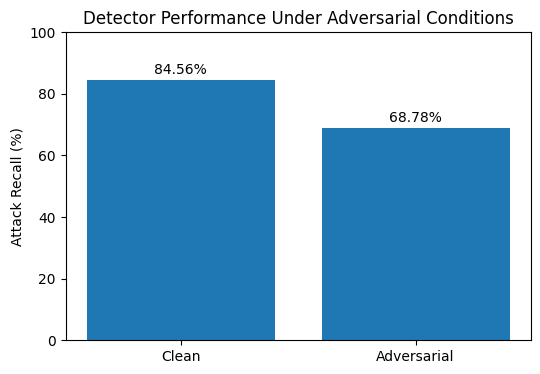


===== CHANNEL-WISE PROBLEM =====


,channel,clean_attack_recall,adversarial_attack_recall,clean_fnr,adversarial_fnr
0,Low,0.890000,0.776667,0.110000,0.223333
1,Medium,0.836667,0.676667,0.163333,0.323333
2,High,0.810000,0.610000,0.190000,0.390000


In [ ]:
# Visualize the baseline problem before presenting Novelty 1

import os
import pandas as pd
import matplotlib.pyplot as plt

overall_problem = pd.read_csv(
    os.path.join(
        PROJECT_PATH,
        "results",
        "clean_vs_adversarial_overall_v2.csv"
    )
)

channel_problem = pd.read_csv(
    os.path.join(
        PROJECT_PATH,
        "results",
        "clean_vs_adversarial_by_channel_v2.csv"
    )
)

clean_row = overall_problem[
    overall_problem["condition"] == "Clean"
].iloc[0]

adv_row = overall_problem[
    overall_problem["condition"] == "Adversarial"
].iloc[0]

print("===== STEP 1 — PROBLEM: ADVERSARIAL VULNERABILITY =====")

print("\nClean condition")
print(
    "Attack Recall :",
    round(clean_row["attack_recall"] * 100, 2),
    "%"
)
print(
    "FNR           :",
    round(clean_row["fnr"] * 100, 2),
    "%"
)

print("\nAdversarial condition")
print(
    "Attack Recall :",
    round(adv_row["attack_recall"] * 100, 2),
    "%"
)
print(
    "FNR           :",
    round(adv_row["fnr"] * 100, 2),
    "%"
)

print(
    "\nRecall drop   :",
    round(
        (
            clean_row["attack_recall"]
            - adv_row["attack_recall"]
        ) * 100,
        2
    ),
    "percentage points"
)

plt.figure(figsize=(6, 4))

plt.bar(
    ["Clean", "Adversarial"],
    [
        clean_row["attack_recall"] * 100,
        adv_row["attack_recall"] * 100
    ]
)

plt.ylabel("Attack Recall (%)")
plt.ylim(0, 100)
plt.title("Detector Performance Under Adversarial Conditions")

for i, value in enumerate([
    clean_row["attack_recall"] * 100,
    adv_row["attack_recall"] * 100
]):
    plt.text(
        i,
        value + 2,
        f"{value:.2f}%",
        ha="center"
    )

plt.show()

print("\n===== CHANNEL-WISE PROBLEM =====")

display(
    channel_problem[
        [
            "channel",
            "clean_attack_recall",
            "adversarial_attack_recall",
            "clean_fnr",
            "adversarial_fnr"
        ]
    ]
)

===== STEP 2 — NOVELTY 1: CROSS-CHANNEL TRANSFER =====

INPUT
Source pattern       : Low
Target channel       : High
Eve factor           : 0.8
Noise shift          : -0.002
Loss shift           : -0.02

SIMULATION
Target attacks       : 300
Clean-correct attacks: 243

OUTPUT
Still detected       : 208
Successful evasions  : 35
ASR                   : 14.4 %

RESULT: CROSS-CHANNEL TRANSFER DETECTED


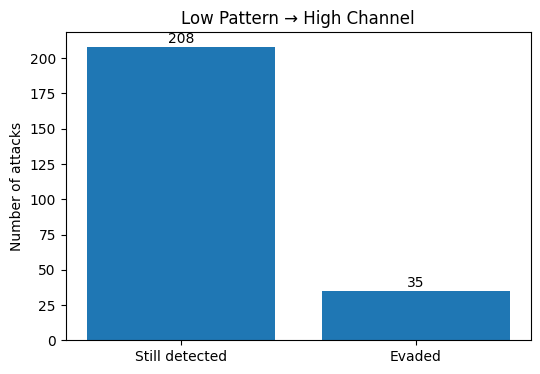

In [ ]:
# STEP 2 — Demonstrate Low-to-High cross-channel adversarial transfer

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SOURCE_CHANNEL = "Low"
TARGET_CHANNEL = "High"

pattern = selected_patterns[SOURCE_CHANNEL]

eve_factor = float(pattern["eve_factor"])
noise_shift = float(pattern["noise_shift"])
loss_shift = float(pattern["loss_shift"])

target_attacks = test_df[
    (test_df["label"] == 1) &
    (test_df["channel_condition"] == TARGET_CHANNEL)
].copy()

clean_prob = rf_model.predict_proba(
    target_attacks[ML_FEATURES]
)[:, 1]

target_attacks["clean_probability"] = clean_prob

eligible = target_attacks[
    target_attacks["clean_probability"] >= FINAL_THRESHOLD
].copy()

noise_min, noise_max = CHANNEL_RANGES[TARGET_CHANNEL]["noise"]
loss_min, loss_max = CHANNEL_RANGES[TARGET_CHANNEL]["loss"]

demo_results = []

for _, row in eligible.iterrows():

    adversarial_eve = max(
        0.01,
        float(row["target_eve_rate"]) * eve_factor
    )

    adversarial_noise = float(
        np.clip(
            float(row["target_noise_rate"]) + noise_shift,
            noise_min,
            noise_max
        )
    )

    adversarial_loss = float(
        np.clip(
            float(row["target_loss_rate"]) + loss_shift,
            loss_min,
            loss_max
        )
    )

    sim = simulate_bb84_session(
        n_bits=10000,
        noise_rate=adversarial_noise,
        loss_rate=adversarial_loss,
        eve_rate=adversarial_eve,
        seed=int(row["session_seed"]),
        n_blocks=20
    )

    X_demo = pd.DataFrame(
        [{
            feature: sim[feature]
            for feature in ML_FEATURES
        }]
    )

    adversarial_probability = rf_model.predict_proba(
        X_demo
    )[0, 1]

    adversarial_prediction = int(
        adversarial_probability >= FINAL_THRESHOLD
    )

    demo_results.append({
        "session_id": row["session_id"],
        "clean_probability": row["clean_probability"],
        "adversarial_probability": adversarial_probability,
        "successful_evasion": adversarial_prediction == 0
    })

demo_results = pd.DataFrame(demo_results)

successful = int(
    demo_results["successful_evasion"].sum()
)

still_detected = (
    len(demo_results) - successful
)

asr = (
    successful / len(demo_results) * 100
)

print("===== STEP 2 — NOVELTY 1: CROSS-CHANNEL TRANSFER =====")

print("\nINPUT")
print("Source pattern       :", SOURCE_CHANNEL)
print("Target channel       :", TARGET_CHANNEL)
print("Eve factor           :", eve_factor)
print("Noise shift          :", noise_shift)
print("Loss shift           :", loss_shift)

print("\nSIMULATION")
print("Target attacks       :", len(target_attacks))
print("Clean-correct attacks:", len(eligible))

print("\nOUTPUT")
print("Still detected       :", still_detected)
print("Successful evasions  :", successful)
print("ASR                   :", round(asr, 2), "%")

print("\nRESULT: CROSS-CHANNEL TRANSFER DETECTED")

plt.figure(figsize=(6, 4))

plt.bar(
    ["Still detected", "Evaded"],
    [still_detected, successful]
)

plt.ylabel("Number of attacks")
plt.title("Low Pattern → High Channel")

for i, value in enumerate(
    [still_detected, successful]
):
    plt.text(
        i,
        value + 3,
        str(value),
        ha="center"
    )

plt.show()

===== STEP 3 — CHANNEL-DIVERSE DEFENSE =====

ORIGINAL TRAINING DATA
Normal samples          : 2700
Original attack samples : 2700

ADVERSARIAL TRAINING ATTACKS
Low    : 900
Medium : 900
High   : 900

Total adversarial attacks: 2700

DEFENSE TRAINING STRUCTURE
2700 Normal
+ 2700 Original Attack
+ 2700 Adversarial Attack
= 8100 training samples

Balanced effective training:
Normal effective weight : 2700
Attack effective weight : 2700

OUTPUT
Robust Random Forest
Frozen threshold = 0.59


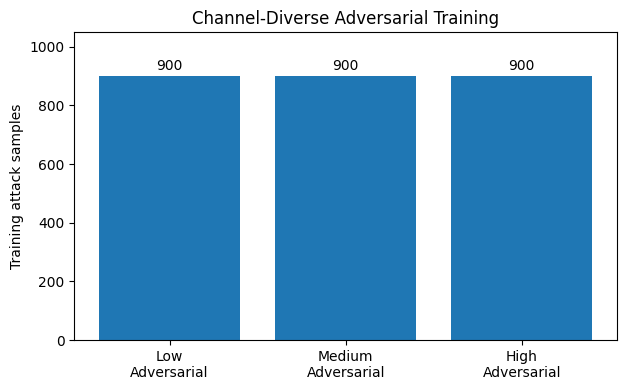

In [ ]:
# STEP 3 — Visualize the channel-diverse adversarially aware defense

import os
import pandas as pd
import matplotlib.pyplot as plt

adversarial_training_df = pd.read_csv(
    os.path.join(
        PROJECT_PATH,
        "data",
        "adversarial_training_attacks_v2.csv"
    )
)

original_attacks = train_df[
    train_df["label"] == 1
]

normal_training = train_df[
    train_df["label"] == 0
]

adv_counts = (
    adversarial_training_df[
        "channel_condition"
    ]
    .value_counts()
    .reindex(
        ["Low", "Medium", "High"]
    )
)

print("===== STEP 3 — CHANNEL-DIVERSE DEFENSE =====")

print("\nORIGINAL TRAINING DATA")
print("Normal samples          :", len(normal_training))
print("Original attack samples :", len(original_attacks))

print("\nADVERSARIAL TRAINING ATTACKS")
print("Low    :", adv_counts["Low"])
print("Medium :", adv_counts["Medium"])
print("High   :", adv_counts["High"])

print(
    "\nTotal adversarial attacks:",
    len(adversarial_training_df)
)

print("\nDEFENSE TRAINING STRUCTURE")
print("2700 Normal")
print("+ 2700 Original Attack")
print("+ 2700 Adversarial Attack")
print("= 8100 training samples")

print("\nBalanced effective training:")
print("Normal effective weight : 2700")
print("Attack effective weight : 2700")

print("\nOUTPUT")
print("Robust Random Forest")
print("Frozen threshold =", ROBUST_THRESHOLD)

plt.figure(figsize=(7, 4))

plt.bar(
    [
        "Low\nAdversarial",
        "Medium\nAdversarial",
        "High\nAdversarial"
    ],
    [
        adv_counts["Low"],
        adv_counts["Medium"],
        adv_counts["High"]
    ]
)

plt.ylabel("Training attack samples")
plt.title(
    "Channel-Diverse Adversarial Training"
)

for i, value in enumerate(
    [
        adv_counts["Low"],
        adv_counts["Medium"],
        adv_counts["High"]
    ]
):
    plt.text(
        i,
        value + 20,
        str(value),
        ha="center"
    )

plt.ylim(
    0,
    max(adv_counts) + 150
)

plt.show()

===== STEP 4 — BEFORE VS AFTER DEFENSE =====

GENERAL ADVERSARIAL PERFORMANCE
Attack Recall : 68.78 % → 74.11 %
FNR           : 31.22 % → 25.89 %

MATCHED AND CROSS-CHANNEL ROBUSTNESS


,test_type,baseline_mean_asr,robust_mean_asr,asr_change_pp
0,Cross-channel,10.489182,11.492034,1.002852
1,Matched,11.630923,9.782345,-1.848578


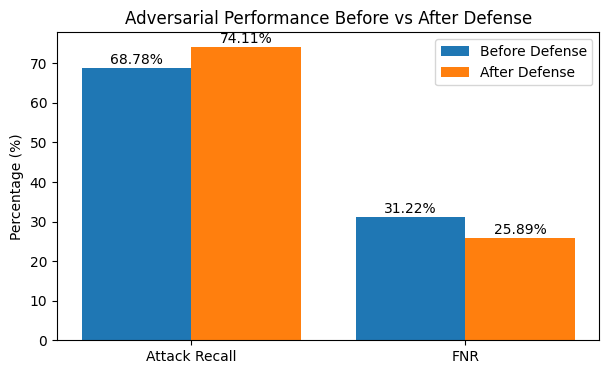

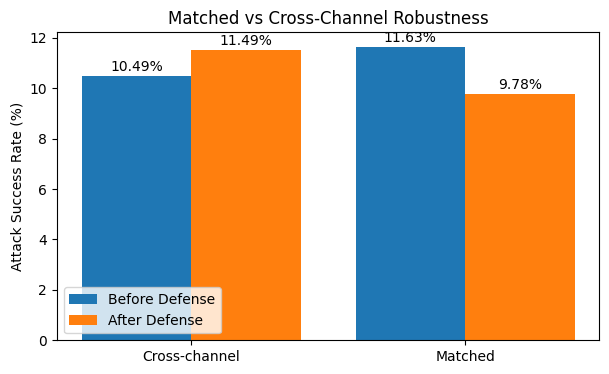

In [ ]:
# STEP 4 — Visualize before-vs-after defense performance

import os
import pandas as pd
import matplotlib.pyplot as plt

defense_summary = pd.read_csv(
    os.path.join(
        PROJECT_PATH,
        "results",
        "novelty1_final_defense_summary_v2.csv"
    )
)

cross_summary = pd.read_csv(
    os.path.join(
        PROJECT_PATH,
        "results",
        "novelty1_final_cross_channel_summary_v2.csv"
    )
)

adv = defense_summary[
    defense_summary["condition"] == "Adversarial"
].iloc[0]

print("===== STEP 4 — BEFORE VS AFTER DEFENSE =====")

print("\nGENERAL ADVERSARIAL PERFORMANCE")
print(
    "Attack Recall :",
    round(adv["baseline_attack_recall"], 2),
    "% →",
    round(adv["robust_attack_recall"], 2),
    "%"
)
print(
    "FNR           :",
    round(adv["baseline_fnr"], 2),
    "% →",
    round(adv["robust_fnr"], 2),
    "%"
)

print("\nMATCHED AND CROSS-CHANNEL ROBUSTNESS")

display(
    cross_summary[
        [
            "test_type",
            "baseline_mean_asr",
            "robust_mean_asr",
            "asr_change_pp"
        ]
    ]
)

plt.figure(figsize=(7, 4))

x = ["Attack Recall", "FNR"]

baseline_values = [
    adv["baseline_attack_recall"],
    adv["baseline_fnr"]
]

robust_values = [
    adv["robust_attack_recall"],
    adv["robust_fnr"]
]

positions = range(len(x))

plt.bar(
    [p - 0.2 for p in positions],
    baseline_values,
    width=0.4,
    label="Before Defense"
)

plt.bar(
    [p + 0.2 for p in positions],
    robust_values,
    width=0.4,
    label="After Defense"
)

plt.xticks(positions, x)
plt.ylabel("Percentage (%)")
plt.title("Adversarial Performance Before vs After Defense")
plt.legend()

for i, value in enumerate(baseline_values):
    plt.text(
        i - 0.2,
        value + 1,
        f"{value:.2f}%",
        ha="center"
    )

for i, value in enumerate(robust_values):
    plt.text(
        i + 0.2,
        value + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.show()

plt.figure(figsize=(7, 4))

labels = cross_summary["test_type"].tolist()

baseline_asr = cross_summary[
    "baseline_mean_asr"
].tolist()

robust_asr = cross_summary[
    "robust_mean_asr"
].tolist()

positions = range(len(labels))

plt.bar(
    [p - 0.2 for p in positions],
    baseline_asr,
    width=0.4,
    label="Before Defense"
)

plt.bar(
    [p + 0.2 for p in positions],
    robust_asr,
    width=0.4,
    label="After Defense"
)

plt.xticks(positions, labels)
plt.ylabel("Attack Success Rate (%)")
plt.title("Matched vs Cross-Channel Robustness")
plt.legend()

for i, value in enumerate(baseline_asr):
    plt.text(
        i - 0.2,
        value + 0.2,
        f"{value:.2f}%",
        ha="center"
    )

for i, value in enumerate(robust_asr):
    plt.text(
        i + 0.2,
        value + 0.2,
        f"{value:.2f}%",
        ha="center"
    )

plt.show()

===== STEP 5 — NOVELTY 1 FINAL CONCLUSION =====

1. PROBLEM CONFIRMED
Adversarial manipulation reduced detector performance.

2. CROSS-CHANNEL TRANSFER CONFIRMED
Attack strategies selected in one known channel
were able to evade the detector in other known channels.

3. DEFENSE EFFECT
Adversarial Recall : 68.78 % → 74.11 %
Adversarial FNR    : 31.22 % → 25.89 %
Matched ASR        : 11.63 % → 9.78 %
Cross-channel ASR  : 10.49 % → 11.49 %

FINAL FINDING
Cross-channel adversarial transfer exists.
Channel-diverse adversarial training improves general
and matched-channel robustness, but does not
consistently solve cross-channel transfer vulnerability.


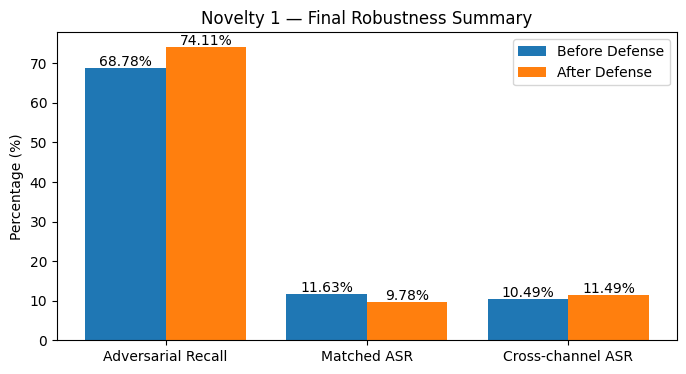

In [ ]:
# STEP 5 — Summarize the final Novelty 1 findings in one clear output

import os
import pandas as pd
import matplotlib.pyplot as plt

defense_summary = pd.read_csv(
    os.path.join(
        PROJECT_PATH,
        "results",
        "novelty1_final_defense_summary_v2.csv"
    )
)

cross_summary = pd.read_csv(
    os.path.join(
        PROJECT_PATH,
        "results",
        "novelty1_final_cross_channel_summary_v2.csv"
    )
)

adv = defense_summary[
    defense_summary["condition"] == "Adversarial"
].iloc[0]

matched = cross_summary[
    cross_summary["test_type"] == "Matched"
].iloc[0]

cross = cross_summary[
    cross_summary["test_type"] == "Cross-channel"
].iloc[0]

print("===== STEP 5 — NOVELTY 1 FINAL CONCLUSION =====")

print("\n1. PROBLEM CONFIRMED")
print("Adversarial manipulation reduced detector performance.")

print("\n2. CROSS-CHANNEL TRANSFER CONFIRMED")
print("Attack strategies selected in one known channel")
print("were able to evade the detector in other known channels.")

print("\n3. DEFENSE EFFECT")
print(
    "Adversarial Recall :",
    round(adv["baseline_attack_recall"], 2),
    "% →",
    round(adv["robust_attack_recall"], 2),
    "%"
)

print(
    "Adversarial FNR    :",
    round(adv["baseline_fnr"], 2),
    "% →",
    round(adv["robust_fnr"], 2),
    "%"
)

print(
    "Matched ASR        :",
    round(matched["baseline_mean_asr"], 2),
    "% →",
    round(matched["robust_mean_asr"], 2),
    "%"
)

print(
    "Cross-channel ASR  :",
    round(cross["baseline_mean_asr"], 2),
    "% →",
    round(cross["robust_mean_asr"], 2),
    "%"
)

print("\nFINAL FINDING")
print(
    "Cross-channel adversarial transfer exists."
)
print(
    "Channel-diverse adversarial training improves general"
)
print(
    "and matched-channel robustness, but does not"
)
print(
    "consistently solve cross-channel transfer vulnerability."
)

labels = [
    "Adversarial Recall",
    "Matched ASR",
    "Cross-channel ASR"
]

before = [
    adv["baseline_attack_recall"],
    matched["baseline_mean_asr"],
    cross["baseline_mean_asr"]
]

after = [
    adv["robust_attack_recall"],
    matched["robust_mean_asr"],
    cross["robust_mean_asr"]
]

positions = range(len(labels))

plt.figure(figsize=(8, 4))

plt.bar(
    [p - 0.2 for p in positions],
    before,
    width=0.4,
    label="Before Defense"
)

plt.bar(
    [p + 0.2 for p in positions],
    after,
    width=0.4,
    label="After Defense"
)

plt.xticks(positions, labels)
plt.ylabel("Percentage (%)")
plt.title("Novelty 1 — Final Robustness Summary")
plt.legend()

for i, value in enumerate(before):
    plt.text(
        i - 0.2,
        value + 0.5,
        f"{value:.2f}%",
        ha="center"
    )

for i, value in enumerate(after):
    plt.text(
        i + 0.2,
        value + 0.5,
        f"{value:.2f}%",
        ha="center"
    )

plt.show()

In [ ]:
# Recover all saved Novelty 1 state from Google Drive without rerunning heavy experiments
import os
import json
import joblib
import pandas as pd

# PROJECT_PATH is set in the first cell
baseline_model = joblib.load(
    os.path.join(PROJECT_PATH, "models", "random_forest_v2_primary.joblib")
)

robust_model = joblib.load(
    os.path.join(PROJECT_PATH, "models", "random_forest_v2_robust_unthresholded.joblib")
)

with open(
    os.path.join(PROJECT_PATH, "configs", "random_forest_v2_threshold.json"),
    "r"
) as f:
    baseline_threshold_config = json.load(f)

with open(
    os.path.join(PROJECT_PATH, "configs", "random_forest_v2_robust_threshold.json"),
    "r"
) as f:
    robust_threshold_config = json.load(f)

baseline_threshold = 0.38
robust_threshold = 0.59

train_df = pd.read_csv(
    os.path.join(PROJECT_PATH, "data", "known_v2_train.csv")
)

validation_df = pd.read_csv(
    os.path.join(PROJECT_PATH, "data", "known_v2_validation.csv")
)

test_df = pd.read_csv(
    os.path.join(PROJECT_PATH, "data", "known_v2_test.csv")
)

full_adversarial_results = pd.read_csv(
    os.path.join(PROJECT_PATH, "results", "full_physical_adversarial_results_v2.csv")
)

cross_channel_results = pd.read_csv(
    os.path.join(PROJECT_PATH, "results", "cross_channel_test_results_v2.csv")
)

with open(
    os.path.join(PROJECT_PATH, "configs", "cross_channel_selected_patterns_v2.json"),
    "r"
) as f:
    selected_patterns = json.load(f)

simulate_bb84_session = joblib.load(
    os.path.join(PROJECT_PATH, "models", "bb84_simulator_v2.pkl")
)

print("===== PROJECT RECOVERY COMPLETE =====")
print(f"Baseline RF loaded       | threshold = {baseline_threshold}")
print(f"Robust RF loaded         | threshold = {robust_threshold}")
print(f"Train rows               = {len(train_df)}")
print(f"Validation rows          = {len(validation_df)}")
print(f"Test rows                = {len(test_df)}")
print(f"Full adversarial results = {len(full_adversarial_results)}")
print(f"Cross-channel rows       = {len(cross_channel_results)}")
print("BB84 simulator           = Loaded")
print("\n✅ Ready for Paper V3")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
===== PROJECT RECOVERY COMPLETE =====
Baseline RF loaded       | threshold = 0.38
Robust RF loaded         | threshold = 0.59
Train rows               = 5400
Validation rows          = 1800
Test rows                = 1800
Full adversarial results = 761
Cross-channel rows       = 9
BB84 simulator           = Loaded

✅ Ready for Paper V3


In [ ]:
# Freeze the Paper V3 fresh confirmatory test protocol before generating new data

import os
import json

# PROJECT_PATH is set in the first cell
protocol = {
    "version": "paper_v3_fresh_confirmatory_test_v1",
    "master_seed": 20261021,
    "bits_per_session": 10000,

    "channels": {
        "Low": {
            "noise_range": [0.005, 0.015],
            "loss_range": [0.05, 0.15]
        },
        "Medium": {
            "noise_range": [0.02, 0.04],
            "loss_range": [0.20, 0.35]
        },
        "High": {
            "noise_range": [0.05, 0.07],
            "loss_range": [0.40, 0.55]
        }
    },

    "sessions_per_channel": 600,
    "normal_per_channel": 300,
    "attack_per_channel": 300,

    "attack_distribution": {
        "weak_fraction": 0.70,
        "weak_eve_range": [0.01, 0.10],
        "strong_fraction": 0.30,
        "strong_eve_range": [0.10, 0.30]
    },

    "baseline_model": "random_forest_v2_primary.joblib",
    "baseline_threshold": 0.38,

    "robust_model": "random_forest_v2_robust_unthresholded.joblib",
    "robust_threshold": 0.59,

    "rules": {
        "no_training_on_fresh_test": True,
        "no_threshold_tuning_on_fresh_test": True,
        "no_recipe_selection_on_fresh_test": True,
        "no_model_selection_on_fresh_test": True,
        "no_methodology_change_after_viewing_results": True
    }
}

path = os.path.join(
    PROJECT_PATH,
    "configs",
    "paper_v3_fresh_confirmatory_test_protocol.json"
)

with open(path, "w", encoding="utf-8") as f:
    json.dump(protocol, f, indent=4)

print("===== PROTOCOL FROZEN =====")
print("Seed:", protocol["master_seed"])
print("Low sessions:", 600)
print("Medium sessions:", 600)
print("High sessions:", 600)
print("Total:", 1800)
print("Baseline threshold:", 0.38)
print("Robust threshold:", 0.59)
print("\n✅ Saved:")
print(path)

===== PROTOCOL FROZEN =====
Seed: 20261021
Low sessions: 600
Medium sessions: 600
High sessions: 600
Total: 1800
Baseline threshold: 0.38
Robust threshold: 0.59

✅ Saved:
/content/drive/MyDrive/Adversarial_QKD_Attack/configs/paper_v3_fresh_confirmatory_test_protocol.json


In [ ]:
# Generate the frozen fresh confirmatory BB84 test set

import os
import json
import hashlib
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

protocol_path = os.path.join(
    PROJECT_PATH,
    "configs",
    "paper_v3_fresh_confirmatory_test_protocol.json"
)

with open(protocol_path, "r", encoding="utf-8") as f:
    protocol = json.load(f)

master_seed = protocol["master_seed"]
n_bits = protocol["bits_per_session"]

feature_cols = [
    "qber",
    "detection_rate",
    "sifted_ratio",
    "qber_z",
    "qber_x",
    "qber_block_std",
    "detection_block_std",
    "sifted_entropy"
]

diagnostic_cols = [
    "detected_bits",
    "sifted_bits",
    "errors"
]

rng = np.random.default_rng(master_seed)

rows = []

for channel_name in ["Low", "Medium", "High"]:

    channel_cfg = protocol["channels"][channel_name]

    noise_low, noise_high = channel_cfg["noise_range"]
    loss_low, loss_high = channel_cfg["loss_range"]

    labels = np.array(
        [0] * protocol["normal_per_channel"] +
        [1] * protocol["attack_per_channel"]
    )

    rng.shuffle(labels)

    attack_positions = np.where(labels == 1)[0]

    weak_count = int(
        protocol["attack_per_channel"] *
        protocol["attack_distribution"]["weak_fraction"]
    )

    attack_strength = np.array(
        ["weak"] * weak_count +
        ["strong"] * (len(attack_positions) - weak_count)
    )

    rng.shuffle(attack_strength)

    attack_strength_map = {
        pos: strength
        for pos, strength in zip(
            attack_positions,
            attack_strength
        )
    }

    for i in tqdm(
        range(protocol["sessions_per_channel"]),
        desc=f"Generating {channel_name}"
    ):

        label = int(labels[i])

        noise_rate = float(
            rng.uniform(noise_low, noise_high)
        )

        loss_rate = float(
            rng.uniform(loss_low, loss_high)
        )

        if label == 0:
            eve_rate = 0.0
            attack_type = "Normal"

        else:
            strength = attack_strength_map[i]

            if strength == "weak":
                eve_low, eve_high = (
                    protocol["attack_distribution"]["weak_eve_range"]
                )
            else:
                eve_low, eve_high = (
                    protocol["attack_distribution"]["strong_eve_range"]
                )

            eve_rate = float(
                rng.uniform(eve_low, eve_high)
            )

            attack_type = "Intercept-Resend"

        session_seed = int(
            rng.integers(
                1,
                np.iinfo(np.int32).max
            )
        )

        sim = simulate_bb84_session(
            n_bits=n_bits,
            noise_rate=noise_rate,
            loss_rate=loss_rate,
            eve_rate=eve_rate,
            seed=session_seed,
            n_blocks=20
        )

        row = {
            "session_id": f"v3_fresh_{channel_name.lower()}_{i:05d}",
            "channel_condition": channel_name,
            "attack_type": attack_type,
            "target_noise_rate": noise_rate,
            "target_loss_rate": loss_rate,
            "target_eve_rate": eve_rate,
            "session_seed": session_seed,
            "label": label
        }

        for col in feature_cols + diagnostic_cols:
            row[col] = sim[col]

        rows.append(row)

fresh_test_df = pd.DataFrame(rows)

column_order = [
    "session_id",
    "channel_condition",
    "attack_type",
    "target_noise_rate",
    "target_loss_rate",
    "target_eve_rate",
    "session_seed",
    "label"
] + feature_cols + diagnostic_cols

fresh_test_df = fresh_test_df[column_order]

save_path = os.path.join(
    PROJECT_PATH,
    "data",
    "paper_v3_fresh_confirmatory_test.csv"
)

fresh_test_df.to_csv(
    save_path,
    index=False
)

with open(save_path, "rb") as f:
    sha256 = hashlib.sha256(f.read()).hexdigest()

hash_path = os.path.join(
    PROJECT_PATH,
    "configs",
    "paper_v3_fresh_confirmatory_test_sha256.txt"
)

with open(hash_path, "w") as f:
    f.write(sha256)

print("\n===== PAPER V3 FRESH TEST GENERATED =====")
print("Rows:", len(fresh_test_df))
print("Columns:", len(fresh_test_df.columns))

print("\nChannel counts:")
print(
    fresh_test_df["channel_condition"]
    .value_counts()
    .sort_index()
)

print("\nClass counts:")
print(
    fresh_test_df["label"]
    .value_counts()
    .sort_index()
)

print("\nChannel × Class:")
print(
    pd.crosstab(
        fresh_test_df["channel_condition"],
        fresh_test_df["label"]
    )
)

print("\nMissing values:", fresh_test_df.isna().sum().sum())
print("Duplicate rows:", fresh_test_df.duplicated().sum())

numeric_df = fresh_test_df.select_dtypes(include=[np.number])
print(
    "Infinite values:",
    np.isinf(numeric_df.to_numpy()).sum()
)

print("\n✅ Fresh test saved:")
print(save_path)

print("\n✅ SHA256 frozen:")
print(sha256)

Generating Low:   0%|          | 0/600 [00:00<?, ?it/s]

Generating Medium:   0%|          | 0/600 [00:00<?, ?it/s]

Generating High:   0%|          | 0/600 [00:00<?, ?it/s]


===== PAPER V3 FRESH TEST GENERATED =====
Rows: 1800
Columns: 19

Channel counts:
channel_condition
High      600
Low       600
Medium    600
Name: count, dtype: int64

Class counts:
label
0    900
1    900
Name: count, dtype: int64

Channel × Class:
label                0    1
channel_condition          
High               300  300
Low                300  300
Medium             300  300

Missing values: 0
Duplicate rows: 0
Infinite values: 0

✅ Fresh test saved:
/content/drive/MyDrive/Adversarial_QKD_Attack/data/paper_v3_fresh_confirmatory_test.csv

✅ SHA256 frozen:
b1755a4abbc230247316a2653cd58fac05b4823cb152dc17fa7974c15f2324b7


In [ ]:
# Validate the physical ranges, labels, attack strengths and integrity of the fresh confirmatory dataset

import os
import json
import numpy as np
import pandas as pd

fresh_path = os.path.join(
    PROJECT_PATH,
    "data",
    "paper_v3_fresh_confirmatory_test.csv"
)

fresh_test_df = pd.read_csv(fresh_path)

checks = []

checks.append(("Rows = 1800", len(fresh_test_df) == 1800))
checks.append(("Columns = 19", len(fresh_test_df.columns) == 19))
checks.append(("Missing values = 0", fresh_test_df.isna().sum().sum() == 0))
checks.append(("Duplicate rows = 0", fresh_test_df.duplicated().sum() == 0))
checks.append(("Unique session IDs = 1800", fresh_test_df["session_id"].nunique() == 1800))

numeric_df = fresh_test_df.select_dtypes(include=[np.number])
checks.append(("Infinite values = 0", np.isinf(numeric_df.to_numpy()).sum() == 0))

expected_ranges = {
    "Low": {
        "noise": (0.005, 0.015),
        "loss": (0.05, 0.15)
    },
    "Medium": {
        "noise": (0.02, 0.04),
        "loss": (0.20, 0.35)
    },
    "High": {
        "noise": (0.05, 0.07),
        "loss": (0.40, 0.55)
    }
}

for channel, ranges in expected_ranges.items():

    ch = fresh_test_df[
        fresh_test_df["channel_condition"] == channel
    ]

    noise_ok = ch["target_noise_rate"].between(
        ranges["noise"][0],
        ranges["noise"][1]
    ).all()

    loss_ok = ch["target_loss_rate"].between(
        ranges["loss"][0],
        ranges["loss"][1]
    ).all()

    checks.append((f"{channel} noise range valid", noise_ok))
    checks.append((f"{channel} loss range valid", loss_ok))

normal = fresh_test_df[
    fresh_test_df["label"] == 0
]

attack = fresh_test_df[
    fresh_test_df["label"] == 1
]

checks.append(("Normal Eve rate = 0", (normal["target_eve_rate"] == 0).all()))
checks.append(("Attack Eve rate > 0", (attack["target_eve_rate"] > 0).all()))
checks.append(("Attack Eve rate <= 0.30", (attack["target_eve_rate"] <= 0.30).all()))
checks.append(("Normal attack type correct", (normal["attack_type"] == "Normal").all()))
checks.append(("Attack type correct", (attack["attack_type"] == "Intercept-Resend").all()))

print("===== PAPER V3 FRESH TEST VALIDATION =====")

all_pass = True

for name, passed in checks:
    print(f"{'PASS' if passed else 'FAIL'} | {name}")
    all_pass = all_pass and passed

print("\n===== ATTACK STRENGTH DISTRIBUTION =====")

attack_strength_summary = []

for channel in ["Low", "Medium", "High"]:

    ch_attack = attack[
        attack["channel_condition"] == channel
    ]

    weak = (
        (ch_attack["target_eve_rate"] >= 0.01) &
        (ch_attack["target_eve_rate"] < 0.10)
    ).sum()

    strong = (
        (ch_attack["target_eve_rate"] >= 0.10) &
        (ch_attack["target_eve_rate"] <= 0.30)
    ).sum()

    attack_strength_summary.append({
        "channel": channel,
        "weak_1_10_percent": weak,
        "strong_10_30_percent": strong,
        "total_attacks": len(ch_attack)
    })

attack_strength_df = pd.DataFrame(attack_strength_summary)
display(attack_strength_df)

print("\n===== PHYSICAL PARAMETER SUMMARY =====")

summary = fresh_test_df.groupby(
    ["channel_condition", "label"]
)[
    [
        "target_noise_rate",
        "target_loss_rate",
        "target_eve_rate",
        "qber",
        "detection_rate",
        "sifted_ratio"
    ]
].mean().round(4)

display(summary)

print("\nFINAL STATUS:")
if all_pass:
    print("✅ FRESH CONFIRMATORY DATASET VALIDATION PASSED")
    print("Dataset is ready for frozen-model evaluation.")
else:
    print("❌ VALIDATION FAILED — do not evaluate models yet.")

===== PAPER V3 FRESH TEST VALIDATION =====
PASS | Rows = 1800
PASS | Columns = 19
PASS | Missing values = 0
PASS | Duplicate rows = 0
PASS | Unique session IDs = 1800
PASS | Infinite values = 0
PASS | Low noise range valid
PASS | Low loss range valid
PASS | Medium noise range valid
PASS | Medium loss range valid
PASS | High noise range valid
PASS | High loss range valid
PASS | Normal Eve rate = 0
PASS | Attack Eve rate > 0
PASS | Attack Eve rate <= 0.30
PASS | Normal attack type correct
PASS | Attack type correct

===== ATTACK STRENGTH DISTRIBUTION =====


,channel,weak_1_10_percent,strong_10_30_percent,total_attacks
0,Low,210,90,300
1,Medium,210,90,300
2,High,210,90,300



===== PHYSICAL PARAMETER SUMMARY =====


target_noise_rate  target_loss_rate  target_eve_rate  \
channel_condition label                                                         
High              0                 0.0600            0.4729           0.0000   
                  1                 0.0604            0.4770           0.1001   
Low               0                 0.0101            0.0990           0.0000   
                  1                 0.0100            0.1003           0.0979   
Medium            0                 0.0300            0.2731           0.0000   
                  1                 0.0302            0.2726           0.0957   

                           qber  detection_rate  sifted_ratio  
channel_condition label                                        
High              0      0.0600          0.5274        0.2637  
                  1      0.0827          0.5233        0.2615  
Low               0      0.0101          0.9011        0.4508  
                  1      0.0339          0.8998        0.4502  
Medium            0      0.0301          0.7271        0.3634  
                  1      0.0528          0.7271        0.3638


FINAL STATUS:
✅ FRESH CONFIRMATORY DATASET VALIDATION PASSED
Dataset is ready for frozen-model evaluation.


In [ ]:
# Evaluate the frozen Baseline and Robust Random Forest models on the untouched fresh confirmatory test set

import os
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

fresh_test_df = pd.read_csv(
    os.path.join(
        PROJECT_PATH,
        "data",
        "paper_v3_fresh_confirmatory_test.csv"
    )
)

feature_cols = [
    "qber",
    "detection_rate",
    "sifted_ratio",
    "qber_z",
    "qber_x",
    "qber_block_std",
    "detection_block_std",
    "sifted_entropy"
]

X_fresh = fresh_test_df[feature_cols]
y_fresh = fresh_test_df["label"].astype(int)

baseline_class_index = list(baseline_model.classes_).index(1)
robust_class_index = list(robust_model.classes_).index(1)

baseline_prob = baseline_model.predict_proba(X_fresh)[:, baseline_class_index]
robust_prob = robust_model.predict_proba(X_fresh)[:, robust_class_index]

baseline_pred = (baseline_prob >= baseline_threshold).astype(int)
robust_pred = (robust_prob >= robust_threshold).astype(int)

def calculate_metrics(y_true, y_pred, y_prob):
    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "attack_recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_prob),
        "fnr": fn / (fn + tp),
        "fpr": fp / (fp + tn),
        "tn": tn,
        "fp": fp,
        "fn": fn,
        "tp": tp
    }

overall_rows = []

for model_name, pred, prob, threshold in [
    ("Baseline RF", baseline_pred, baseline_prob, baseline_threshold),
    ("Robust RF", robust_pred, robust_prob, robust_threshold)
]:
    metrics = calculate_metrics(
        y_fresh,
        pred,
        prob
    )

    overall_rows.append({
        "model": model_name,
        "threshold": threshold,
        **metrics
    })

overall_df = pd.DataFrame(overall_rows)

channel_rows = []

for channel in ["Low", "Medium", "High"]:

    mask = fresh_test_df["channel_condition"] == channel

    y_ch = y_fresh[mask]

    for model_name, pred, prob, threshold in [
        ("Baseline RF", baseline_pred[mask], baseline_prob[mask], baseline_threshold),
        ("Robust RF", robust_pred[mask], robust_prob[mask], robust_threshold)
    ]:
        metrics = calculate_metrics(
            y_ch,
            pred,
            prob
        )

        channel_rows.append({
            "channel": channel,
            "model": model_name,
            "threshold": threshold,
            **metrics
        })

channel_df = pd.DataFrame(channel_rows)

prediction_df = fresh_test_df[
    [
        "session_id",
        "channel_condition",
        "label",
        "target_eve_rate"
    ]
].copy()

prediction_df["baseline_probability"] = baseline_prob
prediction_df["baseline_prediction"] = baseline_pred
prediction_df["robust_probability"] = robust_prob
prediction_df["robust_prediction"] = robust_pred

overall_path = os.path.join(
    PROJECT_PATH,
    "results",
    "paper_v3_fresh_confirmatory_overall.csv"
)

channel_path = os.path.join(
    PROJECT_PATH,
    "results",
    "paper_v3_fresh_confirmatory_by_channel.csv"
)

prediction_path = os.path.join(
    PROJECT_PATH,
    "results",
    "paper_v3_fresh_confirmatory_predictions.csv"
)

overall_df.to_csv(overall_path, index=False)
channel_df.to_csv(channel_path, index=False)
prediction_df.to_csv(prediction_path, index=False)

print("===== PAPER V3 — FRESH CONFIRMATORY EVALUATION =====")

print("\nOVERALL PERFORMANCE")
display(overall_df.round(6))

print("\nCHANNEL-WISE PERFORMANCE")
display(channel_df.round(6))

baseline_recall = overall_df.loc[
    overall_df["model"] == "Baseline RF",
    "attack_recall"
].iloc[0]

robust_recall = overall_df.loc[
    overall_df["model"] == "Robust RF",
    "attack_recall"
].iloc[0]

baseline_fnr = overall_df.loc[
    overall_df["model"] == "Baseline RF",
    "fnr"
].iloc[0]

robust_fnr = overall_df.loc[
    overall_df["model"] == "Robust RF",
    "fnr"
].iloc[0]

print("\n===== CONFIRMATORY COMPARISON =====")
print(
    f"Attack Recall: {baseline_recall*100:.2f}% → "
    f"{robust_recall*100:.2f}%"
)
print(
    f"FNR          : {baseline_fnr*100:.2f}% → "
    f"{robust_fnr*100:.2f}%"
)

print("\n✅ Frozen-model evaluation completed.")
print("✅ No training or threshold tuning was performed.")
print("✅ Results saved to Drive.")

===== PAPER V3 — FRESH CONFIRMATORY EVALUATION =====

OVERALL PERFORMANCE


,model,threshold,accuracy,precision,attack_recall,f1,roc_auc,fnr,fpr,tn,fp,fn,tp
0,Baseline RF,0.38,0.840556,0.830636,0.855556,0.842912,0.923564,0.144444,0.174444,743,157,130,770
1,Robust RF,0.59,0.830000,0.816631,0.851111,0.833515,0.920077,0.148889,0.191111,728,172,134,766



CHANNEL-WISE PERFORMANCE


,channel,model,threshold,accuracy,precision,attack_recall,f1,roc_auc,fnr,fpr,tn,fp,fn,tp
0,Low,Baseline RF,0.38,0.910000,0.927083,0.890000,0.908163,0.969083,0.110000,0.070000,279,21,33,267
1,Low,Robust RF,0.59,0.896667,0.902027,0.890000,0.895973,0.966300,0.110000,0.096667,271,29,33,267
2,Medium,Baseline RF,0.38,0.813333,0.801282,0.833333,0.816993,0.902506,0.166667,0.206667,238,62,50,250
3,Medium,Robust RF,0.59,0.808333,0.801303,0.820000,0.810544,0.896744,0.180000,0.203333,239,61,54,246
4,High,Baseline RF,0.38,0.798333,0.773700,0.843333,0.807018,0.880094,0.156667,0.246667,226,74,47,253
5,High,Robust RF,0.59,0.785000,0.755224,0.843333,0.796850,0.882406,0.156667,0.273333,218,82,47,253



===== CONFIRMATORY COMPARISON =====
Attack Recall: 85.56% → 85.11%
FNR          : 14.44% → 14.89%

✅ Frozen-model evaluation completed.
✅ No training or threshold tuning was performed.
✅ Results saved to Drive.


In [ ]:
# Run the frozen physical adversarial protocol on the fresh confirmatory test set

import os
import time
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

fresh_test_df = pd.read_csv(
    os.path.join(PROJECT_PATH, "data", "paper_v3_fresh_confirmatory_test.csv")
)

feature_cols = [
    "qber",
    "detection_rate",
    "sifted_ratio",
    "qber_z",
    "qber_x",
    "qber_block_std",
    "detection_block_std",
    "sifted_entropy"
]

channel_ranges = {
    "Low": {"noise": (0.005, 0.015), "loss": (0.05, 0.15)},
    "Medium": {"noise": (0.02, 0.04), "loss": (0.20, 0.35)},
    "High": {"noise": (0.05, 0.07), "loss": (0.40, 0.55)}
}

eve_factors = [1.00, 0.95, 0.90, 0.85, 0.80]
noise_shifts = [-0.002, 0.0, 0.002]
loss_shifts = [-0.02, 0.0, 0.02]

X_fresh = fresh_test_df[feature_cols]

baseline_attack_idx = list(baseline_model.classes_).index(1)
robust_attack_idx = list(robust_model.classes_).index(1)

baseline_clean_prob = baseline_model.predict_proba(X_fresh)[:, baseline_attack_idx]
baseline_clean_pred = (baseline_clean_prob >= baseline_threshold).astype(int)

robust_clean_prob = robust_model.predict_proba(X_fresh)[:, robust_attack_idx]
robust_clean_pred = (robust_clean_prob >= robust_threshold).astype(int)

fresh_test_df["baseline_clean_probability"] = baseline_clean_prob
fresh_test_df["baseline_clean_prediction"] = baseline_clean_pred
fresh_test_df["robust_clean_probability"] = robust_clean_prob
fresh_test_df["robust_clean_prediction"] = robust_clean_pred

eligible = fresh_test_df[
    (fresh_test_df["label"] == 1) &
    (fresh_test_df["baseline_clean_prediction"] == 1)
].copy()

progress_path = os.path.join(
    PROJECT_PATH,
    "results",
    "paper_v3_fresh_adversarial_progress.csv"
)

final_path = os.path.join(
    PROJECT_PATH,
    "results",
    "paper_v3_fresh_physical_adversarial_results.csv"
)

if os.path.exists(progress_path):
    progress_df = pd.read_csv(progress_path)
    completed_ids = set(progress_df["session_id"])
    results = progress_df.to_dict("records")
    print(f"Resuming from {len(completed_ids)} completed attacks.")
else:
    completed_ids = set()
    results = []

remaining = eligible[
    ~eligible["session_id"].isin(completed_ids)
]

print("===== PAPER V3 — FRESH ADVERSARIAL CONFIRMATION =====")
print("Fresh attacks:", (fresh_test_df["label"] == 1).sum())
print("Baseline clean-correct attacks:", len(eligible))
print("Already completed:", len(completed_ids))
print("Remaining:", len(remaining))
print("Candidates per attack:", 45)

start_time = time.time()

for count, (_, row) in enumerate(
    tqdm(remaining.iterrows(), total=len(remaining), desc="Fresh adversarial search"),
    start=1
):
    channel = row["channel_condition"]

    original_noise = float(row["target_noise_rate"])
    original_loss = float(row["target_loss_rate"])
    original_eve = float(row["target_eve_rate"])
    session_seed = int(row["session_seed"])

    successful = []

    for eve_factor in eve_factors:
        for noise_shift in noise_shifts:
            for loss_shift in loss_shifts:

                candidate_eve = max(0.01, original_eve * eve_factor)

                candidate_noise = np.clip(
                    original_noise + noise_shift,
                    channel_ranges[channel]["noise"][0],
                    channel_ranges[channel]["noise"][1]
                )

                candidate_loss = np.clip(
                    original_loss + loss_shift,
                    channel_ranges[channel]["loss"][0],
                    channel_ranges[channel]["loss"][1]
                )

                sim = simulate_bb84_session(
                    n_bits=10000,
                    noise_rate=float(candidate_noise),
                    loss_rate=float(candidate_loss),
                    eve_rate=float(candidate_eve),
                    seed=session_seed,
                    n_blocks=20
                )

                X_candidate = pd.DataFrame(
                    [[sim[col] for col in feature_cols]],
                    columns=feature_cols
                )

                probability = baseline_model.predict_proba(
                    X_candidate
                )[0, baseline_attack_idx]

                if probability < baseline_threshold:
                    successful.append({
                        "eve_factor": eve_factor,
                        "noise_shift": noise_shift,
                        "loss_shift": loss_shift,
                        "candidate_eve": candidate_eve,
                        "candidate_noise": candidate_noise,
                        "candidate_loss": candidate_loss,
                        "baseline_probability": probability,
                        "features": {col: sim[col] for col in feature_cols}
                    })

    if successful:
        successful.sort(
            key=lambda x: (
                -x["candidate_eve"],
                abs(x["noise_shift"]),
                abs(x["loss_shift"]),
                x["baseline_probability"]
            )
        )

        best = successful[0]
        attack_success = 1

        adv_features = best["features"]
        adv_eve = best["candidate_eve"]
        adv_noise = best["candidate_noise"]
        adv_loss = best["candidate_loss"]
        adv_baseline_prob = best["baseline_probability"]

        selected_eve_factor = best["eve_factor"]
        selected_noise_shift = best["noise_shift"]
        selected_loss_shift = best["loss_shift"]

    else:
        attack_success = 0

        adv_features = {
            col: row[col]
            for col in feature_cols
        }

        adv_eve = original_eve
        adv_noise = original_noise
        adv_loss = original_loss
        adv_baseline_prob = row["baseline_clean_probability"]

        selected_eve_factor = 1.0
        selected_noise_shift = 0.0
        selected_loss_shift = 0.0

    X_adv = pd.DataFrame(
        [[adv_features[col] for col in feature_cols]],
        columns=feature_cols
    )

    robust_adv_prob = robust_model.predict_proba(
        X_adv
    )[0, robust_attack_idx]

    robust_adv_pred = int(
        robust_adv_prob >= robust_threshold
    )

    result = {
        "session_id": row["session_id"],
        "channel_condition": channel,
        "original_eve": original_eve,
        "original_noise": original_noise,
        "original_loss": original_loss,
        "baseline_clean_probability": row["baseline_clean_probability"],
        "robust_clean_probability": row["robust_clean_probability"],
        "attack_success_baseline": attack_success,
        "selected_eve_factor": selected_eve_factor,
        "selected_noise_shift": selected_noise_shift,
        "selected_loss_shift": selected_loss_shift,
        "adv_eve": adv_eve,
        "adv_noise": adv_noise,
        "adv_loss": adv_loss,
        "baseline_adv_probability": adv_baseline_prob,
        "robust_adv_probability": robust_adv_prob,
        "robust_adv_prediction": robust_adv_pred
    }

    for col in feature_cols:
        result[f"adv_{col}"] = adv_features[col]

    results.append(result)

    if count % 25 == 0:
        pd.DataFrame(results).to_csv(
            progress_path,
            index=False
        )

results_df = pd.DataFrame(results)

results_df.to_csv(
    progress_path,
    index=False
)

results_df.to_csv(
    final_path,
    index=False
)

successful_evasions = int(
    results_df["attack_success_baseline"].sum()
)

baseline_asr = successful_evasions / len(results_df)

robust_detected = int(
    results_df["robust_adv_prediction"].sum()
)

robust_recall_on_same_adv = robust_detected / len(results_df)

robust_missed = len(results_df) - robust_detected

print("\n===== FRESH ADVERSARIAL RESULTS =====")
print("Eligible attacks:", len(results_df))
print("Baseline successful evasions:", successful_evasions)
print(f"Baseline ASR: {baseline_asr*100:.2f}%")

print("\nROBUST RF ON THE SAME ADVERSARIAL SAMPLES")
print("Detected:", robust_detected)
print("Missed:", robust_missed)
print(f"Attack Recall: {robust_recall_on_same_adv*100:.2f}%")
print(f"FNR: {(1-robust_recall_on_same_adv)*100:.2f}%")

print("\nCHANNEL-WISE ASR")

channel_summary = (
    results_df
    .groupby("channel_condition")
    .agg(
        eligible=("session_id", "count"),
        successful_evasions=("attack_success_baseline", "sum")
    )
)

channel_summary["asr_percent"] = (
    channel_summary["successful_evasions"] /
    channel_summary["eligible"] * 100
)

display(channel_summary.round(4))

elapsed = time.time() - start_time

print(f"\nElapsed time: {elapsed/60:.2f} minutes")
print("\n✅ Fresh adversarial confirmatory experiment saved:")
print(final_path)

===== PAPER V3 — FRESH ADVERSARIAL CONFIRMATION =====
Fresh attacks: 900
Baseline clean-correct attacks: 770
Already completed: 0
Remaining: 770
Candidates per attack: 45


Fresh adversarial search:   0%|          | 0/770 [00:00<?, ?it/s]


===== FRESH ADVERSARIAL RESULTS =====
Eligible attacks: 770
Baseline successful evasions: 142
Baseline ASR: 18.44%

ROBUST RF ON THE SAME ADVERSARIAL SAMPLES
Detected: 674
Missed: 96
Attack Recall: 87.53%
FNR: 12.47%

CHANNEL-WISE ASR


,eligible,successful_evasions,asr_percent
channel_condition,,,
High,253,44,17.3913
Low,267,42,15.7303
Medium,250,56,22.4000



Elapsed time: 44.15 minutes

✅ Fresh adversarial confirmatory experiment saved:
/content/drive/MyDrive/Adversarial_QKD_Attack/results/paper_v3_fresh_physical_adversarial_results.csv


In [ ]:
# Compute fair whole-set fresh adversarial performance for both frozen models

import os
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

fresh = pd.read_csv(
    os.path.join(
        PROJECT_PATH,
        "data",
        "paper_v3_fresh_confirmatory_test.csv"
    )
)

adv_results = pd.read_csv(
    os.path.join(
        PROJECT_PATH,
        "results",
        "paper_v3_fresh_physical_adversarial_results.csv"
    )
)

feature_cols = [
    "qber",
    "detection_rate",
    "sifted_ratio",
    "qber_z",
    "qber_x",
    "qber_block_std",
    "detection_block_std",
    "sifted_entropy"
]

attack_df = fresh[fresh["label"] == 1].copy()

adv_lookup = adv_results.set_index("session_id")

for col in feature_cols:
    attack_df[f"eval_{col}"] = attack_df.apply(
        lambda row: (
            adv_lookup.loc[row["session_id"], f"adv_{col}"]
            if row["session_id"] in adv_lookup.index
            else row[col]
        ),
        axis=1
    )

X_adv_all = attack_df[
    [f"eval_{col}" for col in feature_cols]
].copy()

X_adv_all.columns = feature_cols

baseline_idx = list(baseline_model.classes_).index(1)
robust_idx = list(robust_model.classes_).index(1)

baseline_prob = baseline_model.predict_proba(X_adv_all)[:, baseline_idx]
robust_prob = robust_model.predict_proba(X_adv_all)[:, robust_idx]

baseline_pred = (baseline_prob >= 0.38).astype(int)
robust_pred = (robust_prob >= 0.59).astype(int)

baseline_recall = baseline_pred.mean()
robust_recall = robust_pred.mean()

summary = pd.DataFrame([
    {
        "model": "Baseline RF",
        "threshold": 0.38,
        "attack_recall": baseline_recall,
        "fnr": 1 - baseline_recall,
        "detected_attacks": int(baseline_pred.sum()),
        "missed_attacks": int((baseline_pred == 0).sum())
    },
    {
        "model": "Robust RF",
        "threshold": 0.59,
        "attack_recall": robust_recall,
        "fnr": 1 - robust_recall,
        "detected_attacks": int(robust_pred.sum()),
        "missed_attacks": int((robust_pred == 0).sum())
    }
])

save_path = os.path.join(
    PROJECT_PATH,
    "results",
    "paper_v3_fresh_adversarial_whole_attack_summary.csv"
)

summary.to_csv(save_path, index=False)

print("===== PAPER V3 — FAIR WHOLE-SET ADVERSARIAL COMPARISON =====")
display(summary.round(6))

print(
    f"\nBaseline Recall: {baseline_recall*100:.2f}%"
)
print(
    f"Robust Recall  : {robust_recall*100:.2f}%"
)
print(
    f"Recall Change  : {(robust_recall-baseline_recall)*100:+.2f} pp"
)

print(
    f"\nBaseline FNR   : {(1-baseline_recall)*100:.2f}%"
)
print(
    f"Robust FNR     : {(1-robust_recall)*100:.2f}%"
)

print("\n✅ Fair whole-attack comparison saved.")

===== PAPER V3 — FAIR WHOLE-SET ADVERSARIAL COMPARISON =====


,model,threshold,attack_recall,fnr,detected_attacks,missed_attacks
0,Baseline RF,0.38,0.697778,0.302222,628,272
1,Robust RF,0.59,0.765556,0.234444,689,211



Baseline Recall: 69.78%
Robust Recall  : 76.56%
Recall Change  : +6.78 pp

Baseline FNR   : 30.22%
Robust FNR     : 23.44%

✅ Fair whole-attack comparison saved.


In [ ]:
# Freeze the multi-seed stability protocol before running repeated simulations

import os
import json

MULTISEED_PROTOCOL = {
    "version": "paper_v3_multiseed_clean_stability_v1",
    "purpose": "Evaluate frozen detector stability across independent BB84 test realizations",
    "number_of_runs": 10,
    "seeds": [
        20261101,
        20261102,
        20261103,
        20261104,
        20261105,
        20261106,
        20261107,
        20261108,
        20261109,
        20261110
    ],
    "sessions_per_run": 1800,
    "sessions_per_channel": 600,
    "normal_per_channel": 300,
    "attack_per_channel": 300,
    "bits_per_session": 10000,
    "baseline_threshold": 0.38,
    "robust_threshold": 0.59,
    "rules": {
        "models_frozen": True,
        "thresholds_frozen": True,
        "channel_ranges_frozen": True,
        "attack_distribution_frozen": True,
        "no_tuning_from_multiseed_results": True
    }
}

save_path = os.path.join(
    PROJECT_PATH,
    "configs",
    "paper_v3_multiseed_stability_protocol.json"
)

with open(save_path, "w", encoding="utf-8") as f:
    json.dump(MULTISEED_PROTOCOL, f, indent=4)

print("===== PAPER V3 — MULTI-SEED PROTOCOL FROZEN =====")
print("Runs:", MULTISEED_PROTOCOL["number_of_runs"])
print("Sessions per run:", MULTISEED_PROTOCOL["sessions_per_run"])
print("Total BB84 sessions:", 1800 * 10)

print("\nFrozen seeds:")
for seed in MULTISEED_PROTOCOL["seeds"]:
    print(seed)

print("\nBaseline threshold:", 0.38)
print("Robust threshold:", 0.59)

print("\n✅ Protocol saved:")
print(save_path)v

===== PAPER V3 — MULTI-SEED PROTOCOL FROZEN =====
Runs: 10
Sessions per run: 1800
Total BB84 sessions: 18000

Frozen seeds:
20261101
20261102
20261103
20261104
20261105
20261106
20261107
20261108
20261109
20261110

Baseline threshold: 0.38
Robust threshold: 0.59

✅ Protocol saved:
/content/drive/MyDrive/Adversarial_QKD_Attack/configs/paper_v3_multiseed_stability_protocol.json


In [ ]:
# Run 10 independent BB84 test realizations and summarize frozen-model stability

import os
import json
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
from scipy.stats import t
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

protocol_path = os.path.join(
    PROJECT_PATH,
    "configs",
    "paper_v3_multiseed_stability_protocol.json"
)

with open(protocol_path, "r", encoding="utf-8") as f:
    multiseed_protocol = json.load(f)

feature_cols = [
    "qber",
    "detection_rate",
    "sifted_ratio",
    "qber_z",
    "qber_x",
    "qber_block_std",
    "detection_block_std",
    "sifted_entropy"
]

channel_ranges = {
    "Low": {"noise": (0.005, 0.015), "loss": (0.05, 0.15)},
    "Medium": {"noise": (0.02, 0.04), "loss": (0.20, 0.35)},
    "High": {"noise": (0.05, 0.07), "loss": (0.40, 0.55)}
}

baseline_idx = list(baseline_model.classes_).index(1)
robust_idx = list(robust_model.classes_).index(1)

def get_metrics(y_true, y_pred, y_prob):
    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "attack_recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_prob),
        "fnr": fn / (fn + tp),
        "fpr": fp / (fp + tn)
    }

all_rows = []

for run_number, run_seed in enumerate(
    tqdm(multiseed_protocol["seeds"], desc="Multi-seed runs"),
    start=1
):

    rng = np.random.default_rng(run_seed)
    rows = []

    for channel in ["Low", "Medium", "High"]:

        noise_low, noise_high = channel_ranges[channel]["noise"]
        loss_low, loss_high = channel_ranges[channel]["loss"]

        labels = np.array([0] * 300 + [1] * 300)
        rng.shuffle(labels)

        attack_positions = np.where(labels == 1)[0]

        strengths = np.array(
            ["weak"] * 210 +
            ["strong"] * 90
        )

        rng.shuffle(strengths)

        strength_map = {
            pos: strength
            for pos, strength in zip(
                attack_positions,
                strengths
            )
        }

        for i in range(600):

            label = int(labels[i])

            noise_rate = float(
                rng.uniform(noise_low, noise_high)
            )

            loss_rate = float(
                rng.uniform(loss_low, loss_high)
            )

            if label == 0:
                eve_rate = 0.0
            else:
                if strength_map[i] == "weak":
                    eve_rate = float(
                        rng.uniform(0.01, 0.10)
                    )
                else:
                    eve_rate = float(
                        rng.uniform(0.10, 0.30)
                    )

            session_seed = int(
                rng.integers(
                    1,
                    np.iinfo(np.int32).max
                )
            )

            sim = simulate_bb84_session(
                n_bits=10000,
                noise_rate=noise_rate,
                loss_rate=loss_rate,
                eve_rate=eve_rate,
                seed=session_seed,
                n_blocks=20
            )

            row = {
                "channel": channel,
                "label": label
            }

            for col in feature_cols:
                row[col] = sim[col]

            rows.append(row)

    run_df = pd.DataFrame(rows)

    X = run_df[feature_cols]
    y = run_df["label"].astype(int)

    baseline_prob = baseline_model.predict_proba(X)[:, baseline_idx]
    robust_prob = robust_model.predict_proba(X)[:, robust_idx]

    baseline_pred = (
        baseline_prob >= baseline_threshold
    ).astype(int)

    robust_pred = (
        robust_prob >= robust_threshold
    ).astype(int)

    for model_name, pred, prob, threshold in [
        ("Baseline RF", baseline_pred, baseline_prob, baseline_threshold),
        ("Robust RF", robust_pred, robust_prob, robust_threshold)
    ]:

        overall_metrics = get_metrics(
            y,
            pred,
            prob
        )

        all_rows.append({
            "run": run_number,
            "seed": run_seed,
            "scope": "Overall",
            "model": model_name,
            "threshold": threshold,
            **overall_metrics
        })

        for channel in ["Low", "Medium", "High"]:

            mask = run_df["channel"] == channel

            channel_metrics = get_metrics(
                y[mask],
                pred[mask],
                prob[mask]
            )

            all_rows.append({
                "run": run_number,
                "seed": run_seed,
                "scope": channel,
                "model": model_name,
                "threshold": threshold,
                **channel_metrics
            })

results_df = pd.DataFrame(all_rows)

raw_path = os.path.join(
    PROJECT_PATH,
    "results",
    "paper_v3_multiseed_stability_raw.csv"
)

results_df.to_csv(
    raw_path,
    index=False
)

metric_cols = [
    "accuracy",
    "precision",
    "attack_recall",
    "f1",
    "roc_auc",
    "fnr",
    "fpr"
]

summary_rows = []

for (scope, model), group in results_df.groupby(
    ["scope", "model"]
):

    for metric in metric_cols:

        values = group[metric].to_numpy()
        n = len(values)

        mean = values.mean()
        sd = values.std(ddof=1)

        margin = (
            t.ppf(0.975, df=n - 1)
            * sd
            / np.sqrt(n)
        )

        summary_rows.append({
            "scope": scope,
            "model": model,
            "metric": metric,
            "mean": mean,
            "std": sd,
            "ci95_low": mean - margin,
            "ci95_high": mean + margin
        })

summary_df = pd.DataFrame(summary_rows)

summary_path = os.path.join(
    PROJECT_PATH,
    "results",
    "paper_v3_multiseed_stability_summary.csv"
)

summary_df.to_csv(
    summary_path,
    index=False
)

print("\n===== PAPER V3 — 10-SEED STABILITY COMPLETE =====")

overall_display = summary_df[
    (summary_df["scope"] == "Overall") &
    (summary_df["metric"].isin([
        "accuracy",
        "attack_recall",
        "fnr",
        "fpr",
        "roc_auc"
    ]))
].copy()

overall_display["mean_percent"] = (
    overall_display["mean"] * 100
)

overall_display["std_percent"] = (
    overall_display["std"] * 100
)

overall_display["ci95_low_percent"] = (
    overall_display["ci95_low"] * 100
)

overall_display["ci95_high_percent"] = (
    overall_display["ci95_high"] * 100
)

display(
    overall_display[
        [
            "model",
            "metric",
            "mean_percent",
            "std_percent",
            "ci95_low_percent",
            "ci95_high_percent"
        ]
    ].round(3)
)

print("\n===== ATTACK RECALL BY RUN =====")

recall_by_run = results_df[
    (results_df["scope"] == "Overall")
][
    [
        "run",
        "seed",
        "model",
        "attack_recall",
        "fnr"
    ]
].copy()

recall_by_run["attack_recall"] *= 100
recall_by_run["fnr"] *= 100

display(
    recall_by_run.round(3)
)

print("\n✅ Raw results saved:")
print(raw_path)

print("\n✅ Statistical summary saved:")
print(summary_path)

Multi-seed runs:   0%|          | 0/10 [00:00<?, ?it/s]


===== PAPER V3 — 10-SEED STABILITY COMPLETE =====


,model,metric,mean_percent,std_percent,ci95_low_percent,ci95_high_percent
42,Baseline RF,accuracy,83.633,0.676,83.149,84.117
44,Baseline RF,attack_recall,84.489,1.274,83.578,85.400
46,Baseline RF,roc_auc,92.262,0.479,91.919,92.604
47,Baseline RF,fnr,15.511,1.274,14.600,16.422
48,Baseline RF,fpr,17.222,1.068,16.458,17.986
49,Robust RF,accuracy,82.922,0.646,82.460,83.385
51,Robust RF,attack_recall,83.811,0.963,83.122,84.500
53,Robust RF,roc_auc,91.904,0.449,91.582,92.225
54,Robust RF,fnr,16.189,0.963,15.500,16.878
55,Robust RF,fpr,17.967,1.001,17.251,18.683



===== ATTACK RECALL BY RUN =====


,run,seed,model,attack_recall,fnr
0,1,20261101,Baseline RF,83.333,16.667
4,1,20261101,Robust RF,83.444,16.556
8,2,20261102,Baseline RF,83.556,16.444
12,2,20261102,Robust RF,83.000,17.000
16,3,20261103,Baseline RF,82.556,17.444
20,3,20261103,Robust RF,82.444,17.556
24,4,20261104,Baseline RF,86.667,13.333
28,4,20261104,Robust RF,84.889,15.111
32,5,20261105,Baseline RF,85.333,14.667
36,5,20261105,Robust RF,84.556,15.444



✅ Raw results saved:
/content/drive/MyDrive/Adversarial_QKD_Attack/results/paper_v3_multiseed_stability_raw.csv

✅ Statistical summary saved:
/content/drive/MyDrive/Adversarial_QKD_Attack/results/paper_v3_multiseed_stability_summary.csv


In [ ]:
# Freeze the Paper V3 adaptive attack protocol against the Robust Random Forest

import os
import json

ADAPTIVE_PROTOCOL = {
    "version": "paper_v3_robust_adaptive_attack_v1",
    "purpose": "Direct adaptive adversarial evaluation of the frozen Robust Random Forest",
    "evaluation_dataset": "paper_v3_fresh_confirmatory_test.csv",
    "target_model": "random_forest_v2_robust_unthresholded.joblib",
    "target_threshold": 0.59,
    "eligibility": "Attack samples correctly detected by Robust RF before adversarial modification",
    "bits_per_session": 10000,
    "same_session_seed": True,

    "candidate_space": {
        "eve_factors": [1.00, 0.95, 0.90, 0.85, 0.80],
        "noise_shifts": [-0.002, 0.0, 0.002],
        "loss_shifts": [-0.02, 0.0, 0.02],
        "candidates_per_attack": 45
    },

    "channel_ranges": {
        "Low": {
            "noise": [0.005, 0.015],
            "loss": [0.05, 0.15]
        },
        "Medium": {
            "noise": [0.02, 0.04],
            "loss": [0.20, 0.35]
        },
        "High": {
            "noise": [0.05, 0.07],
            "loss": [0.40, 0.55]
        }
    },

    "success_condition": "robust_attack_probability < 0.59",

    "selection_rule": [
        "Highest retained Eve interception",
        "Smallest absolute noise shift",
        "Smallest absolute loss shift",
        "Lowest Robust RF attack probability"
    ],

    "failure_policy": "Retain original sample",

    "asr_denominator": "Robust-clean-correct attacks only",

    "rules": {
        "robust_model_frozen": True,
        "threshold_frozen": True,
        "candidate_grid_frozen": True,
        "channel_bounds_frozen": True,
        "no_training": True,
        "no_threshold_tuning": True,
        "no_methodology_change_after_results": True
    }
}

adaptive_protocol_path = os.path.join(
    PROJECT_PATH,
    "configs",
    "robust_adaptive_attack_protocol.json"
)

with open(adaptive_protocol_path, "w", encoding="utf-8") as f:
    json.dump(ADAPTIVE_PROTOCOL, f, indent=4)

print("===== ADAPTIVE ATTACK PROTOCOL FROZEN =====")
print("Target model: Robust Random Forest")
print("Target threshold: 0.59")
print("Candidates per eligible attack: 45")
print("Same original session seed: YES")
print("Channel bounds enforced: YES")
print("ASR denominator: Robust-clean-correct attacks")
print("\n✅ Protocol saved:")
print(adaptive_protocol_path)

===== ADAPTIVE ATTACK PROTOCOL FROZEN =====
Target model: Robust Random Forest
Target threshold: 0.59
Candidates per eligible attack: 45
Same original session seed: YES
Channel bounds enforced: YES
ASR denominator: Robust-clean-correct attacks

✅ Protocol saved:
/content/drive/MyDrive/Adversarial_QKD_Attack/configs/robust_adaptive_attack_protocol.json


In [ ]:
# Run the frozen adaptive physical adversarial search directly against the Robust Random Forest

import os
import json
import time
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

adaptive_protocol_path = os.path.join(
    PROJECT_PATH,
    "configs",
    "paper_v3_robust_adaptive_attack_protocol.json"
)

with open(adaptive_protocol_path, "r", encoding="utf-8") as f:
    adaptive_protocol = json.load(f)

fresh_test_df = pd.read_csv(
    os.path.join(
        PROJECT_PATH,
        "data",
        "paper_v3_fresh_confirmatory_test.csv"
    )
)

feature_cols = [
    "qber",
    "detection_rate",
    "sifted_ratio",
    "qber_z",
    "qber_x",
    "qber_block_std",
    "detection_block_std",
    "sifted_entropy"
]

channel_ranges = adaptive_protocol["channel_ranges"]
eve_factors = adaptive_protocol["candidate_space"]["eve_factors"]
noise_shifts = adaptive_protocol["candidate_space"]["noise_shifts"]
loss_shifts = adaptive_protocol["candidate_space"]["loss_shifts"]

robust_idx = list(robust_model.classes_).index(1)
baseline_idx = list(baseline_model.classes_).index(1)

X_fresh = fresh_test_df[feature_cols]

robust_clean_prob = robust_model.predict_proba(
    X_fresh
)[:, robust_idx]

robust_clean_pred = (
    robust_clean_prob >= robust_threshold
).astype(int)

baseline_clean_prob = baseline_model.predict_proba(
    X_fresh
)[:, baseline_idx]

fresh_test_df["robust_clean_probability"] = robust_clean_prob
fresh_test_df["robust_clean_prediction"] = robust_clean_pred
fresh_test_df["baseline_clean_probability"] = baseline_clean_prob

eligible = fresh_test_df[
    (fresh_test_df["label"] == 1) &
    (fresh_test_df["robust_clean_prediction"] == 1)
].copy()

progress_path = os.path.join(
    PROJECT_PATH,
    "results",
    "paper_v3_robust_adaptive_progress.csv"
)

final_path = os.path.join(
    PROJECT_PATH,
    "results",
    "paper_v3_robust_adaptive_results.csv"
)

if os.path.exists(progress_path):
    progress_df = pd.read_csv(progress_path)
    completed_ids = set(progress_df["session_id"])
    results = progress_df.to_dict("records")
    print(f"Resuming from {len(completed_ids)} completed attacks.")
else:
    completed_ids = set()
    results = []

remaining = eligible[
    ~eligible["session_id"].isin(completed_ids)
]

print("=====ROBUST RF ADAPTIVE ATTACK =====")
print("Fresh attacks:", (fresh_test_df["label"] == 1).sum())
print("Robust clean-correct attacks:", len(eligible))
print("Already completed:", len(completed_ids))
print("Remaining:", len(remaining))
print("Candidates per attack:", 45)
print("Target threshold:", robust_threshold)

start_time = time.time()

for count, (_, row) in enumerate(
    tqdm(
        remaining.iterrows(),
        total=len(remaining),
        desc="Adaptive Robust-RF search"
    ),
    start=1
):

    channel = row["channel_condition"]

    original_noise = float(row["target_noise_rate"])
    original_loss = float(row["target_loss_rate"])
    original_eve = float(row["target_eve_rate"])
    session_seed = int(row["session_seed"])

    successful = []

    for eve_factor in eve_factors:
        for noise_shift in noise_shifts:
            for loss_shift in loss_shifts:

                candidate_eve = max(
                    0.01,
                    original_eve * eve_factor
                )

                candidate_noise = float(
                    np.clip(
                        original_noise + noise_shift,
                        channel_ranges[channel]["noise"][0],
                        channel_ranges[channel]["noise"][1]
                    )
                )

                candidate_loss = float(
                    np.clip(
                        original_loss + loss_shift,
                        channel_ranges[channel]["loss"][0],
                        channel_ranges[channel]["loss"][1]
                    )
                )

                sim = simulate_bb84_session(
                    n_bits=10000,
                    noise_rate=candidate_noise,
                    loss_rate=candidate_loss,
                    eve_rate=candidate_eve,
                    seed=session_seed,
                    n_blocks=20
                )

                X_candidate = pd.DataFrame(
                    [[sim[col] for col in feature_cols]],
                    columns=feature_cols
                )

                robust_probability = robust_model.predict_proba(
                    X_candidate
                )[0, robust_idx]

                if robust_probability < robust_threshold:
                    successful.append({
                        "eve_factor": eve_factor,
                        "noise_shift": noise_shift,
                        "loss_shift": loss_shift,
                        "candidate_eve": candidate_eve,
                        "candidate_noise": candidate_noise,
                        "candidate_loss": candidate_loss,
                        "robust_probability": robust_probability,
                        "features": {
                            col: sim[col]
                            for col in feature_cols
                        }
                    })

    if successful:

        successful.sort(
            key=lambda x: (
                -x["candidate_eve"],
                abs(x["noise_shift"]),
                abs(x["loss_shift"]),
                x["robust_probability"]
            )
        )

        best = successful[0]

        attack_success = 1

        adv_features = best["features"]

        adv_eve = best["candidate_eve"]
        adv_noise = best["candidate_noise"]
        adv_loss = best["candidate_loss"]

        selected_eve_factor = best["eve_factor"]
        selected_noise_shift = best["noise_shift"]
        selected_loss_shift = best["loss_shift"]

        robust_adv_probability = best["robust_probability"]

    else:

        attack_success = 0

        adv_features = {
            col: row[col]
            for col in feature_cols
        }

        adv_eve = original_eve
        adv_noise = original_noise
        adv_loss = original_loss

        selected_eve_factor = 1.0
        selected_noise_shift = 0.0
        selected_loss_shift = 0.0

        robust_adv_probability = row[
            "robust_clean_probability"
        ]

    X_adv = pd.DataFrame(
        [[adv_features[col] for col in feature_cols]],
        columns=feature_cols
    )

    baseline_adv_probability = baseline_model.predict_proba(
        X_adv
    )[0, baseline_idx]

    baseline_adv_prediction = int(
        baseline_adv_probability >= baseline_threshold
    )

    retained_eve_ratio = (
        adv_eve / original_eve
        if original_eve > 0
        else np.nan
    )

    result = {
        "session_id": row["session_id"],
        "channel_condition": channel,

        "original_eve": original_eve,
        "original_noise": original_noise,
        "original_loss": original_loss,

        "robust_clean_probability":
            row["robust_clean_probability"],

        "baseline_clean_probability":
            row["baseline_clean_probability"],

        "adaptive_success_robust":
            attack_success,

        "selected_eve_factor":
            selected_eve_factor,

        "selected_noise_shift":
            selected_noise_shift,

        "selected_loss_shift":
            selected_loss_shift,

        "adv_eve": adv_eve,
        "adv_noise": adv_noise,
        "adv_loss": adv_loss,

        "retained_eve_ratio":
            retained_eve_ratio,

        "robust_adv_probability":
            robust_adv_probability,

        "baseline_adv_probability":
            baseline_adv_probability,

        "baseline_adv_prediction":
            baseline_adv_prediction
    }

    for col in feature_cols:
        result[f"adv_{col}"] = adv_features[col]

    results.append(result)

    if count % 25 == 0:
        pd.DataFrame(results).to_csv(
            progress_path,
            index=False
        )

results_df = pd.DataFrame(results)

results_df.to_csv(
    progress_path,
    index=False
)

results_df.to_csv(
    final_path,
    index=False
)

successful_evasions = int(
    results_df["adaptive_success_robust"].sum()
)

eligible_count = len(results_df)

adaptive_asr = (
    successful_evasions / eligible_count
)

whole_attack_recall = (
    eligible_count - successful_evasions
) / 900

whole_attack_fnr = 1 - whole_attack_recall

success_only = results_df[
    results_df["adaptive_success_robust"] == 1
]

mean_retained_eve = (
    success_only["retained_eve_ratio"].mean()
    if len(success_only) > 0
    else np.nan
)

channel_summary = (
    results_df
    .groupby("channel_condition")
    .agg(
        eligible=("session_id", "count"),
        successful_evasions=(
            "adaptive_success_robust",
            "sum"
        )
    )
)

channel_summary["adaptive_asr_percent"] = (
    channel_summary["successful_evasions"]
    / channel_summary["eligible"]
    * 100
)

print("\n===== ADAPTIVE ROBUST-RF RESULTS =====")
print("Eligible Robust-clean-correct attacks:", eligible_count)
print("Successful adaptive evasions:", successful_evasions)
print(f"Adaptive ASR: {adaptive_asr*100:.2f}%")

print("\nWHOLE 900-ATTACK POPULATION")
print(f"Robust adversarial Recall: {whole_attack_recall*100:.2f}%")
print(f"Robust adversarial FNR   : {whole_attack_fnr*100:.2f}%")

print("\nATTACK STRENGTH RETENTION")
print(
    f"Mean Eve retained among successful evasions: "
    f"{mean_retained_eve*100:.2f}%"
)

print("\nCHANNEL-WISE ADAPTIVE ASR")
display(channel_summary.round(4))

print("\nROBUST-TARGETED ATTACKS SEEN BY BASELINE RF")
baseline_detection_rate = (
    results_df["baseline_adv_prediction"].mean()
)

print(
    f"Baseline RF detection rate on same adaptive samples: "
    f"{baseline_detection_rate*100:.2f}%"
)

elapsed = time.time() - start_time

print(f"\nElapsed time: {elapsed/60:.2f} minutes")

print("\n✅ Adaptive results saved:")
print(final_path)

Resuming from 766 completed attacks.
=====ROBUST RF ADAPTIVE ATTACK =====
Fresh attacks: 900
Robust clean-correct attacks: 766
Already completed: 766
Remaining: 0
Candidates per attack: 45
Target threshold: 0.59


Adaptive Robust-RF search: 0it [00:00, ?it/s]


===== ADAPTIVE ROBUST-RF RESULTS =====
Eligible Robust-clean-correct attacks: 766
Successful adaptive evasions: 153
Adaptive ASR: 19.97%

WHOLE 900-ATTACK POPULATION
Robust adversarial Recall: 68.11%
Robust adversarial FNR   : 31.89%

ATTACK STRENGTH RETENTION
Mean Eve retained among successful evasions: 94.71%

CHANNEL-WISE ADAPTIVE ASR


,eligible,successful_evasions,adaptive_asr_percent
channel_condition,,,
High,253,49,19.3676
Low,267,44,16.4794
Medium,246,60,24.3902



ROBUST-TARGETED ATTACKS SEEN BY BASELINE RF
Baseline RF detection rate on same adaptive samples: 89.82%

Elapsed time: 0.00 minutes

✅ Adaptive results saved:
/content/drive/MyDrive/Adversarial_QKD_Attack/results/paper_v3_robust_adaptive_results.csv
